# Сегментация учителей EdTech-платформы по логам активности

## Описание проекта

EdTech-платформой пользуются разные группы учителей. Одни заходят ежедневно,
чтобы выдавать и проверять домашние задания. Другие используют платформу
как цифровую библиотеку для подготовки очных уроков. Третьи активно работают
с интерактивными инструментами: проводят вебинары, запускают онлайн-трансляции
и пользуются дополнительными сервисами.

Сейчас у всех групп одинаковый личный кабинет и одинаковые коммуникации,
хотя учителя приходят на платформу за разным. Результаты сегментации будут
использованы для персонализации личного кабинета, таргетированных коммуникаций
и роста ключевых продуктовых метрик: MAU, числа активных дней в месяц
и удержания.

## Цель и задачи

**Цель:** выделить устойчивые поведенческие сегменты учителей по логам
их активности и описать каждый сегмент на языке продукта.

**Задачи:**
1. Загрузить выгрузку и провести первичный анализ: объём, типы данных,
   пропуски, дубликаты, аномалии.
2. Очистить данные: отфильтровать нерелевантные события, тестовые аккаунты,
   парсеры и аномальную активность.
3. Сформировать матрицу «учитель — продуктовые метрики»: частота входов,
   регулярность, активность по разделам, работа с ключевыми модулями.
4. Подготовить признаки к моделированию: отбор, преобразование, масштабирование.
5. Провести кластеризацию алгоритмами K-Means и DBSCAN, сравнить подходы
   и параметры.
6. Обосновать число кластеров методом локтя и силуэтным коэффициентом,
   оценить интерпретируемость групп.
7. Описать сегменты: название, продуктовый портрет, визуализация различий.
8. Сформулировать бизнес-рекомендации по личному кабинету, коммуникациям
   и сценариям взаимодействия для каждого сегмента.
9. Дополнительно: RFM-оценка сегментов и классификатор, относящий новых
   учителей к одному из сегментов.

## Описание данных

Файл `teacher_activity_logs.csv` содержит лог активности 1 500 учителей
за 45 дней. Одна строка соответствует одному событию.

| Столбец | Описание |
|---|---|
| `user_id` | идентификатор учителя |
| `timestamp` | дата и время события |
| `event_type` | тип события |
| `module` | раздел платформы, в котором произошло событие |
| `session_id` | идентификатор сессии |
| `region` | регион |
| `school_id` | идентификатор школы |

**Известные особенности выгрузки.** В логе есть «шумные» тестовые
и парсерские аккаунты, а в части записей встречаются пропуски. Их нужно
выявить и отфильтровать до построения сегментов. Иначе аномальная
активность сформирует собственные «кластеры» и сместит центры настоящих.

## Из чего строить признаки

Описание групп учителей подсказывает, какие метрики должны их различать:

- **Интенсивность и регулярность:** активные дни, сессии, частота входов,
  интервалы между визитами, давность последней активности. По ним
  ежедневные пользователи отделяются от эпизодических.
- **Структура использования разделов:** доли событий в домашних заданиях,
  материалах, вебинарах, оценках и расписании. По ним «проверяющие ДЗ»
  отделяются от «библиотекарей» и «интерактивщиков».
- **Глубина сессии:** число событий за сессию, разнообразие модулей.

Структуру использования разделов считаем в долях, а не в абсолютных числах.
Иначе кластеризация разделит учителей по объёму активности, а не по тому,
как они пользуются продуктом.

## 1. Загрузка и первичный осмотр данных

In [1]:
# --- работа с данными ---
import os
import numpy as np
import pandas as pd

# --- визуализация ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- подготовка признаков ---
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# --- кластеризация и оценка её качества ---
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

# --- классификатор сегмента для новых учителей ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report)

# --- статистические тесты ---
from scipy.stats import chi2_contingency

# --- служебные ---
import warnings
warnings.simplefilter('ignore')

# --- константы проекта ---
# RANDOM_STATE задан по дате начала работы над проектом (21.10.2026).
RANDOM_STATE = 211026
DATA_PATH = '/content/teacher_activity_logs.csv'
N_TEACHERS_EXPECTED = 1500    # по описанию выгрузки
PERIOD_DAYS_EXPECTED = 45     # по описанию выгрузки

# Столбцы по описанию данных: идентификаторы и категориальные поля.
ID_COLS = ['user_id', 'session_id', 'school_id']
CAT_COLS = ['event_type', 'module', 'region']

np.random.seed(RANDOM_STATE)
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# Загрузка выгрузки. В Colab файл нужно положить в рабочую папку:
# если его там нет, откроется окно выбора файла для загрузки.
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()

logs_raw = pd.read_csv(DATA_PATH)

# Если разделитель в файле не запятая, таблица прочитается одним
# столбцом — тогда перечитываем с точкой с запятой.
if logs_raw.shape[1] == 1:
    logs_raw = pd.read_csv(DATA_PATH, sep=';')

print(f'Строк: {logs_raw.shape[0]}, столбцов: {logs_raw.shape[1]}')
print(f'Объём в памяти: {logs_raw.memory_usage(deep=True).sum() / 1024**2:.1f} МБ')
print('Столбцы:', list(logs_raw.columns))
print('Отсутствуют столбцы из описания:',
      [c for c in ID_COLS + CAT_COLS + ['timestamp'] if c not in logs_raw.columns] or 'нет')

# Сводка по столбцам: тип хранения, пропуски, число уникальных значений.
# Тип object у числового по смыслу столбца — признак того, что среди
# значений есть текст (например, служебные идентификаторы тестовых аккаунтов).
info = pd.DataFrame({
    'тип': logs_raw.dtypes.astype(str),
    'пропусков': logs_raw.isna().sum(),
    'доля пропусков, %': (logs_raw.isna().mean() * 100).round(2),
    'уникальных': logs_raw.nunique(),
})
display(info)
display(logs_raw.head(5))
display(logs_raw.sample(5, random_state=RANDOM_STATE))

# Явные дубликаты: полное совпадение всех полей, включая время события.
print(f'\nПолных дубликатов строк: {logs_raw.duplicated().sum()} '
      f'({logs_raw.duplicated().mean() * 100:.2f}%)')

# --- Идентификаторы ---
# Смотрим формат значений: если часть идентификаторов не приводится
# к числу, это либо мусор, либо служебная разметка аккаунтов.
print('\n' + '=' * 90)
print('ИДЕНТИФИКАТОРЫ')
print('=' * 90)
for c in ID_COLS:
    s = logs_raw[c].dropna()
    as_num = pd.to_numeric(s, errors='coerce')
    non_num = s[as_num.isna()]
    print(f'\n{c}: уникальных {s.nunique()}, пропусков {logs_raw[c].isna().sum()}')
    print(f'  примеры значений: {list(s.drop_duplicates().sample(min(8, s.nunique()), random_state=RANDOM_STATE))}')
    if as_num.notna().any():
        print(f'  числовые значения: от {as_num.min():.0f} до {as_num.max():.0f}')
    print(f'  значений, не приводимых к числу: {len(non_num)} '
          f'(уникальных {non_num.nunique()})')
    if len(non_num):
        print(f'  примеры: {list(non_num.value_counts().head(10).index)}')

# --- Время события ---
# Проверяем, всё ли парсится как дата, и укладывается ли период
# в заявленные 45 дней.
print('\n' + '=' * 90)
print('ВРЕМЯ СОБЫТИЯ')
print('=' * 90)
ts_raw = logs_raw['timestamp']
ts = pd.to_datetime(ts_raw, errors='coerce')
bad_ts = ts_raw.notna() & ts.isna()
print(f'Примеры исходных значений: {list(ts_raw.dropna().head(3))}')
print(f'Пропусков: {ts_raw.isna().sum()}, не распознано как дата: {bad_ts.sum()}')
if bad_ts.any():
    print(f'  примеры нераспознанных: {list(ts_raw[bad_ts].head(5))}')
print(f'Период: {ts.min()} — {ts.max()} '
      f'({(ts.max() - ts.min()).days + 1} календарных дней, '
      f'уникальных дат: {ts.dt.date.nunique()})')

# --- Категориальные поля ---
# Справочники событий и модулей определяют, какие продуктовые метрики
# вообще можно построить, поэтому выводим их полностью, вместе с пропусками.
print('\n' + '=' * 90)
print('КАТЕГОРИАЛЬНЫЕ ПОЛЯ')
print('=' * 90)
for c in CAT_COLS:
    vc = logs_raw[c].value_counts(dropna=False)
    print(f'\n{c}: уникальных {logs_raw[c].nunique()}, пропусков {logs_raw[c].isna().sum()}')
    display(pd.DataFrame({'событий': vc,
                          'доля, %': (vc / len(logs_raw) * 100).round(2)}).head(30))

# Связь событий и модулей: какие события в каком разделе происходят.
# Нужна, чтобы понять, восстанавливается ли пропущенный модуль по типу события.
print('\nТип события × модуль (число событий):')
display(pd.crosstab(logs_raw['event_type'].fillna('<пропуск>'),
                    logs_raw['module'].fillna('<пропуск>'),
                    margins=True, margins_name='всего'))

# --- Предварительный взгляд на активность пользователей ---
# Тестовые аккаунты и парсеры обычно выделяются аномальным числом событий,
# поэтому сразу смотрим на распределение и на самых активных.
events_per_user = logs_raw.groupby('user_id').size()
print(f'\nПользователей: {events_per_user.shape[0]} '
      f'(ожидалось около {N_TEACHERS_EXPECTED})')
print('Событий на пользователя:')
print(events_per_user.describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(1))
print('\nТоп-15 пользователей по числу событий:')
print(events_per_user.sort_values(ascending=False).head(15))

Строк: 214959, столбцов: 7
Объём в памяти: 85.9 МБ
Столбцы: ['user_id', 'timestamp', 'event_type', 'module', 'session_id', 'region', 'school_id']
Отсутствуют столбцы из описания: нет


,тип,пропусков,"доля пропусков, %",уникальных
user_id,object,0,0.00,1515
timestamp,object,0,0.00,128604
event_type,object,0,0.00,9
module,object,12806,5.96,5
session_id,object,0,0.00,3971
region,object,0,0.00,8
school_id,int64,0,0.00,383


,user_id,timestamp,event_type,module,session_id,region,school_id
0,BOT001,2026-03-01 00:00:48,webinar_hosted,Вебинары,SBOT,Москва,1
1,BOT004,2026-03-01 00:01:44,webinar_started,Вебинары,SBOT,Москва,1
2,BOT014,2026-03-01 00:02:41,material_downloaded,Библиотека материалов,SBOT,Москва,1
3,BOT001,2026-03-01 00:03:38,webinar_hosted,Вебинары,SBOT,Москва,1
4,BOT002,2026-03-01 00:04:31,homework_assigned,Домашние задания,SBOT,Москва,1


,user_id,timestamp,event_type,module,session_id,region,school_id
176048,BOT004,2026-04-06 23:03:17,webinar_started,Вебинары,SBOT,Москва,1
22390,T100085,2026-03-05 17:47:00,homework_checked,Домашние задания,S385,Казань,244
62345,T101223,2026-03-14 08:17:00,material_downloaded,Библиотека материалов,S3226,Екатеринбург,210
109499,BOT000,2026-03-24 07:46:23,material_downloaded,Библиотека материалов,SBOT,Москва,1
95435,T100230,2026-03-21 07:31:00,grade_entered,Оценки,S3230,Уфа,367



Полных дубликатов строк: 29 (0.01%)

ИДЕНТИФИКАТОРЫ

user_id: уникальных 1515, пропусков 0
  примеры значений: ['T100884', 'T101236', 'T100544', 'T101372', 'T100329', 'T101417', 'T100618', 'T101472']
  значений, не приводимых к числу: 214959 (уникальных 1515)
  примеры: ['BOT014', 'BOT003', 'BOT001', 'BOT009', 'BOT012', 'BOT013', 'BOT006', 'BOT007', 'BOT002', 'BOT004']

session_id: уникальных 3971, пропусков 0
  примеры значений: ['S357', 'S1314', 'S4809', 'S4944', 'S1879', 'S1436', 'S2247', 'S4305']
  значений, не приводимых к числу: 214959 (уникальных 3971)
  примеры: ['SBOT', 'S2191', 'S3269', 'S1280', 'S1160', 'S3160', 'S1362', 'S4269', 'S3474', 'S2362']

school_id: уникальных 383, пропусков 0
  примеры значений: [188, 271, 159, 110, 314, 29, 115, 101]
  числовые значения: от 1 до 399
  значений, не приводимых к числу: 0 (уникальных 0)

ВРЕМЯ СОБЫТИЯ
Примеры исходных значений: ['2026-03-01 00:00:48', '2026-03-01 00:01:44', '2026-03-01 00:02:41']
Пропусков: 0, не распознано как дат

...


region: уникальных 8, пропусков 0


,событий,"доля, %"
region,,
Москва,110288,51.31
Санкт-Петербург,16783,7.81
Новосибирск,16065,7.47
Казань,15244,7.09
Пермь,15147,7.05
Краснодар,14524,6.76
Екатеринбург,13984,6.51
Уфа,12924,6.01



Тип события × модуль (число событий):


module,<пропуск>,Библиотека материалов,Вебинары,Домашние задания,Оценки,Расписание,всего
event_type,,,,,,,
grade_entered,1249,0,0,0,19654,0,20903
grade_viewed,1246,0,0,0,19923,0,21169
homework_assigned,2083,0,0,32397,0,0,34480
homework_checked,2079,0,0,32390,0,0,34469
material_downloaded,1283,20932,0,0,0,0,22215
material_viewed,1341,20892,0,0,0,0,22233
schedule_viewed,1772,0,0,0,0,27345,29117
webinar_hosted,882,0,14187,0,0,0,15069
webinar_started,871,0,14433,0,0,0,15304



Пользователей: 1515 (ожидалось около 1500)
Событий на пользователя:
count    1515.0
mean      141.9
std       619.1
min         1.0
5%          9.7
25%        33.0
50%        47.0
75%       169.0
95%       206.0
99%       243.0
max      6687.0
dtype: float64

Топ-15 пользователей по числу событий:
user_id
BOT014    6687
BOT003    6555
BOT001    6553
BOT009    6492
BOT012    6466
BOT013    6375
BOT006    6360
BOT007    6288
BOT002    6250
BOT004    6246
BOT005    6151
BOT011    6037
BOT000    6016
BOT008    5985
BOT010    5830
dtype: int64


### Выводы по первичному осмотру

**Объём и период.** 214 959 событий, 7 столбцов. Период: с 1 марта
по 14 апреля 2026 года, 45 календарных дней, данные есть за каждый день.
Все метки времени распознаются как даты, пропусков в них нет.

**Пользователи.** Уникальных `user_id` 1 515 при заявленных 1 500.
Идентификаторы бывают двух форматов: `T` + число и `BOT000`–`BOT014`.
Пятнадцать BOT-аккаунтов занимают весь топ по активности: от 5 830
до 6 687 событий на аккаунт, в 120–140 раз больше медианного пользователя
(47 событий). Вместе они дают 94 291 событие, или 43.9% всего лога. Без
их исключения почти половина «поведения» в данных была бы поведением ботов.

В строках-примерах у BOT-аккаунтов общая сессия `SBOT`, регион «Москва»,
школа 1 и время с точностью до секунды. У учителей время записано
с точностью до минуты. Вероятно, этим же объясняется перекос по регионам:
на Москву приходится 51.3% событий, а на каждый из остальных регионов —
6–8%. Это предстоит проверить.

**Пропуски.** Пропуски есть только в столбце `module`: 12 806 строк (5.96%).
По сводной таблице каждый тип события встречается ровно в одном модуле,
поэтому модуль можно однозначно восстановить по типу события.

**Справочники.** 9 типов событий распределены по 5 модулям:

| Модуль | События |
|---|---|
| Домашние задания | `homework_assigned`, `homework_checked` |
| Библиотека материалов | `material_viewed`, `material_downloaded` |
| Оценки | `grade_entered`, `grade_viewed` |
| Вебинары | `webinar_started`, `webinar_hosted` |
| Расписание | `schedule_viewed` |

Отдельного события входа на платформу в логе нет. Частоту визитов
придётся измерять через сессии и активные дни.

**Сессии и школы.** `session_id` — строка вида `S` + число, всего 3 971
значение, включая `SBOT`. На 1 500 учителей за 45 дней это всего около
2.6 сессии на человека. Значит, нужно проверить, что именно означает
сессия в этой выгрузке. `school_id` — целое число от 1 до 399,
383 уникальные школы.

**Дубликаты.** 29 полных дубликатов строк (0.01%).

**Активность.** События распределены по пользователям неравномерно:
при медиане 47 квартили равны 33 и 169, минимум — одно событие.
Похоже, что по интенсивности пользователи делятся как минимум на две
группы. Это предварительный сигнал для сегментации, проверим его
на очищенных данных.

## 2. Предобработка данных

### 2.1. Типы данных, служебные аккаунты, дубликаты и пропуски

In [2]:
# Приведение типов и проверка целостности данных.
#
# Первичный осмотр показал, что идентификаторы пользователей бывают двух
# видов: T + число и BOT + число. До любой фильтрации помечаем тип
# аккаунта и рассматриваем каждую проблему данных (пропуски, дубликаты,
# противоречия) в этом разрезе. Важно понимать, кому принадлежат дефекты:
# учителям, которых мы будем сегментировать, или служебным аккаунтам.

logs = logs_raw.copy()
logs['timestamp'] = pd.to_datetime(logs['timestamp'])

# Секунды в метке времени понадобятся как диагностический признак:
# в примерах строк у учителей время записано с точностью до минуты,
# а у BOT-аккаунтов — до секунды.
logs['ts_second'] = logs['timestamp'].dt.second

# --- 1. Тип аккаунта по формату идентификатора ---
logs['id_prefix'] = logs['user_id'].str.extract(r'^([A-Za-z]+)', expand=False)
logs['id_number'] = pd.to_numeric(
    logs['user_id'].str.extract(r'(\d+)$', expand=False), errors='coerce')

print('Типы аккаунтов по формату user_id:')
prefix_stat = logs.groupby('id_prefix', dropna=False).agg(
    аккаунтов=('user_id', 'nunique'),
    событий=('user_id', 'size'),
    номер_от=('id_number', 'min'),
    номер_до=('id_number', 'max'),
    сессий=('session_id', 'nunique'),
    регионов=('region', 'nunique'),
    школ=('school_id', 'nunique'),
)
prefix_stat['доля событий, %'] = (prefix_stat['событий'] / len(logs) * 100).round(2)
display(prefix_stat)

bad_uid = ~logs['user_id'].str.fullmatch(r'(T|BOT)\d+')
bad_sid = ~logs['session_id'].str.fullmatch(r'S(\d+|BOT)')
print(f'user_id не по шаблону T/BOT + число: {bad_uid.sum()}',
      list(logs.loc[bad_uid, 'user_id'].unique()[:10]))
print(f'session_id не по шаблону S + число / SBOT: {bad_sid.sum()}',
      list(logs.loc[bad_sid, 'session_id'].unique()[:10]))

# --- 2. Маркеры служебных аккаунтов ---
# Проверяем, насколько последовательно BOT-аккаунты отличаются от учителей:
# общая сессия SBOT, школа 1, точность времени до секунды. И главное —
# нет ли таких же маркеров у части T-аккаунтов (скрытые тестовые аккаунты).
logs['m_sbot'] = logs['session_id'].eq('SBOT')
logs['m_school1'] = logs['school_id'].eq(1)
logs['m_seconds'] = logs['ts_second'].ne(0)

acc = logs.groupby('user_id').agg(
    id_prefix=('id_prefix', 'first'),
    events=('event_type', 'size'),
    share_sbot=('m_sbot', 'mean'),
    share_school1=('m_school1', 'mean'),
    share_seconds=('m_seconds', 'mean'),
    n_regions=('region', 'nunique'),
    n_schools=('school_id', 'nunique'),
    n_sessions=('session_id', 'nunique'),
)

print('\nМаркеры по типам аккаунтов (доля событий с маркером, среднее по аккаунтам):')
display(acc.groupby('id_prefix')[['share_sbot', 'share_school1', 'share_seconds']]
           .mean().round(4))

print('Число аккаунтов, у которых маркер встречается хотя бы в одном событии:')
display(acc.groupby('id_prefix')[['share_sbot', 'share_school1', 'share_seconds']]
           .agg(lambda s: (s > 0).sum()))

suspect_t = acc[(acc['id_prefix'] == 'T') &
                (acc[['share_sbot', 'share_school1', 'share_seconds']].sum(axis=1) > 0)]
print(f'T-аккаунтов с маркерами служебных: {len(suspect_t)}')
if len(suspect_t):
    display(suspect_t.sort_values('events', ascending=False).head(20).round(3))

print('Регионы BOT-аккаунтов:', logs.loc[logs['id_prefix'] == 'BOT', 'region'].unique())

# --- 3. Дубликаты ---
# Полные дубликаты: совпадают все поля, включая время с точностью до секунды.
dup = logs.duplicated(subset=list(logs_raw.columns))
print(f'\nПолных дубликатов: {dup.sum()}, по типам аккаунтов:',
      logs.loc[dup, 'id_prefix'].value_counts().to_dict())
dup_all = logs.duplicated(subset=list(logs_raw.columns), keep=False)
display(logs.loc[dup_all, list(logs_raw.columns)]
            .sort_values(['user_id', 'timestamp']).head(10))

# Неполные дубликаты: тот же пользователь, то же время и тип события,
# но отличаются другие поля (сессия, модуль, регион, школа).
dup_key = logs.duplicated(subset=['user_id', 'timestamp', 'event_type']) & ~dup
print(f'Совпадают пользователь + время + тип события, но не все поля: {dup_key.sum()}')
if dup_key.any():
    keys = logs.loc[dup_key, ['user_id', 'timestamp', 'event_type']].head(3)
    display(logs.merge(keys, on=['user_id', 'timestamp', 'event_type'])
                [list(logs_raw.columns)])

# --- 4. Пропуски в module ---
# По сводной таблице первичного осмотра каждый тип события встречается
# только в одном модуле. Если это подтверждается, модуль однозначно
# восстанавливается по типу события и строки удалять не нужно.
mod_by_event = (logs.dropna(subset=['module'])
                    .groupby('event_type')['module'].agg(['nunique', 'first']))
print('\nСоответствие тип события → модуль (по заполненным строкам):')
display(mod_by_event.rename(columns={'nunique': 'модулей', 'first': 'модуль'}))

print('Доля пропусков module по типам аккаунтов, %:')
print((logs.groupby('id_prefix')['module']
           .apply(lambda s: s.isna().mean() * 100).round(2)).to_string())

# Не сосредоточены ли пропуски в отдельные дни (сбой логирования)?
miss_by_day = logs.groupby(logs['timestamp'].dt.date)['module'].apply(
    lambda s: s.isna().mean() * 100)
print(f'Доля пропусков по дням, %: мин {miss_by_day.min():.2f}, '
      f'медиана {miss_by_day.median():.2f}, макс {miss_by_day.max():.2f}')

# --- 5. Согласованность атрибутов учителя ---
# Регион и школа — свойства учителя, а не события: у одного учителя
# они должны быть постоянными, а школа — находиться в одном регионе.
t_acc = acc[acc['id_prefix'] == 'T']
print(f'\nУчителей с несколькими регионами: {(t_acc["n_regions"] > 1).sum()}, '
      f'с несколькими школами: {(t_acc["n_schools"] > 1).sum()}')
t_logs = logs[logs['id_prefix'] == 'T']
school_regions = t_logs.groupby('school_id')['region'].nunique()
print(f'Школ учителей, встречающихся в нескольких регионах: '
      f'{(school_regions > 1).sum()} из {len(school_regions)}')
teachers_per_school = t_logs.groupby('school_id')['user_id'].nunique()
print('Учителей в школе:', teachers_per_school.describe().round(1).to_dict())

# --- 6. Что означает session_id ---
# 3 971 сессия на 1 500 учителей за 45 дней — около 2.6 сессии на учителя,
# что слишком мало для 45 дней активности. Проверяем, принадлежит ли
# сессия одному пользователю и укладывается ли она в один день.
t_sess = t_logs.assign(date=t_logs['timestamp'].dt.normalize()).groupby('session_id').agg(
    пользователей=('user_id', 'nunique'),
    дней=('date', 'nunique'),
    событий=('event_type', 'size'),
    первое=('timestamp', 'min'),
    последнее=('timestamp', 'max'),
)
t_sess['длительность, ч'] = (t_sess['последнее'] - t_sess['первое']).dt.total_seconds() / 3600
print(f'\nСессий учителей: {len(t_sess)}')
display(t_sess.drop(columns=['первое', 'последнее'])
              .describe(percentiles=[.25, .5, .75, .9, .99]).round(2))
print(f'Сессий с несколькими пользователями: {(t_sess["пользователей"] > 1).sum()}, '
      f'длиннее одного дня: {(t_sess["дней"] > 1).sum()}')
print('Сессий на учителя:', t_acc['n_sessions'].describe().round(1).to_dict())

Типы аккаунтов по формату user_id:


,аккаунтов,событий,номер_от,номер_до,сессий,регионов,школ,"доля событий, %"
id_prefix,,,,,,,,
BOT,15,94291,0,14,1,1,1,43.86
T,1500,120668,100000,101499,3970,8,383,56.14


user_id не по шаблону T/BOT + число: 0 []
session_id не по шаблону S + число / SBOT: 0 []

Маркеры по типам аккаунтов (доля событий с маркером, среднее по аккаунтам):


,share_sbot,share_school1,share_seconds
id_prefix,,,
BOT,1.0,1.000,0.9834
T,0.0,0.002,0.0000


Число аккаунтов, у которых маркер встречается хотя бы в одном событии:


...


Соответствие тип события → модуль (по заполненным строкам):


,модулей,модуль
event_type,,
grade_entered,1,Оценки
grade_viewed,1,Оценки
homework_assigned,1,Домашние задания
homework_checked,1,Домашние задания
material_downloaded,1,Библиотека материалов
material_viewed,1,Библиотека материалов
schedule_viewed,1,Расписание
webinar_hosted,1,Вебинары
webinar_started,1,Вебинары


Доля пропусков module по типам аккаунтов, %:
id_prefix
BOT    6.05
T      5.89
Доля пропусков по дням, %: мин 5.14, медиана 5.94, макс 6.62

Учителей с несколькими регионами: 0, с несколькими школами: 0
Школ учителей, встречающихся в нескольких регионах: 350 из 383
Учителей в школе: {'count': 383.0, 'mean': 3.9, 'std': 1.8, 'min': 1.0, '25%': 3.0, '50%': 4.0, '75%': 5.0, 'max': 11.0}

Сессий учителей: 3970


,пользователей,дней,событий,"длительность, ч"
count,3970.0,3970.00,3970.00,3970.00
mean,1.5,17.19,30.39,900.62
std,0.5,10.50,23.79,218.59
min,1.0,1.00,1.00,0.00
25%,1.0,8.00,11.00,858.51
50%,1.0,14.00,20.00,983.93
75%,2.0,27.00,49.00,1037.25
90%,2.0,31.00,61.00,1059.74
99%,2.0,39.00,100.00,1067.79
max,2.0,43.00,117.00,1069.55


Сессий с несколькими пользователями: 1973, длиннее одного дня: 3908
Сессий на учителя: {'count': 1500.0, 'mean': 4.0, 'std': 0.2, 'min': 1.0, '25%': 4.0, '50%': 4.0, '75%': 4.0, 'max': 4.0}


### Выводы по проверке целостности

**Служебные аккаунты.** 15 BOT-аккаунтов (`BOT000`–`BOT014`) дают
94 291 событие, или 43.86% лога. Все их события записаны в одну сессию `SBOT`,
одну школу (1) и один регион (Москва). Время записано с точностью
до секунды: у 98.3% событий секунды ненулевые. Оставшиеся 1.7% близки
к 1/60, то есть ноль секунд выпадает случайно. У учителей время везде
записано с точностью до минуты.

Перекос по регионам полностью объясняется ботами. Без них на Москву
приходится 15 997 событий, или 13.3% событий учителей. Это на уровне
остальных регионов (10.7–13.9%).

**Скрытых тестовых аккаунтов среди T-аккаунтов нет.** Ни у одного
T-аккаунта нет сессии `SBOT` и времени с секундами. Школа с номером 1
встречается у трёх учителей (T100582, T101259, T100190). Других признаков
служебного аккаунта у них нет: по 4 сессии, как у всех, время
с точностью до минуты, обычный объём активности (186, 17 и 16 событий).
Номер школы задаётся внутри региона (см. ниже), поэтому совпадение
с «ботовой» школой 1 ничего не означает.

**Дубликаты.** 29 полных дубликатов: 21 у учителей и 8 у ботов. Ещё
52 строки совпадают по пользователю, времени и типу события, но различаются
`session_id`. Например, у T100840 1 марта в 10:44 одно и то же назначение
ДЗ записано дважды, в сессиях S4840 и S2840.

**Пропуски в `module`.** Соответствие «тип события → модуль» подтвердилось:
у каждого из 9 типов ровно один модуль. Пропуски распределены равномерно:
6.05% у ботов и 5.89% у учителей, по дням от 5.14% до 6.62%. Признаков
сбоя в отдельные дни или у отдельной группы нет. Это случайные потери
при записи, и модуль восстанавливается по типу события без удаления строк.

**Регион и школа.** У каждого учителя ровно один регион и одна школа,
атрибуты согласованы. Однако 350 из 383 номеров школ встречаются
в нескольких регионах. Значит, `school_id` — номер школы внутри региона
(как «школа № 120»), а не глобальный идентификатор. Уникальную школу
задаёт пара «регион + номер».

**`session_id` не является сессией.** Это главный вывод проверки:

- у каждого учителя за 45 дней не больше 4 значений `session_id`;
- медианная «сессия» охватывает 14 разных дней и длится около 984 часов
  (41 день). 3 908 из 3 970 сессий длиннее одного дня;
- 1 973 сессии, почти половина, общие для двух разных учителей;
- номера сессий, по-видимому, производны от номера учителя: у T100840 это
  S2840 и S4840, у T100763 — S1763 и S2763.

Для продуктовых метрик поле непригодно: «число сессий» по нему у всех
учителей равно 4 и никого не различает. Визиты восстановим по паузам
между событиями. Это же объясняет неполные дубликаты: строки, которые
различаются только `session_id`, описывают одно и то же событие.

### 2.2. Очистка данных

Медианные значения метрик по типам аккаунтов:


id_prefix,BOT,T
events,6288.000,47.000
active_days,45.000,17.000
night_share,0.252,0.000
weekend_share,0.290,0.286
median_gap_min,6.850,265.000
event_types,9.000,8.000
events_per_day,139.733,2.771


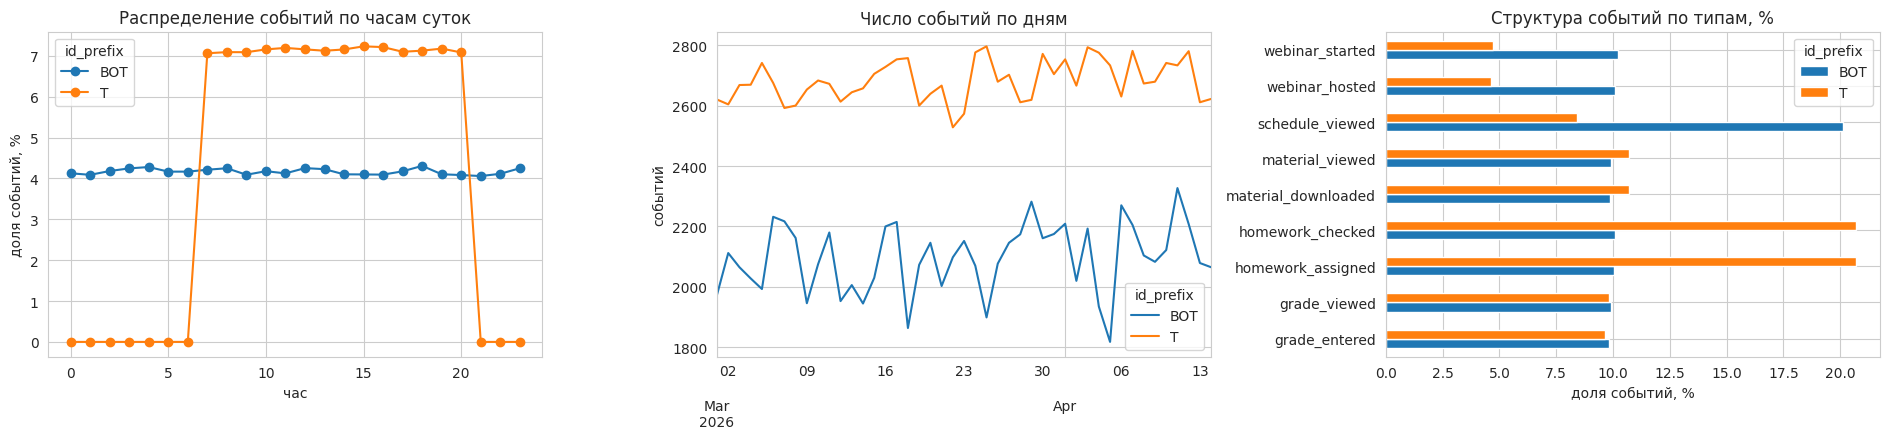

Восстановлено module: 7102, осталось пропусков: 0

Минут, в которые у учителя больше одного события: 297
  все события одного типа:  71
  события разных типов:     226
Удалено дубликатов (пользователь + время + тип события): 71

Уникальных школ с учётом региона: 1191 (номеров без учёта региона: 383)

Итоги очистки:


,шаг,строк,учителей,потеряно строк,"доля от исходных, %"
0,исходные данные,214959,1515,0,100.00
1,без BOT-аккаунтов,120668,1500,94291,56.14
2,без дубликатов,120597,1500,71,56.10


,user_id,timestamp,event_type,module,session_id,region,school_id,date,hour,is_night,is_weekend,gap_min,school_key
94291,T100000,2026-03-03 13:05:00,webinar_hosted,Вебинары,S40,Уфа,277,2026-03-03,13,False,False,NaN,Уфа_277
94292,T100000,2026-03-03 16:01:00,schedule_viewed,Расписание,S40,Уфа,277,2026-03-03,16,False,False,176.0,Уфа_277
94293,T100000,2026-03-03 18:14:00,webinar_hosted,Вебинары,S10,Уфа,277,2026-03-03,18,False,False,133.0,Уфа_277


In [3]:
# Очистка данных: служебные аккаунты, пропуски, дубликаты.
#
# Перед удалением BOT-аккаунтов проверяем, что они действительно ведут себя
# не как люди: формальных маркеров (общая сессия, точность до секунды)
# недостаточно для вывода, что это парсеры, а не, например, сотрудники
# поддержки. Сравниваем поведенческий профиль по нескольким метрикам.

logs['date'] = logs['timestamp'].dt.normalize()
logs['hour'] = logs['timestamp'].dt.hour
logs['is_night'] = logs['hour'] < 6                     # 00:00–05:59
logs['is_weekend'] = logs['timestamp'].dt.dayofweek >= 5

# Интервал между соседними событиями одного аккаунта, мин.
logs = logs.sort_values(['user_id', 'timestamp']).reset_index(drop=True)
logs['gap_min'] = (logs.groupby('user_id')['timestamp'].diff()
                       .dt.total_seconds() / 60)

# --- 1. Поведенческий профиль: боты против учителей ---
beh = logs.groupby('user_id').agg(
    id_prefix=('id_prefix', 'first'),
    events=('event_type', 'size'),
    active_days=('date', 'nunique'),
    night_share=('is_night', 'mean'),
    weekend_share=('is_weekend', 'mean'),
    median_gap_min=('gap_min', 'median'),
    event_types=('event_type', 'nunique'),
)
beh['events_per_day'] = beh['events'] / beh['active_days']

print('Медианные значения метрик по типам аккаунтов:')
display(beh.groupby('id_prefix').median(numeric_only=True).round(3).T)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.5))

# Распределение событий по часам суток (доля событий типа аккаунта).
hourly = pd.crosstab(logs['hour'], logs['id_prefix'], normalize='columns') * 100
hourly.plot(ax=axes[0], marker='o')
axes[0].set_title('Распределение событий по часам суток')
axes[0].set_xlabel('час')
axes[0].set_ylabel('доля событий, %')

# Динамика по дням: у людей ожидаем недельный цикл, у скриптов — ровный поток.
daily = pd.crosstab(logs['date'], logs['id_prefix'])
daily.plot(ax=axes[1])
axes[1].set_title('Число событий по дням')
axes[1].set_xlabel('')
axes[1].set_ylabel('событий')

# Структура событий: боты перебирают события равномерно или как люди?
mix = pd.crosstab(logs['event_type'], logs['id_prefix'], normalize='columns') * 100
mix.plot.barh(ax=axes[2])
axes[2].set_title('Структура событий по типам, %')
axes[2].set_xlabel('доля событий, %')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show()

# --- 2. Исключение служебных аккаунтов ---
# Фиксируем потери на каждом шаге очистки: строки и учителя.
steps = [('исходные данные', len(logs), logs['user_id'].nunique())]

clean = logs[logs['id_prefix'] == 'T'].copy()
steps.append(('без BOT-аккаунтов', len(clean), clean['user_id'].nunique()))

# --- 3. Восстановление module по типу события ---
# Соответствие тип события → модуль однозначно (проверено выше),
# а пропуски распределены равномерно по типам аккаунтов и дням —
# это технический сбой записи, а не особый тип событий.
event_to_module = mod_by_event['first'].to_dict()
n_miss = clean['module'].isna().sum()
clean['module'] = clean['module'].fillna(clean['event_type'].map(event_to_module))
print(f'Восстановлено module: {n_miss}, осталось пропусков: {clean["module"].isna().sum()}')

# --- 4. Дубликаты ---
# Сколько раз у учителя в одну минуту оказывается несколько событий —
# одного типа и разных типов. Если события разных типов в одну минуту
# почти не совпадают, то совпадения одного типа — не случайность
# активной работы, а двойная запись одного события.
per_minute = clean.groupby(['user_id', 'timestamp'])['event_type'].agg(['size', 'nunique'])
per_minute = per_minute[per_minute['size'] > 1]
print(f'\nМинут, в которые у учителя больше одного события: {len(per_minute)}')
print(f'  все события одного типа:  {(per_minute["nunique"] == 1).sum()}')
print(f'  события разных типов:     {(per_minute["nunique"] > 1).sum()}')

# session_id не описывает визит (см. выше: сессия длится неделями
# и бывает общей для двух учителей), поэтому строки, различающиеся
# только им, описывают одно и то же событие.
before = len(clean)
clean = clean.drop_duplicates(subset=['user_id', 'timestamp', 'event_type'])
print(f'Удалено дубликатов (пользователь + время + тип события): {before - len(clean)}')
steps.append(('без дубликатов', len(clean), clean['user_id'].nunique()))

# --- 5. Ключ школы ---
# Номер школы повторяется в разных регионах (350 из 383 номеров), то есть
# это номер внутри региона. Уникальная школа — пара «регион + номер».
clean['school_key'] = clean['region'] + '_' + clean['school_id'].astype(str)
print(f'\nУникальных школ с учётом региона: {clean["school_key"].nunique()} '
      f'(номеров без учёта региона: {clean["school_id"].nunique()})')

# Служебные столбцы диагностики больше не нужны.
clean = clean.drop(columns=['ts_second', 'id_prefix', 'id_number',
                            'm_sbot', 'm_school1', 'm_seconds'])

report = pd.DataFrame(steps, columns=['шаг', 'строк', 'учителей'])
report['потеряно строк'] = (report['строк'].shift() - report['строк']).fillna(0).astype(int)
report['доля от исходных, %'] = (report['строк'] / report['строк'].iloc[0] * 100).round(2)
print('\nИтоги очистки:')
display(report)
display(clean.head(3))

### Выводы по очистке данных

**BOT-аккаунты — скрипты, а не люди.** Поведенческое сравнение подтверждает
решение об их исключении по всем метрикам:

| Метрика (медиана по аккаунтам) | BOT | Учителя |
|---|---|---|
| событий за 45 дней | 6 288 | 47 |
| активных дней из 45 | 45 | 17 |
| событий в активный день | 139.7 | 2.8 |
| пауза между событиями, мин | 6.9 | 265 |
| доля событий с 0 до 6 часов | 25.2% | 0% |

- **Часы суток.** Активность ботов равномерна по всем 24 часам: около 4.2%
  событий в час, то есть 100/24. Учителя работают строго с 7:00 до 21:00,
  ночью и поздно вечером у них нет ни одного события.
- **Состав событий.** У ботов на каждый тип события приходится ровно 10%,
  а на просмотр расписания — 20%. Бот равновероятно выбирает модуль
  (5 модулей по 20%), а затем событие внутри модуля. У учителей структура
  неравномерная: на домашние задания приходится 41% событий, на вебинары —
  около 9%. Это профиль реального использования.
- **Динамика по дням.** Боты дают от 1 800 до 2 330 событий в день
  с резкими скачками. Учителя дают от 2 530 до 2 800 событий в день.

Исключены 94 291 событие ботов, 43.86% лога.

**Особенности активности учителей.** Внутри интервала 7:00–21:00 события
распределены почти равномерно, около 7.1% в час, без утреннего или
вечернего пика. Недельного цикла тоже нет: доля событий в выходные равна
28.6%, то есть ровно 2/7, как при одинаковой активности во все дни недели.
Для школьных учителей это необычно. Учитываем это как особенность
выгрузки: признаки «время суток» и «работа в выходные» вряд ли будут
различать сегменты.

**Пропуски.** Модуль восстановлен по типу события в 7 102 строках
учителей, пропусков не осталось.

**Дубликаты.** Удалена 71 строка, которая совпадает с другой строкой
по учителю, времени и типу события. Проверка на случайные совпадения
однозначного ответа не дала. В 226 минутах у учителя совпали события
разных типов, то есть несколько действий в одну минуту действительно
бывают. Если бы типы событий выбирались независимо, при структуре событий
учителей пар одного типа ожидалось бы примерно в 6 раз меньше,
чем разнотипных, — около 36. Наблюдается 71, вдвое больше. Значит, часть
совпадений — двойная запись (как в примере, где одно событие записано
в двух `session_id`), а часть может быть реальными повторными действиями.
На метрики это не влияет: удалено 0.06% событий учителей.

**Школы.** С учётом региона получилась 1 191 уникальная школа,
а не 383 номера.

**Итог очистки.** Осталось 120 597 событий 1 500 учителей, 56.1% исходного
лога. Удалены только служебные события и дубликаты, ни один учитель
не исключён.

### 2.3. Активность учителей: аномалии, неактивные учителя и визиты

,events,active_days,events_per_day,max_events_day,lifetime_days
count,1500.00,1500.00,1500.00,1500.00,1500.00
mean,80.40,19.37,3.51,5.25,40.37
std,70.54,10.62,1.46,2.02,6.14
min,1.00,1.00,1.00,1.00,1.00
1%,4.99,3.00,1.37,2.00,15.99
5%,9.00,5.00,1.75,3.00,28.00
25%,32.00,11.00,2.30,4.00,39.00
50%,47.00,17.00,2.77,4.00,43.00
75%,167.00,31.00,5.20,8.00,44.00
95%,202.05,37.00,5.78,8.00,45.00


Учителей с аномально высокими значениями (робастная z > 3.5):
events            0
events_per_day    0
max_events_day    0

Учителей с малой активностью:
  событий <= 1       1   активных дней <= 1       2
  событий <= 2       1   активных дней <= 2      11
  событий <= 3       3   активных дней <= 3      30
  событий <= 5      25   активных дней <= 5     112
  событий <= 10     97   активных дней <= 10    374

Пауз внутри дня: 91542 (из 119097 интервалов между событиями)
Пауза внутри дня, мин: {'count': 91542.0, 'mean': 141.6, 'std': 130.0, 'min': 0.0, '25%': 44.0, '50%': 103.0, '75%': 201.0, 'max': 825.0}
  доля пауз короче  5 мин:   2.7%
  доля пауз короче 15 мин:   8.9%
  доля пауз короче 30 мин:  17.6%
  доля пауз короче 60 мин:  32.7%

При паузе 30 мин: визитов на учителя — медиана 43, событий на визит — медиана 1.10; визитов на активный день — медиана 2.59


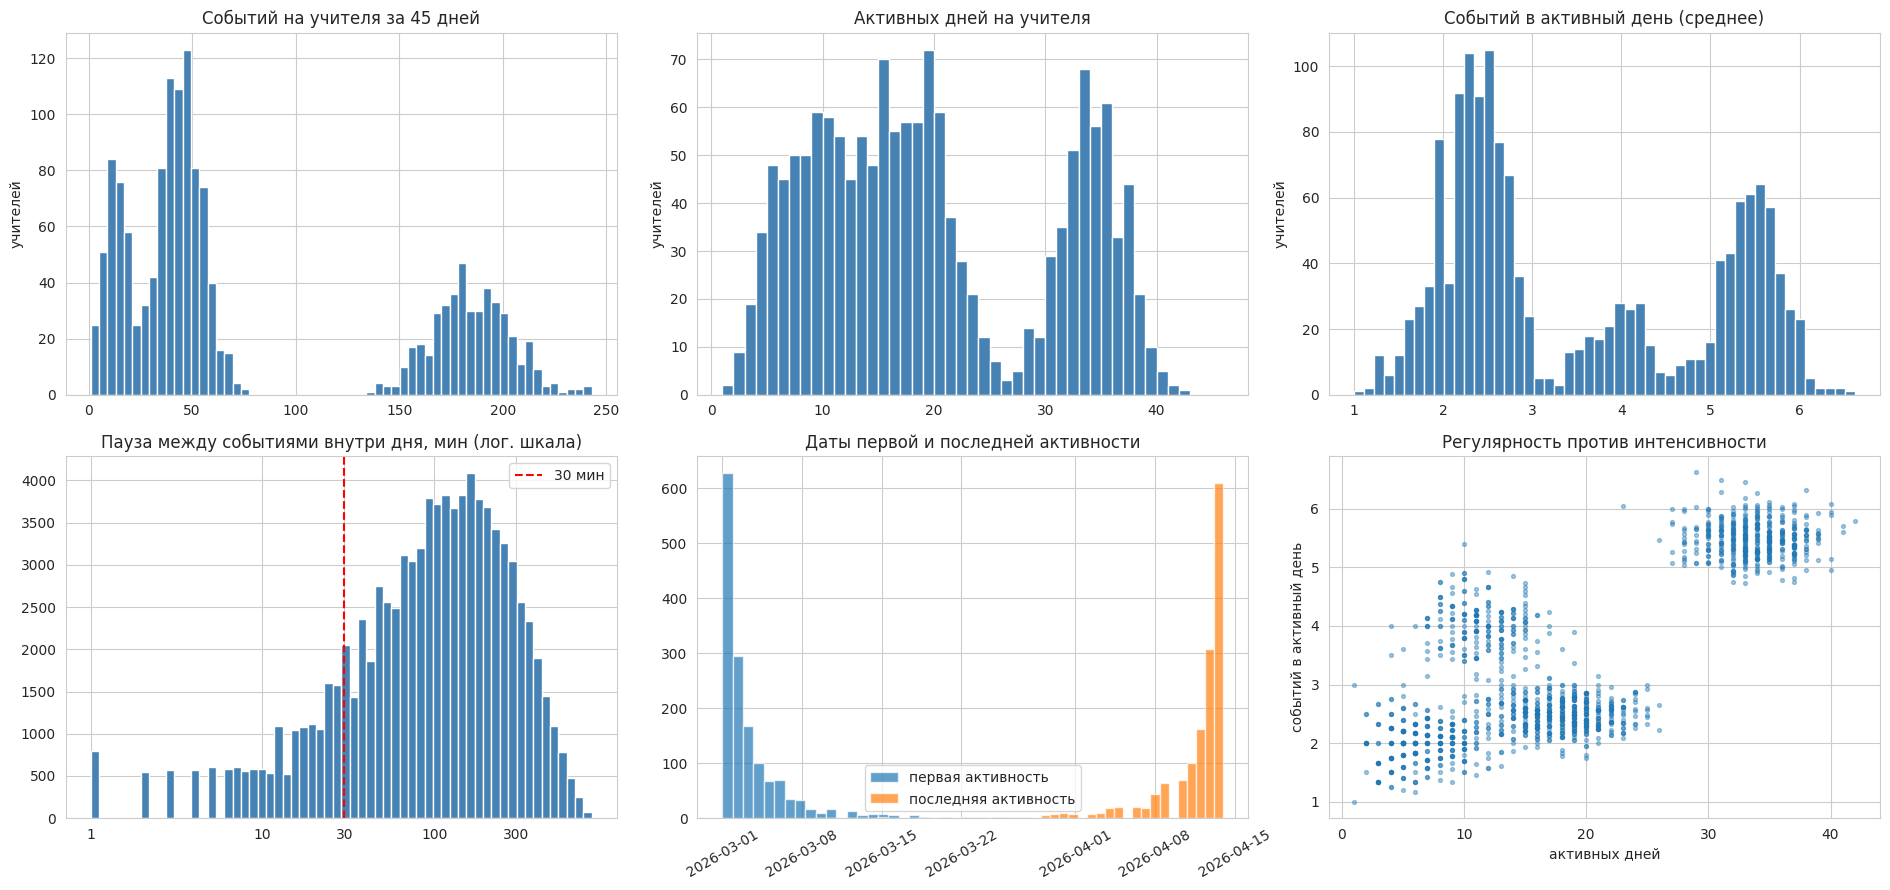

In [4]:
# Активность учителей: аномалии, неактивные учителя и единица «визита».
#
# После удаления ботов нужно проверить сами T-аккаунты:
#   1) нет ли среди них аномально активных (парсер под видом учителя);
#   2) сколько учителей почти не пользовались платформой — по одному-двум
#      событиям поведенческий профиль не построить;
#   3) можно ли восстановить визиты по паузам между событиями,
#      раз session_id для этого непригоден.

t = clean.sort_values(['user_id', 'timestamp']).copy()

# Интервалы пересчитываем: после удаления дубликатов соседние строки сменились.
t['gap_min'] = t.groupby('user_id')['timestamp'].diff().dt.total_seconds() / 60
same_day = t['date'].eq(t.groupby('user_id')['date'].shift())
t['gap_same_day'] = t['gap_min'].where(same_day)     # паузы внутри одного дня

# --- 1. Профиль активности учителя ---
day_counts = t.groupby(['user_id', 'date']).size()
teach = t.groupby('user_id').agg(
    events=('event_type', 'size'),
    active_days=('date', 'nunique'),
    first_day=('date', 'min'),
    last_day=('date', 'max'),
)
teach['events_per_day'] = teach['events'] / teach['active_days']
teach['max_events_day'] = day_counts.groupby('user_id').max()
teach['lifetime_days'] = (teach['last_day'] - teach['first_day']).dt.days + 1

num_cols = ['events', 'active_days', 'events_per_day', 'max_events_day', 'lifetime_days']
display(teach[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))

# --- 2. Аномально высокая активность ---
# Распределения скошены вправо, поэтому выбросы ищем по логарифму
# и робастной z-оценке (медиана и MAD устойчивы к самим выбросам,
# в отличие от среднего и стандартного отклонения).
def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad

flags = pd.DataFrame({c: robust_z(np.log1p(teach[c])) > 3.5
                      for c in ['events', 'events_per_day', 'max_events_day']})
print('Учителей с аномально высокими значениями (робастная z > 3.5):')
print(flags.sum().to_string())
outliers = teach[flags.any(axis=1)]
if len(outliers):
    display(outliers.sort_values('max_events_day', ascending=False).head(15))

# --- 3. Низкая активность ---
print('\nУчителей с малой активностью:')
for n in [1, 2, 3, 5, 10]:
    print(f'  событий <= {n:<3} {(teach["events"] <= n).sum():>5}   '
          f'активных дней <= {n:<3} {(teach["active_days"] <= n).sum():>5}')

# --- 4. Паузы между событиями и восстановление визитов ---
# Визит обычно выделяют по паузе бездействия (стандарт веб-аналитики —
# 30 минут). Это имеет смысл, только если короткие паузы образуют
# отдельную группу: события внутри визита идут плотно, между визитами — редко.
gaps = t['gap_same_day'].dropna()
print(f'\nПауз внутри дня: {len(gaps)} '
      f'(из {t["gap_min"].notna().sum()} интервалов между событиями)')
print('Пауза внутри дня, мин:', gaps.describe().round(1).to_dict())
for thr in [5, 15, 30, 60]:
    print(f'  доля пауз короче {thr:>2} мин: {(gaps < thr).mean() * 100:5.1f}%')

SESSION_GAP_MIN = 30
t['new_visit'] = t['gap_same_day'].isna() | (t['gap_same_day'] > SESSION_GAP_MIN)
teach['visits_30'] = t.groupby('user_id')['new_visit'].sum()
print(f'\nПри паузе {SESSION_GAP_MIN} мин: визитов на учителя — медиана '
      f'{teach["visits_30"].median():.0f}, событий на визит — медиана '
      f'{(teach["events"] / teach["visits_30"]).median():.2f}; '
      f'визитов на активный день — медиана '
      f'{(teach["visits_30"] / teach["active_days"]).median():.2f}')

# --- 5. Визуализация ---
fig, axes = plt.subplots(2, 3, figsize=(19, 9))

axes[0, 0].hist(teach['events'], bins=60, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Событий на учителя за 45 дней')
axes[0, 0].set_ylabel('учителей')

axes[0, 1].hist(teach['active_days'], bins=range(1, 47), color='steelblue',
                edgecolor='white')
axes[0, 1].set_title('Активных дней на учителя')

axes[0, 2].hist(teach['events_per_day'], bins=50, color='steelblue', edgecolor='white')
axes[0, 2].set_title('Событий в активный день (среднее)')

axes[1, 0].hist(np.log10(gaps.clip(lower=1)), bins=60, color='steelblue',
                edgecolor='white')
axes[1, 0].axvline(np.log10(SESSION_GAP_MIN), color='red', ls='--',
                   label=f'{SESSION_GAP_MIN} мин')
axes[1, 0].set_xticks([0, 1, np.log10(30), 2, np.log10(300)])
axes[1, 0].set_xticklabels(['1', '10', '30', '100', '300'])
axes[1, 0].set_title('Пауза между событиями внутри дня, мин (лог. шкала)')
axes[1, 0].legend()

axes[1, 1].hist(teach['first_day'], bins=45, alpha=0.7, label='первая активность')
axes[1, 1].hist(teach['last_day'], bins=45, alpha=0.7, label='последняя активность')
axes[1, 1].set_title('Даты первой и последней активности')
axes[1, 1].legend()
axes[1, 1].tick_params(axis='x', rotation=30)

axes[1, 2].scatter(teach['active_days'], teach['events_per_day'], s=8, alpha=0.4)
axes[1, 2].set_title('Регулярность против интенсивности')
axes[1, 2].set_xlabel('активных дней')
axes[1, 2].set_ylabel('событий в активный день')

for ax in axes[0]:
    ax.set_ylabel('учителей')
plt.tight_layout()
plt.show()

### Выводы по активности учителей

**Аномально активных учителей нет.** Максимум — 243 события за 45 дней
и 8 событий в день. Робастная z-оценка (по логарифму, порог 3.5)
не выделила ни одного учителя ни по одной метрике. Парсеров под видом
учителей нет: вся аномальная активность приходилась на BOT-аккаунты.

**Малоактивные учителя.** У одного учителя всего одно событие, 11 учителей
активны не более двух дней, 30 — не более трёх. По одному-двум дням нельзя
судить о регулярности. Доли модулей по нескольким событиям случайны:
одно событие даёт 100% в одном модуле. Такие профили сформировали бы ложные
«кластеры». Поэтому учителя, у которых меньше 3 активных дней
(11 человек, 0.7%), не участвуют в обучении моделей. После обучения
они получат сегмент по ближайшему центру, так что для продукта
никто не потеряется.

**Визиты по паузам не восстанавливаются.** На логарифмической шкале
распределение пауз внутри дня одномодальное, с центром около
100–150 минут. Отдельной группы коротких пауз, которая образовала бы
визиты, нет. Короче 30 минут лишь 17.6% пауз, медиана — 103 минуты.
При стандартном пороге в 30 минут на визит в медиане приходится
1.1 события, то есть почти каждое действие оказалось бы отдельным
визитом, и «визит» просто дублировал бы число событий. Поэтому единицей
визита служит активный день. Частоту использования описываем через
активные дни и число событий в активный день. Это совпадает
с продуктовой метрикой заказчика — числом активных дней в месяц.

**Структура активности — первые признаки сегментов.** Распределения
многомодальны:

- событий на учителя за 45 дней: три группы — около 10–20, около 40–55
  и 150–220;
- активных дней: две группы — 5–22 и 30–40;
- событий в активный день: три пика — около 2.4, около 4 и около 5.5.

На диаграмме «регулярность против интенсивности» видны как минимум
три облака:

1. 28–42 активных дня и 5–6 событий в день: ежедневная интенсивная работа;
2. 3–25 дней и 1.5–3 события в день: самая многочисленная группа,
   эпизодическое использование;
3. 5–17 дней и 3–5 событий в день: редкие, но насыщенные визиты.

Значит, сегменты в данных есть и хорошо разделяются уже по двум метрикам.
Что делает каждая группа, покажет структура использования модулей.

**Удержание внутри периода.** Большинство учителей впервые активны
в первые дни марта, а последний раз — в последние дни выгрузки. Медианный
срок активности составляет 43 дня из 45, у 95% учителей — не меньше
28 дней. Заметного оттока внутри периода нет. Хвосты распределений
(первая активность во второй половине марта, последняя в начале апреля)
объясняются скорее редкими визитами малоактивных учителей, чем реальным
приходом или уходом. Это важно для оценки давности последней активности
(recency): у учителя, который заходит раз в 4–5 дней, пауза в 5 дней —
норма, а не признак ухода.

## 3. Продуктовые метрики платформы

Учителей в очищенных данных: 1500
DAU: среднее 646, мин 610, макс 688 (43.0% учителей в среднем за день)
WAU (полные недели): среднее 1356, мин 1341, макс 1362
MAU (март): 1498 (99.9% учителей)
Stickiness DAU/MAU (март): 43.0%

Активных дней в марте на учителя: среднее 13.3, медиана 12
{'count': 1498.0, 'mean': 13.3, 'std': 7.4, 'min': 1.0, '10%': 4.0, '25%': 7.0, '50%': 12.0, '75%': 21.0, '90%': 24.0, 'max': 29.0}

Когорта первой недели: 1360 учителей (90.7%)
Доля когорты, активной в неделю, %: {0: 100.0, 1: 91.2, 2: 92.9, 3: 91.5, 4: 92.9, 5: 92.1}


,"доля событий, %","охват учителей, %"
module,,
Домашние задания,41.4,96.9
Библиотека материалов,21.4,99.2
Оценки,19.5,93.0
Вебинары,9.3,91.5
Расписание,8.4,97.9


Число модулей, которыми пользуется учитель: {1: 1, 2: 6, 3: 46, 4: 209, 5: 1238}


,модуль,событие,учителей (n>=10),средняя доля,std доли,std при случайности
0,Домашние задания,homework_checked,474,0.500,0.061,0.055
1,Библиотека материалов,material_downloaded,988,0.498,0.109,0.106
2,Вебинары,webinar_hosted,427,0.497,0.135,0.124
3,Оценки,grade_entered,457,0.497,0.085,0.076


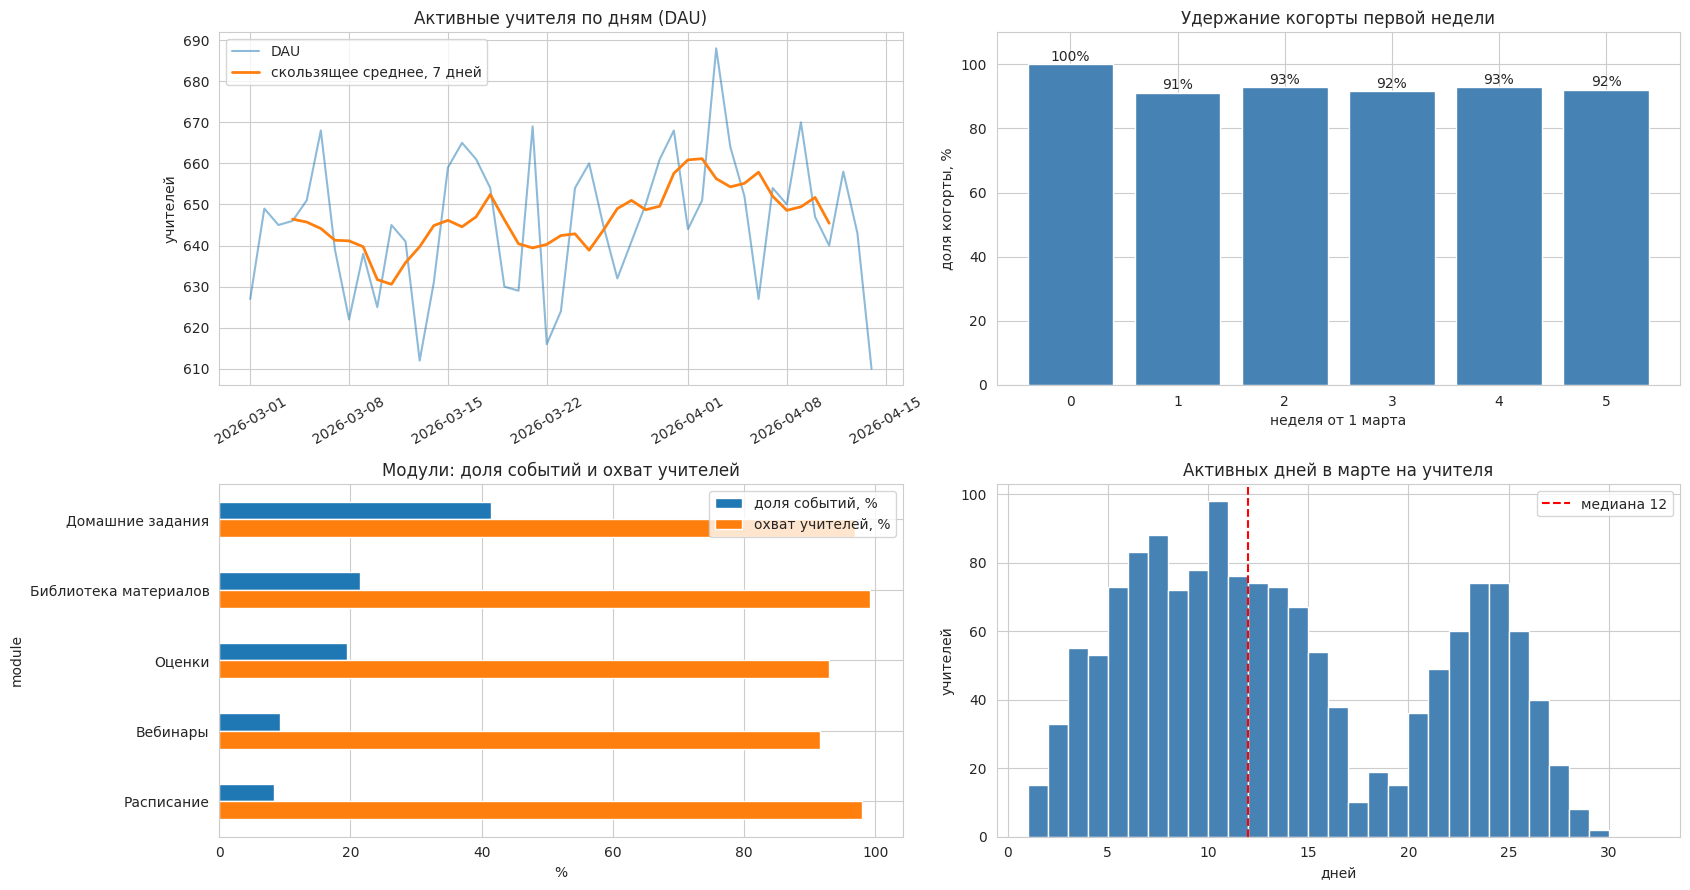

In [5]:
# Продуктовые метрики платформы на очищенных данных.
#
# Перед сегментацией фиксируем «точку отсчёта» по метрикам, которые
# заказчик хочет растить: MAU, число активных дней в месяц, удержание.
# Рекомендации по сегментам потом будут опираться на эти значения.
# Единица визита — активный день (визиты по паузам не восстанавливаются).

MODULES = ['Домашние задания', 'Библиотека материалов', 'Оценки',
           'Вебинары', 'Расписание']

start_date = clean['date'].min()
clean['week'] = (clean['date'] - start_date).dt.days // 7     # недели от 1 марта
n_teachers = clean['user_id'].nunique()

# --- 1. DAU, WAU, MAU и «липкость» ---
dau = clean.groupby('date')['user_id'].nunique()
march = clean[clean['date'].dt.month == 3]
mau_march = march['user_id'].nunique()
dau_march = dau[dau.index.month == 3]

# Полные недели: 45 дней = 6 полных недель + 3 дня, неполную неделю
# в недельных метриках не учитываем, чтобы не занижать её значение.
full_weeks = sorted(w for w in clean['week'].unique()
                    if (clean.loc[clean['week'] == w, 'date'].nunique() == 7))
wau = clean[clean['week'].isin(full_weeks)].groupby('week')['user_id'].nunique()

print(f'Учителей в очищенных данных: {n_teachers}')
print(f'DAU: среднее {dau.mean():.0f}, мин {dau.min()}, макс {dau.max()} '
      f'({dau.mean() / n_teachers * 100:.1f}% учителей в среднем за день)')
print(f'WAU (полные недели): среднее {wau.mean():.0f}, мин {wau.min()}, макс {wau.max()}')
print(f'MAU (март): {mau_march} ({mau_march / n_teachers * 100:.1f}% учителей)')
print(f'Stickiness DAU/MAU (март): {dau_march.mean() / mau_march * 100:.1f}%')

# Активные дни в месяц — ключевая метрика заказчика.
days_march = march.groupby('user_id')['date'].nunique()
print(f'\nАктивных дней в марте на учителя: среднее {days_march.mean():.1f}, '
      f'медиана {days_march.median():.0f}')
print(days_march.describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_dict())

# --- 2. Недельное удержание ---
# Почти все учителя впервые активны в первую неделю, поэтому смотрим
# на когорту первой недели: какая её доля возвращается в каждую следующую.
week_users = clean.groupby('week')['user_id'].apply(set)
cohort = week_users[0]
retention = pd.Series({w: len(week_users[w] & cohort) / len(cohort) * 100
                       for w in full_weeks})
print(f'\nКогорта первой недели: {len(cohort)} учителей '
      f'({len(cohort) / n_teachers * 100:.1f}%)')
print('Доля когорты, активной в неделю, %:', retention.round(1).to_dict())

# --- 3. Модули: охват и доля событий ---
by_module = pd.DataFrame({
    'доля событий, %': clean['module'].value_counts(normalize=True) * 100,
    'охват учителей, %': clean.groupby('module')['user_id'].nunique() / n_teachers * 100,
}).loc[MODULES].round(1)
display(by_module)

modules_per_teacher = clean.groupby('user_id')['module'].nunique()
print('Число модулей, которыми пользуется учитель:',
      modules_per_teacher.value_counts().sort_index().to_dict())

# --- 4. Парные события внутри модулей ---
# В четырёх модулях по два события (назначил/проверил ДЗ, посмотрел/скачал
# материал, начал/провёл вебинар, выставил/посмотрел оценку). Если доля
# одного события из пары у учителей колеблется вокруг 50% только из-за
# случайности, то события внутри модуля поведение не различают и признаки
# достаточно строить на уровне модулей.
pairs = {
    'Домашние задания': 'homework_checked',
    'Библиотека материалов': 'material_downloaded',
    'Вебинары': 'webinar_hosted',
    'Оценки': 'grade_entered',
}
rows = []
for module, ev in pairs.items():
    m = clean[clean['module'] == module]
    g = m.groupby('user_id')['event_type'].agg(n='size', k=lambda s: (s == ev).sum())
    g = g[g['n'] >= 10]                       # доля по 1–2 событиям неинформативна
    share = g['k'] / g['n']
    # Ожидаемый разброс доли при чисто случайном выборе 50/50: sqrt(0.25 / n).
    expected_std = np.sqrt(0.25 / g['n']).mean()
    rows.append({'модуль': module, 'событие': ev, 'учителей (n>=10)': len(g),
                 'средняя доля': share.mean(), 'std доли': share.std(),
                 'std при случайности': expected_std})
display(pd.DataFrame(rows).round(3))

# --- 5. Визуализация ---
fig, axes = plt.subplots(2, 2, figsize=(17, 9))

axes[0, 0].plot(dau.index, dau.values, alpha=0.5, label='DAU')
axes[0, 0].plot(dau.index, dau.rolling(7, center=True).mean(), lw=2,
                label='скользящее среднее, 7 дней')
axes[0, 0].set_title('Активные учителя по дням (DAU)')
axes[0, 0].set_ylabel('учителей')
axes[0, 0].legend()
axes[0, 0].tick_params(axis='x', rotation=30)

axes[0, 1].bar(retention.index, retention.values, color='steelblue')
for w, v in retention.items():
    axes[0, 1].text(w, v + 1, f'{v:.0f}%', ha='center')
axes[0, 1].set_title('Удержание когорты первой недели')
axes[0, 1].set_xlabel('неделя от 1 марта')
axes[0, 1].set_ylabel('доля когорты, %')
axes[0, 1].set_ylim(0, 110)

by_module.plot.barh(ax=axes[1, 0])
axes[1, 0].set_title('Модули: доля событий и охват учителей')
axes[1, 0].set_xlabel('%')
axes[1, 0].invert_yaxis()

axes[1, 1].hist(days_march, bins=range(1, 33), color='steelblue', edgecolor='white')
axes[1, 1].axvline(days_march.median(), color='red', ls='--',
                   label=f'медиана {days_march.median():.0f}')
axes[1, 1].set_title('Активных дней в марте на учителя')
axes[1, 1].set_xlabel('дней')
axes[1, 1].set_ylabel('учителей')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

### Выводы по продуктовым метрикам

| Метрика | Значение |
|---|---|
| DAU, среднее | 646 учителей, 43.0% базы (диапазон 610–688) |
| WAU, полные недели | 1 356, 90.4% |
| MAU, март | 1 498, 99.9% |
| Stickiness DAU/MAU, март | 43.0% |
| Активных дней в марте на учителя | среднее 13.3, медиана 12 |
| Недельное удержание когорты первой недели | 91–93% |

**Охват почти полный, а вовлечённость — нет.** В марте платформой
пользовались 1 498 из 1 500 учителей: MAU уже на потолке, и растить его
некуда. Резерв роста — частота использования. В среднем учитель активен
13 дней из 31 (stickiness 43%), поэтому основная продуктовая метрика
для роста — число активных дней в месяц.

**Активные дни распределены двугорбо.** Основная масса учителей активна
3–16 дней в месяц, вторая группа — 20–28 дней. Медиана 12 соответствует
«среднему учителю», которого в данных почти нет: она попадает на границу
между двумя режимами использования.

**Удержание стабильное.** Когорта первой недели — 1 360 учителей (90.7%).
В каждую следующую неделю возвращаются 91–93% когорты, без снижения
к концу периода. DAU колеблется в коридоре 610–688 без тренда и без
недельного цикла. На горизонте 45 дней отток не проявляется. Продуктовая
задача не в том, чтобы остановить уход, а в том, чтобы перевести
эпизодических учителей в регулярные.

**Модули.** Охват всех модулей высокий (91.5–99.2%), а 1 238 учителей
(82.5%) пользуются всеми пятью. Учителя различаются не тем, какими
модулями пользуются, а тем, насколько интенсивно. Бинарные признаки
«пользуется модулем» сегменты не разделят, нужны доли.

| Модуль | Доля событий | Охват учителей | Учителей с 10+ событиями в модуле |
|---|---|---|---|
| Домашние задания | 41.4% | 96.9% | 474 |
| Библиотека материалов | 21.4% | 99.2% | 988 |
| Оценки | 19.5% | 93.0% | 457 |
| Вебинары | 9.3% | 91.5% | 427 |

На домашние задания приходится 41% всех событий, но 10 и больше событий
в этом модуле только у 474 учителей. То же с оценками и вебинарами.
Библиотекой интенсивно пользуются почти вдвое больше учителей. Значит,
ДЗ, оценки и вебинары сосредоточены в отдельных группах учителей. Это
прямая подсказка, по каким признакам будут различаться сегменты.

**Парные события внутри модулей не различают учителей.** Доля одного
события из пары («проверил ДЗ» среди событий ДЗ, «скачал» среди событий
библиотеки и т.д.) в среднем равна 0.497–0.500. Её разброс между
учителями (std 0.061–0.135) почти совпадает с ожидаемым при случайном
выборе 50/50 (0.055–0.124). Поэтому признаки структуры строим на уровне
модулей, а не отдельных событий.

## 4. Признаки для сегментации

### 4.1. Матрица «учитель — продуктовые метрики»

Учителей всего: 1500, в обучении: 1489, исключено (< 3 активных дней): 11
Пропусков в признаках-кандидатах у учителей для обучения: 0


,active_days_month,events_per_day,gap_cv,share_hw,share_lib,share_grade,share_web,share_sched,modules_per_day,events,recency_days,max_break_days
count,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000,1489.000
mean,13.000,3.523,0.671,0.256,0.333,0.144,0.134,0.132,2.082,80.964,2.269,7.713
std,7.034,1.462,0.221,0.206,0.256,0.103,0.180,0.086,0.503,70.493,3.672,4.650
min,2.000,1.167,0.000,0.000,0.000,0.000,0.000,0.000,1.000,4.000,0.000,1.000
5%,3.333,1.750,0.364,0.032,0.061,0.000,0.000,0.032,1.400,10.000,0.000,3.000
25%,7.333,2.312,0.514,0.093,0.102,0.056,0.038,0.059,1.643,33.000,0.000,4.000
50%,11.333,2.778,0.650,0.151,0.214,0.118,0.058,0.122,2.000,47.000,1.000,7.000
75%,20.667,5.200,0.798,0.515,0.610,0.236,0.105,0.184,2.594,167.000,3.000,10.000
95%,24.667,5.778,1.054,0.586,0.725,0.294,0.576,0.286,2.806,202.600,10.000,17.000
max,28.000,6.621,1.619,0.653,0.917,0.625,0.750,0.750,3.600,243.000,32.000,30.000


Доля событий в выходные: среднее 0.288 (2/7 = 0.286), std 0.117, std при случайности 0.070


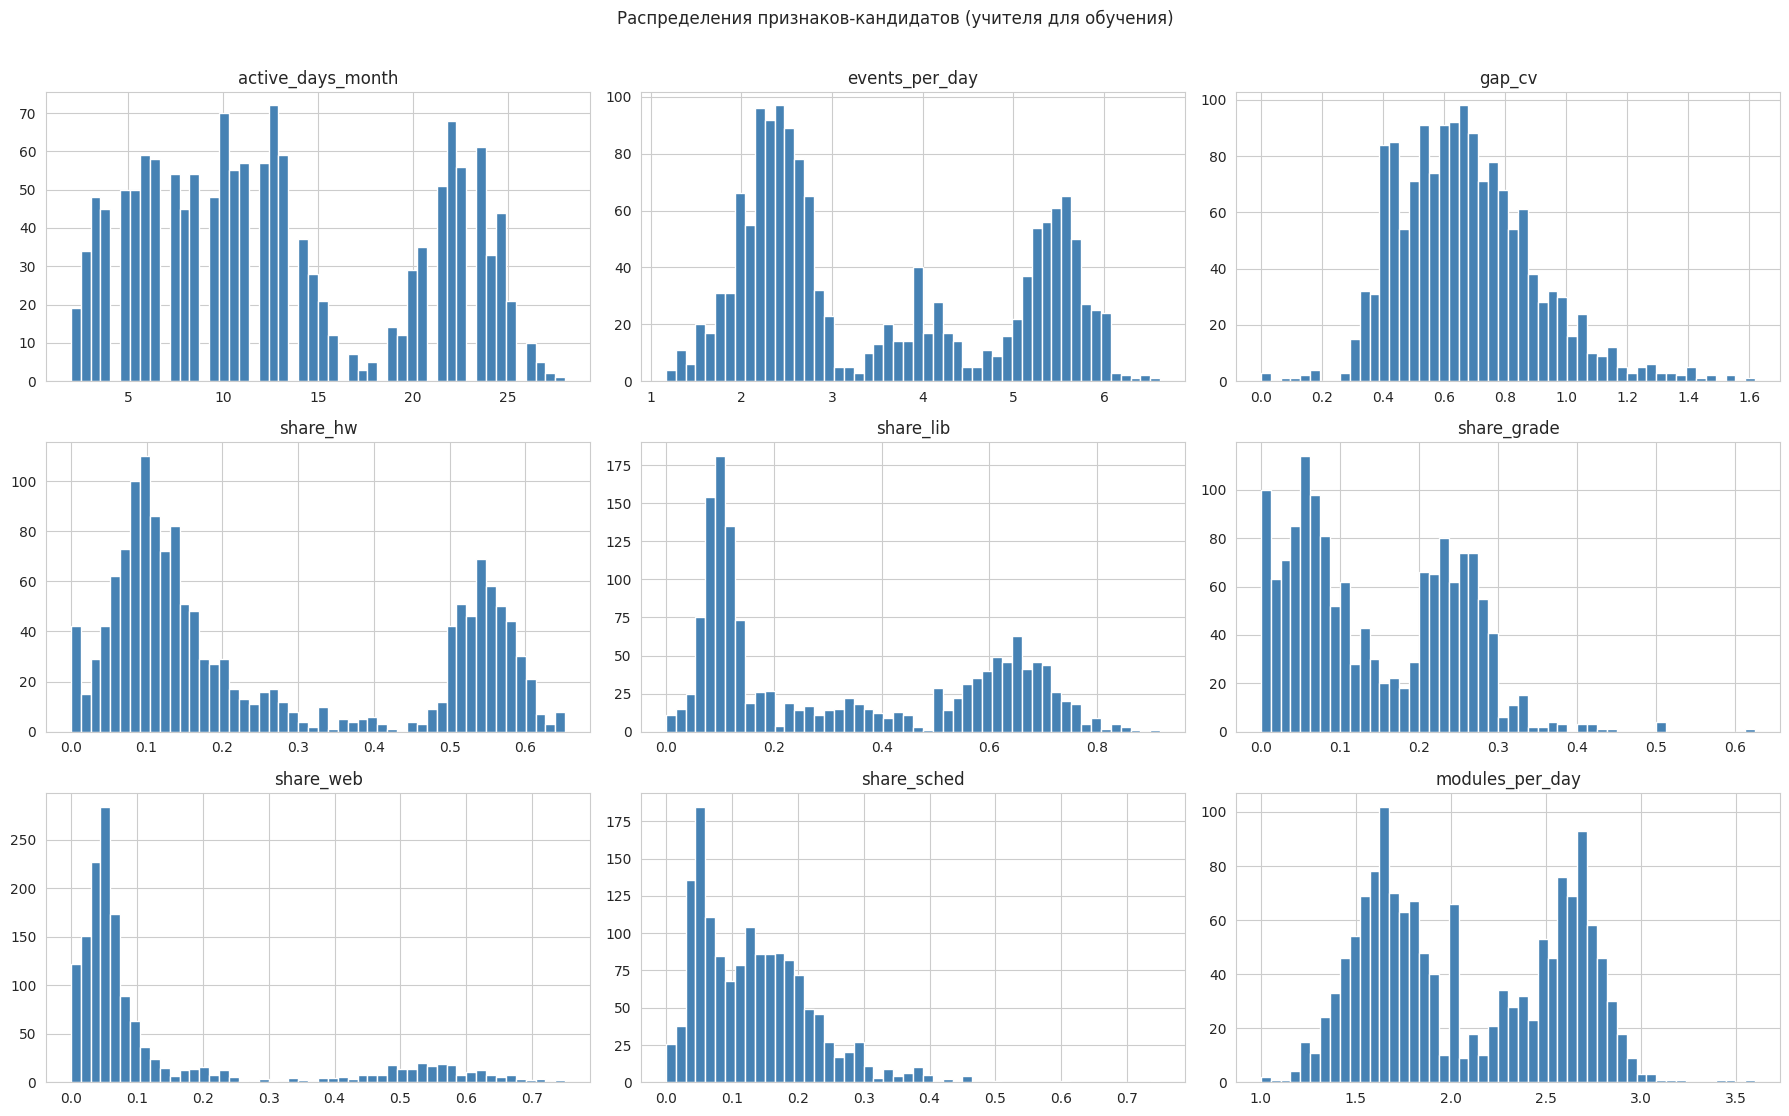

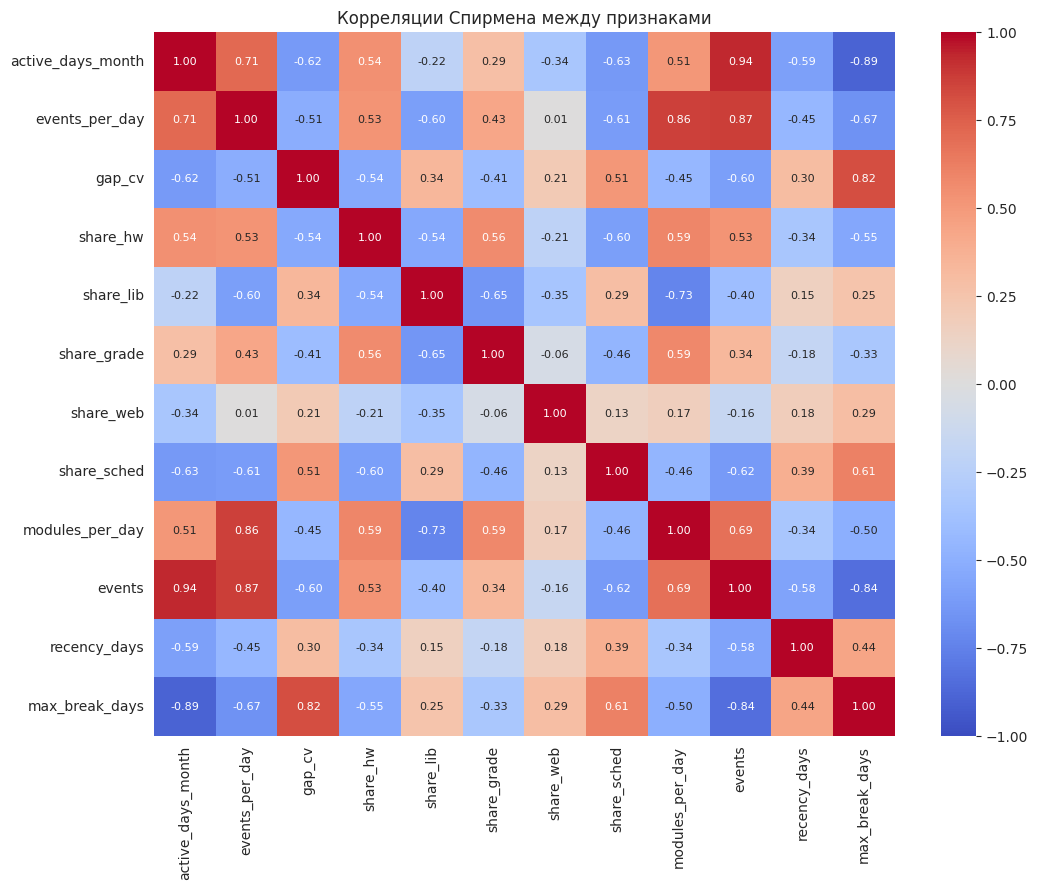

In [6]:
# Матрица «учитель — продуктовые метрики».
#
# Признаки строим в трёх группах, которые описывают разные стороны поведения:
#   1) регулярность и интенсивность — как часто и как плотно учитель работает;
#   2) структура использования — доли событий по модулям (в долях, а не
#      в штуках, чтобы отделить «что делает» от «сколько делает»);
#   3) глубина визита — сколько разных модулей задействовано за день.
# События внутри модуля не разделяем: парные события («назначил/проверил»
# и т.п.) делятся у каждого учителя 50/50 с чисто случайным разбросом.
# Регион, школа, даты и общий объём событий — для профилирования, не для модели.

END_DATE = clean['date'].max()
PERIOD_DAYS = (END_DATE - start_date).days + 1          # 45
MIN_ACTIVE_DAYS = 3                                     # порог участия в обучении
MODULE_CODES = {'Домашние задания': 'hw', 'Библиотека материалов': 'lib',
                'Оценки': 'grade', 'Вебинары': 'web', 'Расписание': 'sched'}

g = clean.groupby('user_id')
feat = pd.DataFrame({
    'region': g['region'].first(),
    'school_key': g['school_key'].first(),
    'events': g.size(),
    'active_days': g['date'].nunique(),
    'first_day': g['date'].min(),
    'last_day': g['date'].max(),
    'n_modules': g['module'].nunique(),
    'weekend_share': g['is_weekend'].mean(),
})

# --- 1. Регулярность и интенсивность ---
# Активные дни нормируем на 30 дней: так признак сразу читается как
# продуктовая метрика заказчика «активных дней в месяц».
feat['active_days_month'] = feat['active_days'] / PERIOD_DAYS * 30
feat['events_per_day'] = feat['events'] / feat['active_days']
feat['recency_days'] = (END_DATE - feat['last_day']).dt.days

# Ритм: паузы между соседними активными днями. Средняя пауза почти
# однозначно задаётся числом активных дней, поэтому информативен
# коэффициент вариации — ровный ритм (CV около 0) против «рывков» (CV > 1).
act_days = (clean[['user_id', 'date']].drop_duplicates()
            .sort_values(['user_id', 'date']))
act_days['gap'] = act_days.groupby('user_id')['date'].diff().dt.days
gap_stat = act_days.groupby('user_id')['gap'].agg(['mean', 'std', 'max'])
feat['gap_mean_days'] = gap_stat['mean']
feat['gap_cv'] = gap_stat['std'] / gap_stat['mean']
feat['max_break_days'] = gap_stat['max']

# --- 2. Структура использования модулей ---
mod_counts = (pd.crosstab(clean['user_id'], clean['module'])
                .reindex(columns=MODULES, fill_value=0))
shares = mod_counts.div(mod_counts.sum(axis=1), axis=0)
shares.columns = ['share_' + MODULE_CODES[c] for c in shares.columns]
feat = feat.join(shares)

# Регулярность работы с модулем: в какой доле активных дней он используется.
# Для профилирования сегментов («в 8 из 10 дней проверяет ДЗ»).
mod_days = (clean.groupby(['user_id', 'module'])['date'].nunique()
                 .unstack().reindex(columns=MODULES).fillna(0))
mod_days = mod_days.div(feat['active_days'], axis=0)
mod_days.columns = ['days_' + MODULE_CODES[c] for c in mod_days.columns]
feat = feat.join(mod_days)

# --- 3. Глубина визита ---
day_modules = clean.groupby(['user_id', 'date'])['module'].nunique()
feat['modules_per_day'] = day_modules.groupby('user_id').mean()

SHARE_COLS = list(shares.columns)
CANDIDATES = (['active_days_month', 'events_per_day', 'gap_cv']
              + SHARE_COLS + ['modules_per_day'])

# --- Учителя для обучения ---
feat['in_model'] = feat['active_days'] >= MIN_ACTIVE_DAYS
print(f'Учителей всего: {len(feat)}, в обучении: {feat["in_model"].sum()}, '
      f'исключено (< {MIN_ACTIVE_DAYS} активных дней): {(~feat["in_model"]).sum()}')
print(f'Пропусков в признаках-кандидатах у учителей для обучения: '
      f'{feat.loc[feat["in_model"], CANDIDATES].isna().sum().sum()}')

fm = feat[feat['in_model']]
display(fm[CANDIDATES + ['events', 'recency_days', 'max_break_days']]
        .describe(percentiles=[.05, .25, .5, .75, .95]).round(3))

# Проверка: различает ли учителей доля событий в выходные. При равномерной
# активности по дням недели доля равна 2/7, а её разброс задаётся
# только числом событий (биномиальная случайность).
p = 2 / 7
print(f'Доля событий в выходные: среднее {fm["weekend_share"].mean():.3f} (2/7 = {p:.3f}), '
      f'std {fm["weekend_share"].std():.3f}, '
      f'std при случайности {np.sqrt(p * (1 - p) / fm["events"]).mean():.3f}')

# --- Распределения кандидатов ---
fig, axes = plt.subplots(3, 3, figsize=(18, 11))
for ax, c in zip(axes.flat, CANDIDATES):
    ax.hist(fm[c].dropna(), bins=50, color='steelblue', edgecolor='white')
    ax.set_title(c)
plt.suptitle('Распределения признаков-кандидатов (учителя для обучения)', y=1.01)
plt.tight_layout()
plt.show()

# --- Корреляции ---
# Спирмен — потому что распределения многомодальны и связи могут быть
# монотонными, но нелинейными.
corr = fm[CANDIDATES + ['events', 'recency_days', 'max_break_days']].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Корреляции Спирмена между признаками')
plt.tight_layout()
plt.show()

### Выводы по матрице признаков

Матрица построена для 1 500 учителей. В обучении участвуют 1 489:
11 учителей с менее чем 3 активными днями исключены. Пропусков
в признаках нет.

**Распределения подтверждают сегментную структуру.** Почти все признаки
многомодальны:

- `share_hw`: две группы — около 0.10 (большинство) и 0.50–0.60;
- `share_lib`: пик около 0.10, широкая группа 0.55–0.75 и промежуточные
  значения 0.20–0.45;
- `share_grade`: две группы — 0–0.15 и 0.20–0.30;
- `share_web`: основная масса около 0.05 и небольшая отдельная группа
  0.40–0.70;
- `events_per_day`: три пика — около 2.4, 4 и 5.5;
- `active_days_month`: две группы — 2–17 и 19–28 дней.

Группы с высокой долей ДЗ, библиотеки и вебинаров совпадают с тремя
типами учителей из описания продукта: работающие с домашними заданиями,
пользующиеся платформой как библиотекой и интерактивные.

**Связи между признаками.**

- Домашние задания и оценки идут вместе (ρ = 0.56): выдача и проверка ДЗ
  и работа с журналом — один сценарий.
- Библиотека противопоставлена оценкам (ρ = −0.65) и домашним заданиям
  (ρ = −0.54): кто готовится к урокам по материалам, тот мало работает
  с ДЗ на платформе.
- Доля расписания выше у редко заходящих учителей (ρ = −0.63
  с активными днями): эпизодический визит часто сводится к просмотру
  расписания.
- Доля вебинаров почти не связана с интенсивностью (ρ = 0.01 с событиями
  в день): интерактивные учителя встречаются при разной активности.

**Отбор признаков для кластеризации.**

| Признак | Решение | Причина |
|---|---|---|
| `active_days_month` | оставлен | регулярность; метрика заказчика |
| `events_per_day` | оставлен | интенсивность визита |
| `share_*` (5 модулей) | оставлены | структура использования |
| `events` | исключён | ρ = 0.94 с активными днями и 0.87 с событиями в день: по сути их произведение |
| `max_break_days` | исключён | ρ = −0.89 с активными днями |
| `modules_per_day` | исключён | ρ = 0.86 с событиями в день: чем больше событий за день, тем больше разных модулей |
| `gap_cv` | исключён | одномодальный, соответствует случайному выбору дней (см. ниже) |
| `weekend_share` | исключён | различие с 2/7 — случайное (проверка в 4.2) |

Подробнее про `gap_cv`. Если учитель заходит в каждый день независимо
с вероятностью p, паузы между активными днями имеют геометрическое
распределение с коэффициентом вариации √(1 − p). Это около 0.8
при 11 активных днях в месяц и около 0.5 при 22. Наблюдаемые значения
(медиана 0.65, от 0.36 до 1.05 у 90% учителей) и их отрицательная связь
с числом активных дней (ρ = −0.62) соответствуют этой модели. Устойчивого
«ритма», который отличал бы одних учителей от других, в данных нет.

Подробнее про `weekend_share`. Первая проверка (std 0.117 против 0.070)
была некорректной. События одного дня все приходятся либо на будни, либо
на выходные, поэтому независимых наблюдений столько, сколько активных
дней, а не событий. Корректный расчёт — в следующей ячейке.

Пять долей модулей в сумме дают 1, то есть линейно зависимы. Для K-Means
и DBSCAN это не препятствие: они не обращают матрицы. Но структура
использования получает вес пяти признаков против двух у активности.
Это соответствует задаче: сегменты в первую очередь должны различаться
тем, как учитель пользуется платформой.

### 4.2. Отбор и масштабирование признаков

In [7]:
# Отбор признаков и масштабирование.
#
# По корреляциям и распределениям из предыдущего шага (обоснование —
# в выводах к разделу 4.1):
#   events          — исключён: ρ = 0.94 с active_days_month и 0.87
#                     с events_per_day, то есть это их произведение;
#   max_break_days  — исключён: ρ = −0.89 с active_days_month;
#   modules_per_day — исключён: ρ = 0.86 с events_per_day — чем больше
#                     событий за день, тем больше разных модулей;
#   gap_cv          — исключён: распределение одномодально, а значения
#                     соответствуют случайному выбору дней (см. выводы);
#   weekend_share   — исключён после проверки ниже.
FEATURES = ['active_days_month', 'events_per_day'] + SHARE_COLS

# Корректная проверка доли выходных. События одного дня попадают
# в выходные или будни все вместе, поэтому независимых наблюдений
# столько, сколько активных дней, а не событий.
p = 2 / 7
wd = act_days.assign(we=act_days['date'].dt.dayofweek >= 5)
we_day_share = wd.groupby('user_id')['we'].mean().loc[fm.index]
expected = np.sqrt(p * (1 - p) / fm['active_days']).mean()
print(f'Доля активных дней в выходные: std {we_day_share.std():.3f}, '
      f'std при случайности (по активным дням) {expected:.3f}')

# Масштабирование. K-Means и DBSCAN работают с евклидовыми расстояниями:
# без него признак в днях (2–28) подавил бы доли (0–1). StandardScaler
# приводит все признаки к среднему 0 и стандартному отклонению 1,
# то есть даёт им равный вес в расстоянии.
X_raw = fm[FEATURES]
scaler = StandardScaler()
X = pd.DataFrame(scaler.fit_transform(X_raw), index=X_raw.index, columns=FEATURES)

print(f'\nПризнаков для кластеризации: {len(FEATURES)}: {FEATURES}')
print(f'Учителей: {X.shape[0]}')
display(X.describe().round(3).loc[['mean', 'std', 'min', 'max']])

Доля активных дней в выходные: std 0.107, std при случайности (по активным дням) 0.118

Признаков для кластеризации: 7: ['active_days_month', 'events_per_day', 'share_hw', 'share_lib', 'share_grade', 'share_web', 'share_sched']
Учителей: 1489


,active_days_month,events_per_day,share_hw,share_lib,share_grade,share_web,share_sched
mean,0.000,-0.000,0.000,0.000,0.000,0.000,-0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000
min,-1.564,-1.613,-1.243,-1.301,-1.406,-0.742,-1.530
max,2.133,2.119,1.921,2.277,4.685,3.418,7.144


### Выводы по отбору и масштабированию признаков

**Доля выходных не различает учителей.** Разброс доли активных дней
в выходные между учителями (std 0.107) даже меньше, чем ожидался бы
при случайном выборе дней недели (0.118). Признак не несёт информации
о поведении и исключён.

**Итоговый набор — 7 признаков:** `active_days_month`, `events_per_day`
и пять долей модулей. После StandardScaler у всех признаков среднее 0
и стандартное отклонение 1. Максимальные значения (7.1 у `share_sched`,
4.7 у `share_grade`) — длинные правые хвосты: у отдельных малоактивных
учителей большая доля немногих событий приходится на один модуль.
Это правдоподобные значения, а не ошибки данных, поэтому они оставлены.

## 5. Кластеризация

### 5.1. K-Means: выбор числа кластеров

,инерция,силуэт,Дэвис-Боулдин,Калински-Харабаш,мин. кластер,макс. кластер
k,,,,,,
2,4917.636,0.547,0.603,1664.718,449,1040
3,2965.026,0.582,0.684,1868.879,231,809
4,1880.914,0.597,0.869,2248.020,218,550
5,1551.624,0.592,0.946,2121.184,130,541
6,1391.326,0.481,1.090,1925.354,127,449
7,1247.287,0.485,1.053,1817.065,84,449
8,1155.356,0.484,1.103,1697.112,55,449
9,1101.791,0.478,1.102,1565.110,34,449
10,1054.531,0.418,1.284,1459.940,38,449


Точка локтя: k = 4
Максимум силуэта: k = 4, минимум Дэвиса — Боулдина: k = 2, максимум Калински — Харабаша: k = 4


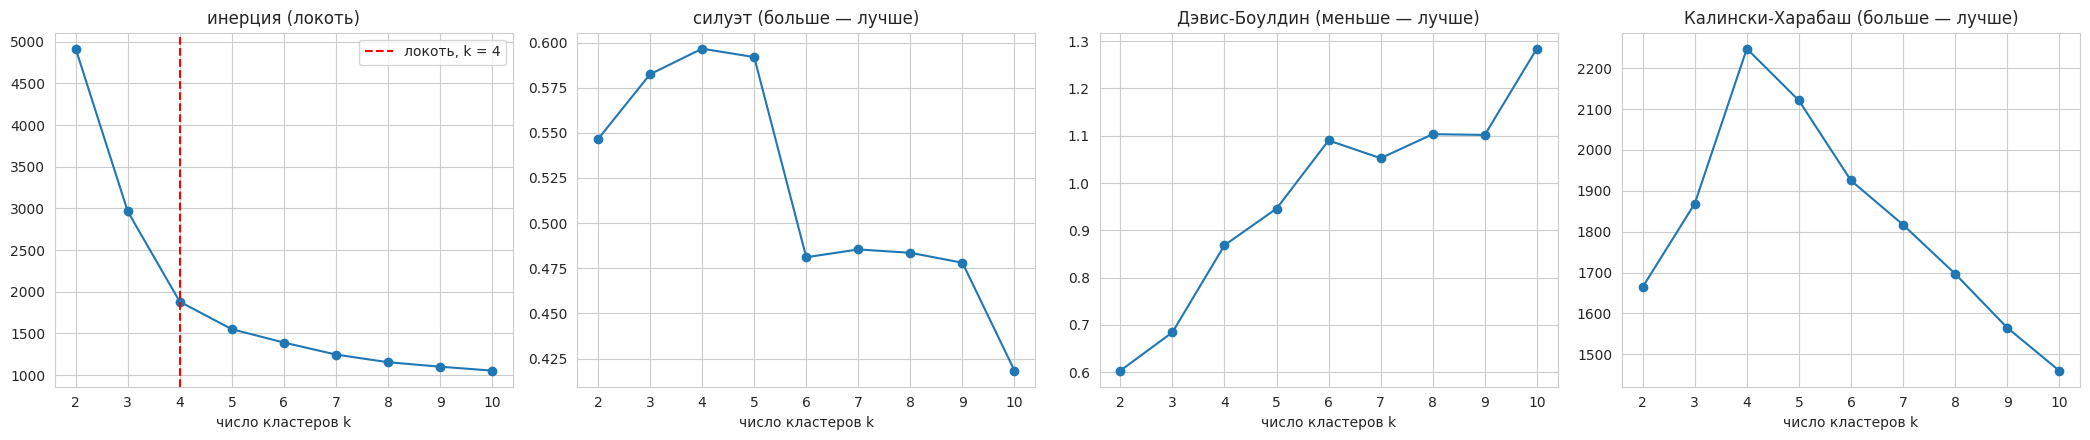

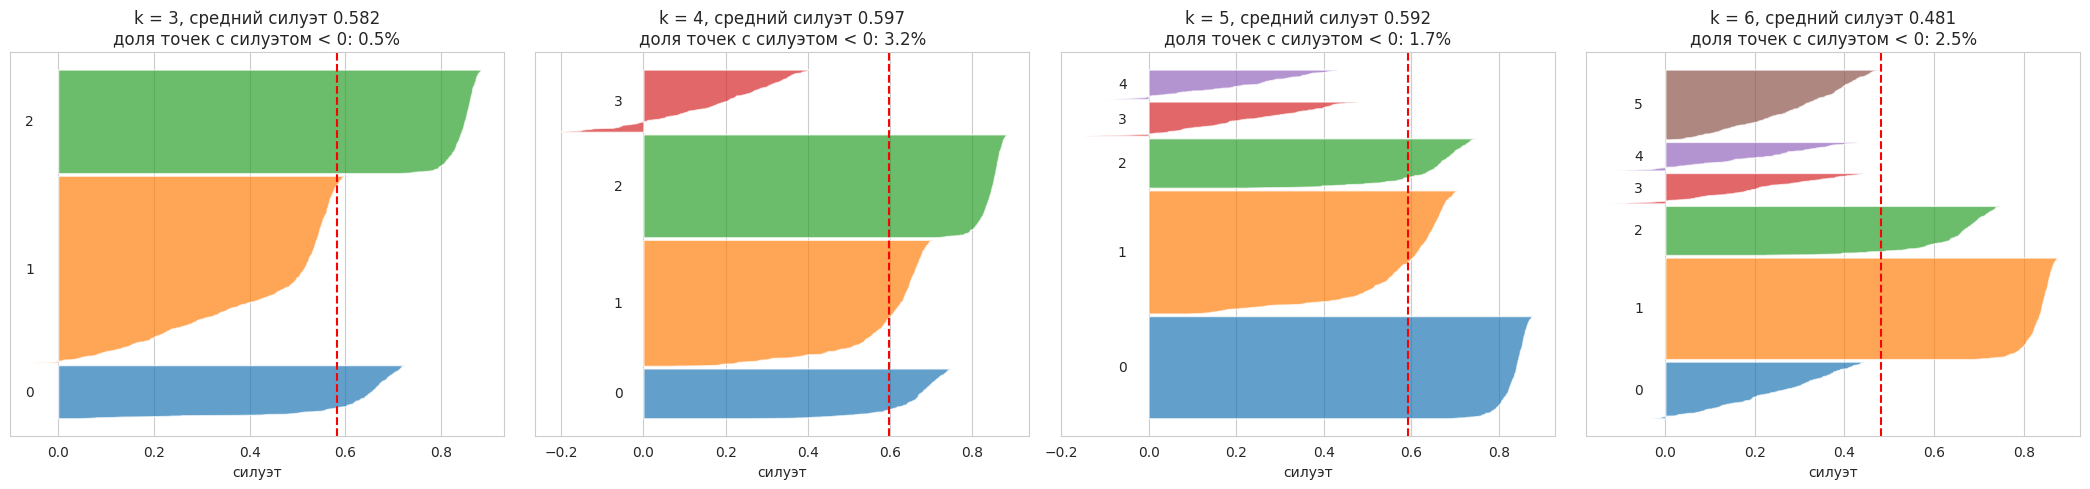

In [8]:
# Выбор числа кластеров для K-Means.
#
# Перебираем k от 2 до 10 и для каждого считаем четыре метрики:
#   инерция (метод локтя) — сумма квадратов расстояний до центров, всегда
#       падает с ростом k; ищем точку, после которой падение замедляется;
#   силуэт — насколько точка ближе к своему кластеру, чем к соседнему
#       (от −1 до 1, больше — лучше);
#   Дэвис — Боулдин — отношение разброса внутри кластеров к расстоянию
#       между ними (меньше — лучше);
#   Калински — Харабаш — отношение межкластерной дисперсии к внутренней
#       (больше — лучше).
# n_init=20: K-Means чувствителен к начальным центрам, несколько запусков
# с выбором лучшего снижают риск застрять в локальном минимуме.

K_RANGE = range(2, 11)
rows, models = [], {}
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    labels = km.fit_predict(X)
    models[k] = km
    rows.append({
        'k': k,
        'инерция': km.inertia_,
        'силуэт': silhouette_score(X, labels),
        'Дэвис-Боулдин': davies_bouldin_score(X, labels),
        'Калински-Харабаш': calinski_harabasz_score(X, labels),
        'мин. кластер': np.bincount(labels).min(),
        'макс. кластер': np.bincount(labels).max(),
    })
km_scan = pd.DataFrame(rows).set_index('k')
display(km_scan.round(3))

# Формальная точка локтя: k, наиболее удалённое от прямой, соединяющей
# первую и последнюю точки кривой инерции (идея метода Kneedle).
x = np.array(list(K_RANGE), dtype=float)
y = km_scan['инерция'].values
xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
elbow_k = int(x[np.argmax(np.abs(yn - (1 - xn)))])
print(f'Точка локтя: k = {elbow_k}')
print(f'Максимум силуэта: k = {km_scan["силуэт"].idxmax()}, '
      f'минимум Дэвиса — Боулдина: k = {km_scan["Дэвис-Боулдин"].idxmin()}, '
      f'максимум Калински — Харабаша: k = {km_scan["Калински-Харабаш"].idxmax()}')

fig, axes = plt.subplots(1, 4, figsize=(21, 4.5))
for ax, col, better in zip(axes, km_scan.columns[:4],
                           ['локоть', 'больше — лучше', 'меньше — лучше', 'больше — лучше']):
    ax.plot(km_scan.index, km_scan[col], marker='o')
    ax.set_title(f'{col} ({better})')
    ax.set_xlabel('число кластеров k')
axes[0].axvline(elbow_k, color='red', ls='--', label=f'локоть, k = {elbow_k}')
axes[0].legend()
plt.tight_layout()
plt.show()

# Силуэтные диаграммы для k-кандидатов: средний силуэт может быть высоким
# за счёт одного большого чёткого кластера при плохих остальных.
# Диаграмма показывает качество каждого кластера в отдельности.
K_SHOW = [3, 4, 5, 6]
fig, axes = plt.subplots(1, len(K_SHOW), figsize=(21, 5), sharey=False)
for ax, k in zip(axes, K_SHOW):
    labels = models[k].labels_
    sil = silhouette_samples(X, labels)
    y_low = 10
    for c in range(k):
        vals = np.sort(sil[labels == c])
        ax.fill_betweenx(np.arange(y_low, y_low + len(vals)), 0, vals, alpha=0.7)
        ax.text(-0.05, y_low + len(vals) / 2, str(c), ha='right', va='center')
        y_low += len(vals) + 10
    ax.axvline(sil.mean(), color='red', ls='--')
    ax.set_title(f'k = {k}, средний силуэт {sil.mean():.3f}\n'
                 f'доля точек с силуэтом < 0: {(sil < 0).mean() * 100:.1f}%')
    ax.set_xlabel('силуэт')
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### Выводы по выбору числа кластеров K-Means

| k | Силуэт | Дэвис — Боулдин | Калински — Харабаш | Размеры кластеров |
|---|---|---|---|---|
| 2 | 0.547 | **0.603** | 1 665 | 449–1 040 |
| 3 | 0.582 | 0.684 | 1 869 | 231–809 |
| 4 | **0.597** | 0.869 | **2 248** | 218–550 |
| 5 | 0.592 | 0.946 | 2 121 | 130–541 |
| 6 | 0.481 | 1.090 | 1 925 | 127–449 |

**Метод локтя** указывает на k = 4. Инерция быстро падает: 4 918 при
k = 2, 2 965 при k = 3, 1 881 при k = 4. Дальше снижение резко
замедляется: 1 552 при k = 5 и 1 391 при k = 6. Каждый следующий кластер
объясняет всё меньшую часть разброса.

**Силуэт** максимален при k = 4 (0.597). При k = 5 он почти такой же
(0.592), а при k = 6 падает до 0.481: шестой кластер разрезает
естественную группу. Значения 0.58–0.60 говорят о хорошо выраженной
структуре: силуэт выше 0.5 принято считать признаком разумного
разбиения, выше 0.7 — сильного.

**Калински — Харабаш** тоже максимален при k = 4.

**Дэвис — Боулдин** минимален при k = 2. Этот индекс склонен поощрять
малое число кластеров, если в данных есть одна очень компактная группа.
Здесь это кластер из 449 учителей: он выделяется уже при k = 2
и сохраняет этот размер при k от 6 до 10.

**Силуэтные диаграммы:**

- k = 3: кластер из ~450 учителей очень чёткий (силуэт 0.6–0.88),
  а самый крупный кластер (~800 учителей) неоднороден, его силуэт
  от 0 до 0.58. В нём смешаны разные группы;
- k = 4: неоднородный кластер разделяется. Появляется самый слабый кластер
  (~220 учителей) с силуэтом от 0 до 0.4 и частью отрицательных значений
  (всего с отрицательным силуэтом 3.2% учителей);
- k = 5: слабый кластер распадается на два по ~130 учителей с силуэтом
  до 0.45–0.48. Доля учителей с отрицательным силуэтом при этом снижается
  до 1.7%.

**Итог.** Метрики указывают на k = 4, а k = 5 — равноценный кандидат
по силуэту. Выбор между ними сделаем по устойчивости разбиения
и интерпретируемости профилей.

### 5.2. K-Means: сравнение k = 4 и k = 5, устойчивость

Устойчивость разбиения (20 подвыборок по 80%):


,ARI среднее,ARI минимум,запусков с ARI < 0.9
3,0.997,0.994,0
4,0.996,0.992,0
5,0.981,0.940,0
6,0.931,0.768,3



Профили кластеров при k = 4 (средние в исходных единицах):


,учителей,"доля, %",active_days_month,events_per_day,share_hw,share_lib,share_grade,share_web,share_sched,events,recency_days
cluster,,,,,,,,,,,
0,218,14.6,7.61,4.01,0.10,0.10,0.10,0.55,0.16,45.81,2.85
1,550,36.9,11.51,2.47,0.11,0.64,0.05,0.05,0.15,42.98,2.07
2,449,30.2,22.45,5.49,0.55,0.10,0.25,0.05,0.05,184.91,0.34
3,272,18.3,4.73,2.01,0.19,0.29,0.20,0.11,0.22,14.37,5.39



Профили кластеров при k = 5 (средние в исходных единицах):


,учителей,"доля, %",active_days_month,events_per_day,share_hw,share_lib,share_grade,share_web,share_sched,events,recency_days
cluster,,,,,,,,,,,
0,449,30.2,22.45,5.49,0.55,0.10,0.25,0.05,0.05,184.91,0.34
1,541,36.3,11.60,2.48,0.11,0.64,0.05,0.05,0.15,43.38,1.97
2,218,14.6,7.61,4.01,0.10,0.10,0.10,0.55,0.16,45.81,2.85
3,151,10.1,4.94,2.02,0.18,0.28,0.14,0.10,0.29,15.18,5.44
4,130,8.7,4.57,2.00,0.20,0.30,0.26,0.11,0.13,13.75,5.51


Как кластеры k = 4 переходят в кластеры k = 5 (число учителей):


k = 5,0,1,2,3,4
k = 4,,,,,
0,0,0,218,0,0
1,0,538,0,8,4
2,449,0,0,0,0
3,0,3,0,143,126


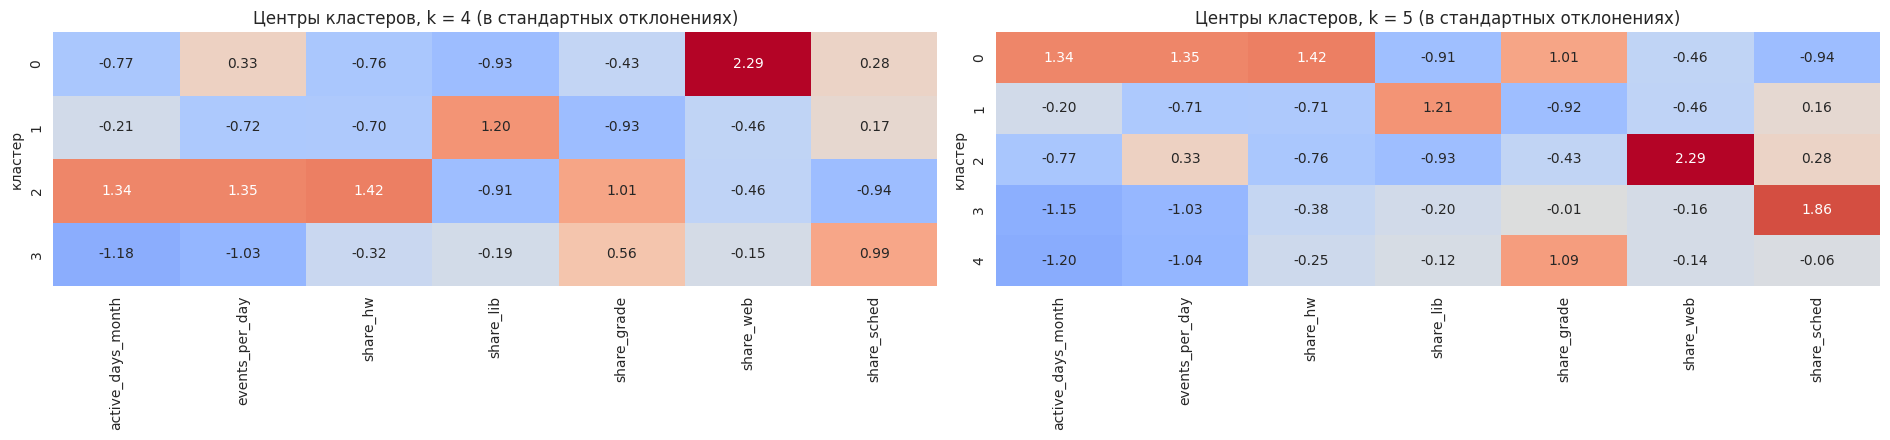

Доля дисперсии, объяснённая двумя компонентами: 78.0% (56.2%, 21.8%)


,PC1,PC2
active_days_month,0.42,-0.29
events_per_day,0.46,0.14
share_hw,0.47,-0.10
share_lib,-0.35,-0.55
share_grade,0.37,0.13
share_web,-0.09,0.73
share_sched,-0.35,0.20


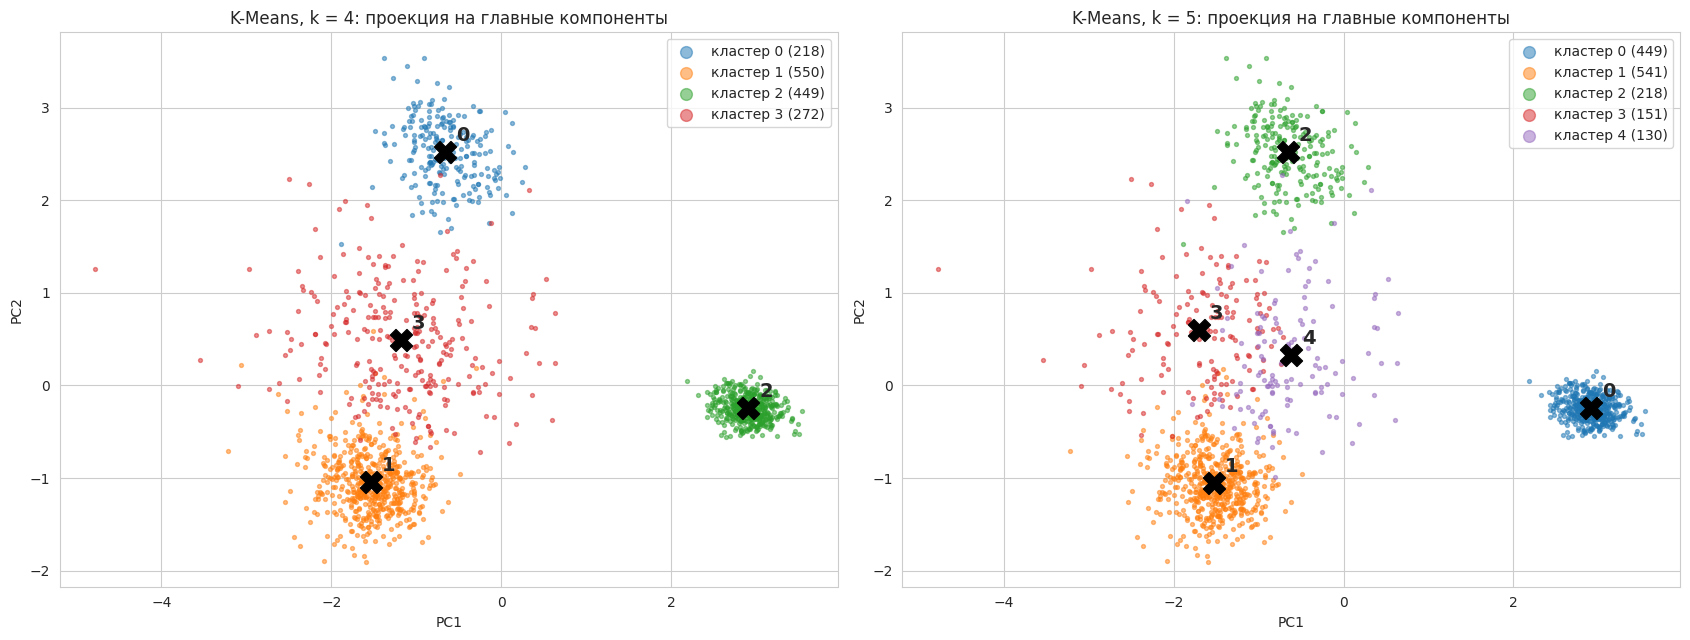

In [9]:
# Сравнение кандидатов k = 4 и k = 5: устойчивость и интерпретируемость.
#
# Метрики качества почти не различают k = 4 и k = 5 (силуэт 0.597 и 0.592),
# поэтому решение принимаем по двум дополнительным критериям:
#   1) устойчивость — воспроизводится ли разбиение на других данных;
#   2) интерпретируемость — описывают ли кластеры разное продуктовое поведение.

# --- 1. Устойчивость ---
# Обучаем K-Means на 20 случайных подвыборках по 80% учителей, размечаем
# всех учителей и сравниваем с разметкой модели, обученной на полных данных.
# Скорректированный индекс Рэнда (ARI): 1 — разбиения совпадают полностью,
# 0 — совпадение на уровне случайного. ARI не зависит от номеров кластеров.
N_BOOT = 20
rng = np.random.default_rng(RANDOM_STATE)
stab = {}
for k in [3, 4, 5, 6]:
    aris = []
    for i in range(N_BOOT):
        idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=i).fit(X.iloc[idx])
        aris.append(adjusted_rand_score(models[k].labels_, km_b.predict(X)))
    stab[k] = aris
stab_df = pd.DataFrame({
    'ARI среднее': {k: np.mean(v) for k, v in stab.items()},
    'ARI минимум': {k: np.min(v) for k, v in stab.items()},
    'запусков с ARI < 0.9': {k: int((np.array(v) < 0.9).sum()) for k, v in stab.items()},
})
print(f'Устойчивость разбиения ({N_BOOT} подвыборок по 80%):')
display(stab_df.round(3))

# --- 2. Профили кластеров ---
# Средние значения признаков в исходных единицах — для интерпретации;
# events и recency_days в модели не участвовали, но помогают описать группу.
def cluster_profile(labels):
    df = fm[FEATURES + ['events', 'recency_days']].copy()
    df['cluster'] = labels
    prof = df.groupby('cluster').mean()
    size = df.groupby('cluster').size()
    prof.insert(0, 'учителей', size)
    prof.insert(1, 'доля, %', (size / size.sum() * 100).round(1))
    return prof

for k in [4, 5]:
    print(f'\nПрофили кластеров при k = {k} (средние в исходных единицах):')
    display(cluster_profile(models[k].labels_).round(2))

print('Как кластеры k = 4 переходят в кластеры k = 5 (число учителей):')
display(pd.crosstab(models[4].labels_, models[5].labels_,
                    rownames=['k = 4'], colnames=['k = 5']))

# --- 3. Визуализация ---
# Тепловая карта центров в стандартизованных единицах: насколько каждый
# кластер выше (красный) или ниже (синий) среднего по каждому признаку.
fig, axes = plt.subplots(1, 2, figsize=(19, 4.5))
for ax, k in zip(axes, [4, 5]):
    centers = pd.DataFrame(models[k].cluster_centers_, columns=FEATURES)
    sns.heatmap(centers, annot=True, fmt='.2f', cmap='coolwarm', center=0,
                ax=ax, cbar=False)
    ax.set_title(f'Центры кластеров, k = {k} (в стандартных отклонениях)')
    ax.set_ylabel('кластер')
plt.tight_layout()
plt.show()

# Проекция на две главные компоненты — чтобы увидеть, как кластеры
# расположены друг относительно друга. Это сжатие 7 признаков до 2,
# поэтому часть различий на плоскости не видна.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pc = pca.fit_transform(X)
print(f'Доля дисперсии, объяснённая двумя компонентами: '
      f'{pca.explained_variance_ratio_.sum() * 100:.1f}% '
      f'({", ".join(f"{v * 100:.1f}%" for v in pca.explained_variance_ratio_)})')
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1', 'PC2'])
display(loadings.round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, k in zip(axes, [4, 5]):
    labels = models[k].labels_
    centers_pc = pca.transform(models[k].cluster_centers_)
    for c in range(k):
        ax.scatter(pc[labels == c, 0], pc[labels == c, 1], s=8, alpha=0.5,
                   label=f'кластер {c} ({(labels == c).sum()})')
        ax.scatter(*centers_pc[c], s=250, marker='X', color='black')
        ax.annotate(str(c), centers_pc[c], fontsize=14, fontweight='bold',
                    xytext=(8, 8), textcoords='offset points')
    ax.set_title(f'K-Means, k = {k}: проекция на главные компоненты')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

### Выводы по сравнению k = 4 и k = 5

**Устойчивость.**

| k | ARI, среднее | ARI, минимум | Запусков с ARI < 0.9 |
|---|---|---|---|
| 3 | 0.997 | 0.994 | 0 |
| 4 | **0.996** | **0.992** | 0 |
| 5 | 0.981 | 0.940 | 0 |
| 6 | 0.931 | 0.768 | 3 из 20 |

Разбиение на 4 кластера воспроизводится почти идеально: модель, обученная
на любых 80% учителей, размечает всех практически так же (ARI не ниже
0.992). При k = 5 устойчивость снижается, а при k = 6 в 3 из 20 запусков
разбиение заметно меняется.

**Что даёт пятый кластер.** При переходе к k = 5 три кластера сохраняются
почти без изменений (218 → 218, 449 → 449, 550 → 538). Делится только
кластер 3 (272 учителя): 143 учителя попадают в группу с повышенной долей
расписания (0.29), 126 — в группу с повышенной долей оценок (0.26).

Обе половины — учителя с минимальной активностью: 4.6–4.9 активных дня
в месяц, 2 события в день, 14–15 событий за 45 дней. При таком числе
событий доли модулей сами по себе шумные: случайный разброс доли 0.2
по 14 событиям составляет около ±0.11 (√(0.2 · 0.8 / 14)). Различие
долей расписания 0.13 и 0.29 — это примерно 1.5 таких отклонения.
Для продукта обеим группам нужно одно и то же — активация, поэтому
отдельные сценарии под них не нужны.

**Решение: k = 4.** Это значение выбрали все три метрики (локоть, силуэт,
Калински — Харабаш), оно даёт самое устойчивое разбиение (ARI 0.996),
и каждый кластер описывает свой продуктовый сценарий.

**Профили сегментов (предварительно):**

| Кластер | Учителей | Активных дней в месяц | Событий в день | Основной модуль | Рабочее название |
|---|---|---|---|---|---|
| 2 | 449 (30.2%) | 22.5 | 5.5 | ДЗ 55% + оценки 25% | «Ежедневная работа с ДЗ» |
| 1 | 550 (36.9%) | 11.5 | 2.5 | библиотека 64% | «Библиотека для очных уроков» |
| 0 | 218 (14.6%) | 7.6 | 4.0 | вебинары 55% | «Интерактивные» |
| 3 | 272 (18.3%) | 4.7 | 2.0 | нет | «Эпизодические» |

Три сегмента из четырёх точно совпадают с группами из описания продукта.
Четвёртый — учителя, которые заходят 4–5 раз в месяц и распределяют
немногие действия по всем модулям (доли от 0.11 до 0.29). У них самая
большая давность последнего визита: 5.4 дня против 0.3–2.9 в других
сегментах. Эти учителя ещё не выбрали «свой» сценарий использования
платформы.

**Проекция на главные компоненты** объясняет 78% дисперсии.

- PC1 (56%) — ось «интенсивность и работа с ДЗ». Положительные нагрузки
  у активных дней, событий в день, долей ДЗ и оценок, отрицательные —
  у долей библиотеки и расписания.
- PC2 (22%) — ось «вебинары против библиотеки»: нагрузки 0.73 и −0.55.

На плоскости главных компонент:

- сегмент «ДЗ» — компактное облако справа, далеко от остальных. Это самый
  чёткий сегмент, силуэт до 0.88;
- «библиотека» и «интерактивные» — отдельные облака внизу и вверху
  левой части;
- «эпизодические» — размытое облако между ними. По структуре они понемногу
  похожи на каждую группу, а их доли сильно разбросаны из-за малого
  числа событий.

### 5.3. DBSCAN

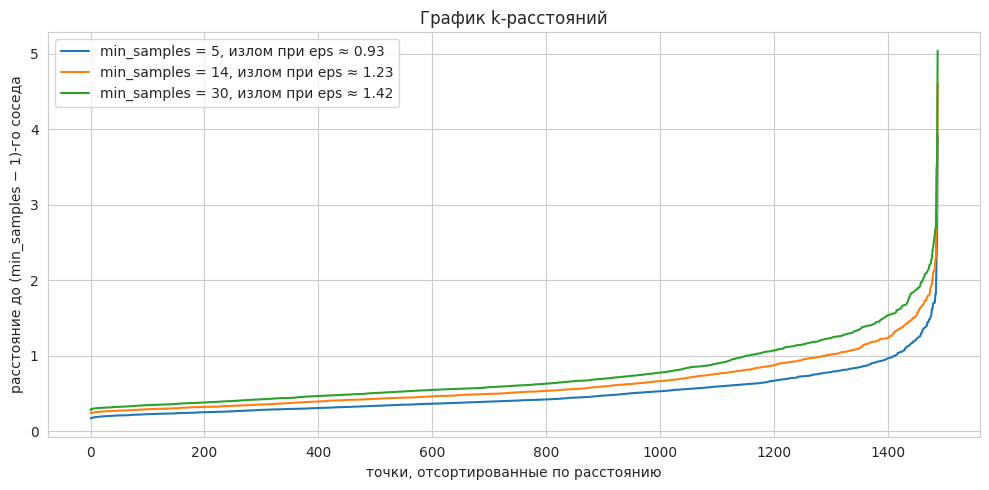

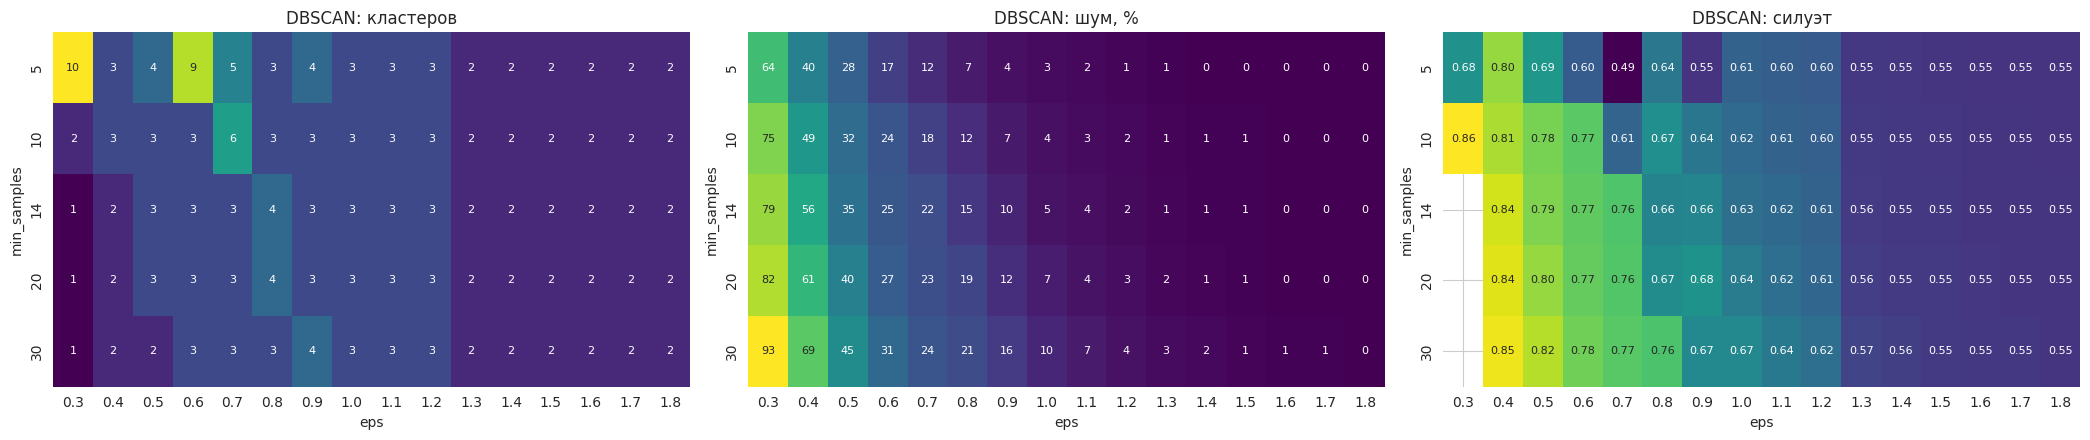

Конфигураций с >= 2 кластерами (каждый >= 14 учителей) и шумом <= 10%: 47


,min_samples,eps,кластеров,мин. кластер,"шум, %",силуэт,ARI с K-Means
38,14,0.9,3,211,9.537,0.660,0.801
55,20,1.0,3,214,7.186,0.644,0.775
72,30,1.1,3,214,6.716,0.641,0.771
5,5,0.8,3,212,6.917,0.639,0.768
22,10,0.9,3,212,6.582,0.636,0.764
39,14,1.0,3,214,4.835,0.626,0.750
56,20,1.1,3,214,4.500,0.624,0.747
73,30,1.2,3,216,4.433,0.623,0.748
23,10,1.0,3,214,4.030,0.619,0.741
40,14,1.1,3,215,3.627,0.617,0.739



Выбрано: eps = 0.9, min_samples = 14 → 3 кластеров, шум 9.5%, силуэт 0.660, ARI с K-Means (k = 4) 0.801

K-Means (k = 4) против DBSCAN (−1 — шум), число учителей:


DBSCAN,-1,0,1,2
K-Means,,,,
0,7,211,0,0
1,19,0,531,0
2,0,0,0,449
3,116,0,156,0


Профили кластеров DBSCAN (−1 — шум):


,учителей,"доля, %",active_days_month,events_per_day,share_hw,share_lib,share_grade,share_web,share_sched,events,recency_days
cluster,,,,,,,,,,,
-1,142,9.5,3.87,2.02,0.19,0.27,0.20,0.13,0.21,11.94,6.48
0,211,14.2,7.70,4.03,0.10,0.10,0.10,0.55,0.16,46.46,2.85
1,687,46.1,10.34,2.39,0.13,0.57,0.08,0.06,0.16,37.89,2.48
2,449,30.2,22.45,5.49,0.55,0.10,0.25,0.05,0.05,184.91,0.34


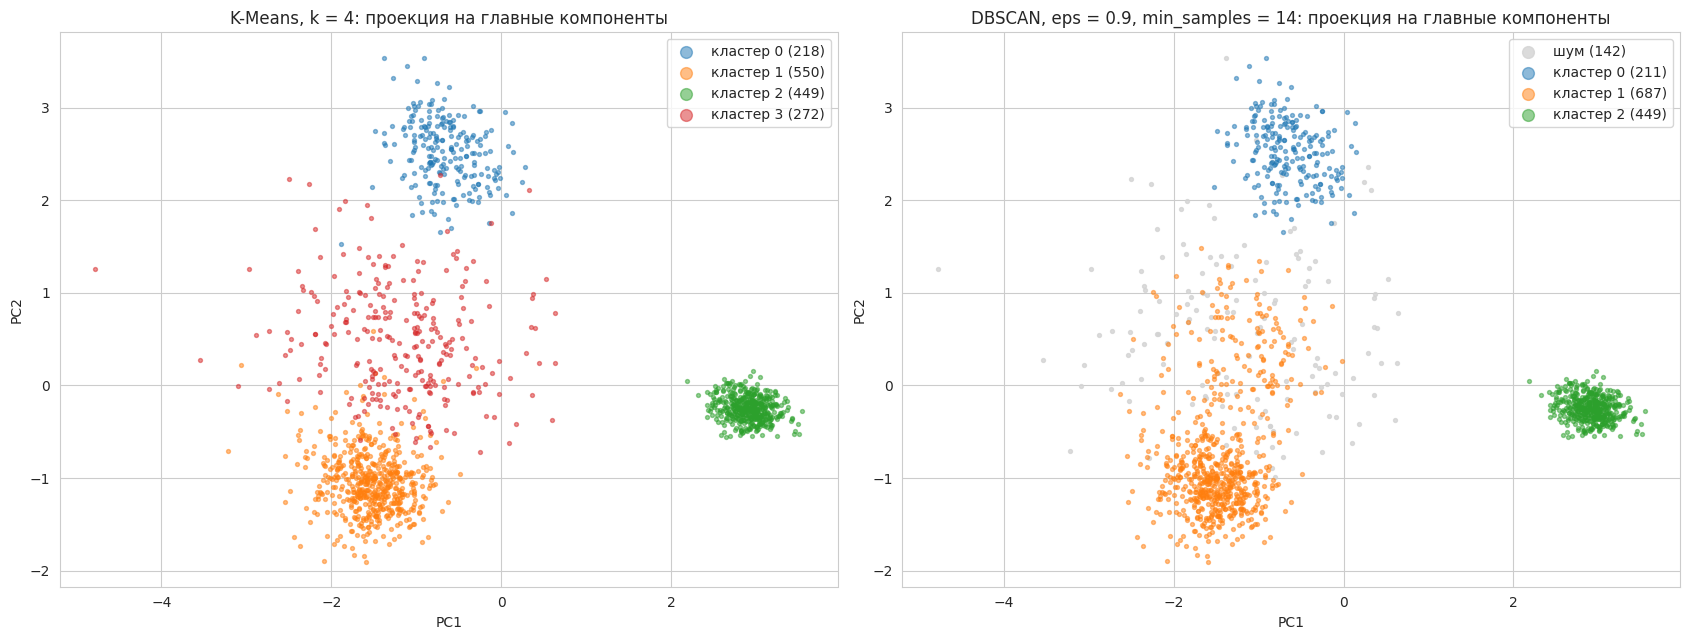

In [10]:
# Кластеризация DBSCAN.
#
# DBSCAN устроен иначе, чем K-Means: он не требует задавать число кластеров
# и не предполагает, что кластеры шарообразные и одного размера. Кластер —
# это область высокой плотности точек; точки в разреженных областях
# помечаются как шум (метка −1). Два параметра:
#   eps         — радиус окрестности точки;
#   min_samples — сколько точек (включая саму точку) должно быть в радиусе eps,
#                 чтобы точка считалась «ядром» плотной области.
# Сравнение с K-Means покажет, какие сегменты — плотные устойчивые группы,
# а какие — размытые области, которые K-Means «нарезает» принудительно.

KM4_LABELS = models[4].labels_

# --- 1. Подбор eps по графику k-расстояний ---
# Для каждой точки берём расстояние до (min_samples − 1)-го соседа
# и сортируем. Точки внутри плотных областей дают пологий участок,
# шум — резкий подъём в конце. Излом кривой — естественный кандидат на eps.
# Эмпирическое правило для min_samples — удвоенная размерность (2 × 7 = 14).
fig, ax = plt.subplots(figsize=(10, 5))
knee_eps = {}
for ms in [5, 14, 30]:
    nn = NearestNeighbors(n_neighbors=ms).fit(X)       # первый сосед — сама точка
    d = np.sort(nn.kneighbors(X)[0][:, -1])
    xs = np.linspace(0, 1, len(d))
    ys = (d - d.min()) / (d.max() - d.min())
    knee_eps[ms] = d[np.argmax(xs - ys)]               # наибольшее отклонение от диагонали
    ax.plot(d, label=f'min_samples = {ms}, излом при eps ≈ {knee_eps[ms]:.2f}')
ax.set_title('График k-расстояний')
ax.set_xlabel('точки, отсортированные по расстоянию')
ax.set_ylabel('расстояние до (min_samples − 1)-го соседа')
ax.legend()
plt.tight_layout()
plt.show()

# --- 2. Сетка параметров ---
# Силуэт считаем только по точкам кластеров: шум к кластерам не относится.
# Из-за этого силуэт DBSCAN завышен — модель «выбросила» самые трудные
# точки, — поэтому смотрим на него вместе с долей шума.
eps_grid = np.round(np.arange(0.3, 1.81, 0.1), 2)
rows = []
for ms in [5, 10, 14, 20, 30]:
    for eps in eps_grid:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        core = lab != -1
        n_cl = len(set(lab[core]))
        rows.append({
            'min_samples': ms, 'eps': eps, 'кластеров': n_cl,
            'мин. кластер': np.bincount(lab[core]).min() if n_cl else 0,
            'шум, %': (~core).mean() * 100,
            'силуэт': silhouette_score(X[core], lab[core]) if n_cl >= 2 else np.nan,
            'ARI с K-Means': (adjusted_rand_score(KM4_LABELS[core], lab[core])
                              if n_cl >= 1 else np.nan),
        })
db_scan = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(21, 4.5))
for ax, col, fmt in zip(axes, ['кластеров', 'шум, %', 'силуэт'], ['.0f', '.0f', '.2f']):
    pv = db_scan.pivot(index='min_samples', columns='eps', values=col)
    sns.heatmap(pv, annot=True, fmt=fmt, cmap='viridis', ax=ax, cbar=False,
                annot_kws={'size': 8})
    ax.set_title(f'DBSCAN: {col}')
plt.tight_layout()
plt.show()

# --- 3. Выбор конфигурации ---
# Правило: не менее двух кластеров; каждый кластер не меньше 1% учителей
# (группа из нескольких человек — не сегмент, под неё не строят продукт);
# шум не более 10% (иначе модель отказывается сегментировать заметную
# часть учителей); среди подходящих — максимум силуэта.
MIN_CLUSTER = int(0.01 * len(X))
MAX_NOISE = 10
ok = (db_scan['кластеров'] >= 2) & (db_scan['мин. кластер'] >= MIN_CLUSTER)
candidates = db_scan[ok & (db_scan['шум, %'] <= MAX_NOISE)]
if candidates.empty:                      # запасной вариант: ослабляем порог шума
    MAX_NOISE = 25
    candidates = db_scan[ok & (db_scan['шум, %'] <= MAX_NOISE)]
print(f'Конфигураций с >= 2 кластерами (каждый >= {MIN_CLUSTER} учителей) '
      f'и шумом <= {MAX_NOISE}%: {len(candidates)}')
display(candidates.sort_values('силуэт', ascending=False).head(10).round(3))

best = candidates.sort_values('силуэт', ascending=False).iloc[0]
DB_EPS, DB_MS = float(best['eps']), int(best['min_samples'])
dbscan = DBSCAN(eps=DB_EPS, min_samples=DB_MS)
db_labels = dbscan.fit_predict(X)
print(f'\nВыбрано: eps = {DB_EPS}, min_samples = {DB_MS} → '
      f'{best["кластеров"]:.0f} кластеров, шум {best["шум, %"]:.1f}%, '
      f'силуэт {best["силуэт"]:.3f}, ARI с K-Means (k = 4) {best["ARI с K-Means"]:.3f}')

# --- 4. Сопоставление с K-Means и профили ---
print('\nK-Means (k = 4) против DBSCAN (−1 — шум), число учителей:')
display(pd.crosstab(KM4_LABELS, db_labels, rownames=['K-Means'], colnames=['DBSCAN']))

print('Профили кластеров DBSCAN (−1 — шум):')
display(cluster_profile(db_labels).round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, labels, title in zip(axes, [KM4_LABELS, db_labels],
                             ['K-Means, k = 4', f'DBSCAN, eps = {DB_EPS}, min_samples = {DB_MS}']):
    for c in sorted(set(labels)):
        m = labels == c
        ax.scatter(pc[m, 0], pc[m, 1], s=8, alpha=0.5 if c != -1 else 0.8,
                   color='lightgrey' if c == -1 else None,
                   label=f'{"шум" if c == -1 else f"кластер {c}"} ({m.sum()})')
    ax.set_title(f'{title}: проекция на главные компоненты')
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
    ax.legend(markerscale=3)
plt.tight_layout()
plt.show()

### Выводы по DBSCAN

**Подбор `eps`.** Излом графика k-расстояний: eps ≈ 0.93 при
min_samples = 5, 1.23 при 14 и 1.42 при 30. Кривые пологие примерно
до 1 300-й точки и резко растут на последних 100–150 точках. Эти
последние точки — разреженно расположенные учителя, кандидаты в шум.

**Поведение на сетке параметров:**

- при eps ≤ 0.5 шум составляет 28–93%: модель «не видит» большинство
  учителей;
- при eps от 1.0 до 1.2 при любом min_samples получаются ровно
  3 кластера с шумом 1–10%; при eps 0.8–0.9 — 3 или 4 кластера
  в зависимости от min_samples;
- при eps ≥ 1.3 всегда получаются 2 кластера с силуэтом 0.55. Модель
  отделяет только сегмент ДЗ от всех остальных — так же, как K-Means
  при k = 2 (силуэт 0.547);
- 4 кластера DBSCAN даёт лишь в отдельных точках сетки, и там либо
  высокий шум (15–28%), либо силуэт ниже (0.55).

**Выбранная конфигурация:** eps = 0.9, min_samples = 14, что совпадает
с правилом «2 × размерность». Получились 3 кластера, шум 9.5%
(142 учителя), силуэт 0.660 (без учёта шума), ARI с K-Means 0.801.
Все десять лучших по силуэту конфигураций (eps от 0.8 до 1.2) дают
те же три кластера, наименьший из которых — 211–216 учителей. Основной
результат не зависит от точного выбора параметров.

**Сопоставление с K-Means:**

| Сегмент K-Means (k = 4), 1 489 учителей в обучении | Что с ним сделал DBSCAN |
|---|---|
| Ежедневные (ДЗ), 449 | кластер 2 — все 449 |
| Библиотекари, 550 | кластер 1 — 531, шум — 19 |
| Интерактивщики, 218 | кластер 0 — 211, шум — 7 |
| Эпизодические, 272 | шум — 116, присоединены к библиотекарям — 156 |

- **Три основных сегмента подтверждены.** DBSCAN независимо и без
  заданного числа кластеров нашёл те же плотные группы: сегмент ДЗ
  совпал полностью, интерактивщики и библиотекари — на 97%. Значит,
  эти сегменты — реальные группы учителей, а не артефакт метода.
- **«Эпизодические» не образуют плотной области.** 43% из них DBSCAN
  отнёс к шуму, остальные 57% — к библиотекарям. Профиль шума совпадает
  с профилем эпизодических: 3.9 активных дня в месяц, 2 события в день,
  около 12 событий за 45 дней, давность последнего визита 6.5 дня,
  без доминирующего модуля. Это ожидаемо: при 12–15 событиях доли модулей
  сильно разбросаны, и такие учителя образуют разреженное облако.
  Присоединение части эпизодических к библиотекарям — вероятно, эффект
  «цепочки». По активности (мало дней, около 2 событий в день)
  малоактивные учителя близки к библиотекарям, и DBSCAN с единым порогом
  плотности соединяет их через соседей. Из-за этого доля библиотеки
  в кластере 1 DBSCAN ниже, чем у библиотекарей K-Means: 0.57 против 0.64.

**Вывод.** «Эпизодические» — не отдельный тип использования, а состояние
низкой вовлечённости с размытой структурой. При этом для продукта группа
важна: это 18% учителей, которых нужно активировать, и в сегментации
она должна быть отдельно. Это довод в пользу K-Means, который размечает
всех учителей.

### 5.4. Сравнение K-Means и DBSCAN, итоговая модель

In [11]:
# Сравнение K-Means и DBSCAN и выбор итоговой модели.
#
# Силуэт DBSCAN (0.66) выше, чем у K-Means (0.597), но посчитан без 9.5%
# «шумовых» учителей — самых трудных для разметки. Для честного сравнения
# считаем силуэт K-Means на тех же точках. Устойчивость DBSCAN проверяем
# так же, как у K-Means: обучение на 20 подвыборках по 80%.
core = db_labels != -1

# DBSCAN не умеет размечать новые точки, поэтому сравниваем разметку
# подвыборки с разметкой тех же учителей на полных данных. В подвыборке
# точек меньше, поэтому min_samples уменьшаем пропорционально (плотность та же).
db_aris = []
for i in range(N_BOOT):
    idx = np.random.default_rng(i).choice(len(X), size=int(0.8 * len(X)), replace=False)
    lab_b = DBSCAN(eps=DB_EPS, min_samples=max(2, round(DB_MS * 0.8))).fit_predict(X.iloc[idx])
    db_aris.append(adjusted_rand_score(db_labels[idx], lab_b))

# Чувствительность к параметрам: сколько кластеров даёт DBSCAN
# при небольшом сдвиге eps (±0.1) с любым min_samples из сетки.
near = db_scan[(db_scan['eps'] - DB_EPS).abs() <= 0.1 + 1e-9]

compare = pd.DataFrame({
    'K-Means, k = 4': {
        'кластеров': 4,
        'размечено учителей, %': 100.0,
        'силуэт по всем учителям': silhouette_score(X, KM4_LABELS),
        'силуэт без шума DBSCAN': silhouette_score(X[core], KM4_LABELS[core]),
        'устойчивость, ARI среднее': np.mean(stab[4]),
        'устойчивость, ARI минимум': np.min(stab[4]),
    },
    f'DBSCAN, eps = {DB_EPS}, min_samples = {DB_MS}': {
        'кластеров': len(set(db_labels[core])),
        'размечено учителей, %': core.mean() * 100,
        'силуэт по всем учителям': np.nan,
        'силуэт без шума DBSCAN': silhouette_score(X[core], db_labels[core]),
        'устойчивость, ARI среднее': np.mean(db_aris),
        'устойчивость, ARI минимум': np.min(db_aris),
    },
})
display(compare.round(3))
print(f'DBSCAN при eps = {DB_EPS} ± 0.1 и min_samples от 5 до 30: '
      f'от {near["кластеров"].min()} до {near["кластеров"].max()} кластеров, '
      f'шум от {near["шум, %"].min():.1f}% до {near["шум, %"].max():.1f}%')

# --- Итоговая модель: K-Means, k = 4 ---
# Названия сегментам присваиваем по профилю, а не по номеру кластера:
# номера зависят от инициализации, профиль — нет. Последовательно берём
# кластер с наибольшей долей ДЗ, затем вебинаров, затем библиотеки
# из оставшихся; последний — без доминирующего модуля.
km_final = models[4]
prof4 = cluster_profile(KM4_LABELS)
name_map, left = {}, [int(c) for c in prof4.index]
for col, name in [('share_hw', 'Ежедневные (ДЗ)'), ('share_web', 'Интерактивщики'),
                  ('share_lib', 'Библиотекари')]:
    c = int(prof4.loc[left, col].idxmax())
    name_map[c] = name
    left.remove(c)
name_map[left[0]] = 'Эпизодические'
SEGMENTS = ['Ежедневные (ДЗ)', 'Библиотекари', 'Интерактивщики', 'Эпизодические']
print('\nСоответствие кластеров и сегментов:', name_map)

# Сегмент получают все 1 500 учителей: 11 учителей, не участвовавших
# в обучении (< 3 активных дней), относим к ближайшему центру кластера.
feat['cluster'] = km_final.predict(scaler.transform(feat[FEATURES]))
feat['segment'] = feat['cluster'].map(name_map)
feat['dbscan_noise'] = pd.Series(db_labels == -1, index=X.index).reindex(feat.index)

print(f'Расхождений predict и разметки обучения: '
      f'{(feat.loc[X.index, "cluster"].values != KM4_LABELS).sum()}')
print('\nУчителя без обучения (< 3 активных дней) по сегментам:',
      feat.loc[~feat['in_model'], 'segment'].value_counts().to_dict())
seg_counts = feat['segment'].value_counts().reindex(SEGMENTS)
display(pd.DataFrame({'учителей': seg_counts,
                      'доля, %': (seg_counts / len(feat) * 100).round(1)}))

,"K-Means, k = 4","DBSCAN, eps = 0.9, min_samples = 14"
кластеров,4.000,3.000
"размечено учителей, %",100.000,90.463
силуэт по всем учителям,0.597,NaN
силуэт без шума DBSCAN,0.633,0.660
"устойчивость, ARI среднее",0.996,0.970
"устойчивость, ARI минимум",0.992,0.943


DBSCAN при eps = 0.9 ± 0.1 и min_samples от 5 до 30: от 3 до 4 кластеров, шум от 2.7% до 21.4%

Соответствие кластеров и сегментов: {2: 'Ежедневные (ДЗ)', 0: 'Интерактивщики', 1: 'Библиотекари', 3: 'Эпизодические'}
Расхождений predict и разметки обучения: 0

Учителя без обучения (< 3 активных дней) по сегментам: {'Эпизодические': 7, 'Библиотекари': 4}


,учителей,"доля, %"
segment,,
Ежедневные (ДЗ),449,29.9
Библиотекари,554,36.9
Интерактивщики,218,14.5
Эпизодические,279,18.6


### Выводы по сравнению K-Means и DBSCAN

| Критерий | K-Means, k = 4 | DBSCAN, eps = 0.9, min_samples = 14 |
|---|---|---|
| Кластеров | 4 | 3 + шум |
| Размечено учителей | **100%** | 90.5% |
| Силуэт по всем учителям | 0.597 | — |
| Силуэт на одних и тех же учителях (без шума DBSCAN) | 0.633 | 0.660 |
| Устойчивость, ARI среднее / минимум | **0.996 / 0.992** | 0.970 / 0.943 |
| Чувствительность к параметрам | k выбрано тремя метриками | при eps ± 0.1: от 3 до 4 кластеров, шум от 2.7% до 21.4% |
| Разметка новых учителей | есть (`predict`) | нет |

**Качество разбиения сопоставимо.** На одних и тех же учителях силуэт
DBSCAN выше лишь на 0.027. Это объяснимо: DBSCAN объединил эпизодических
учителей, оставшихся вне шума, с библиотекарями и тем самым убрал самую
трудную границу. Первоначальный разрыв (0.660 против 0.597) почти
полностью объяснялся тем, что DBSCAN исключил из расчёта 9.5% самых
трудных учителей.

**Итоговая модель — K-Means с k = 4.** Причины:

1. **Сегмент получает каждый учитель.** Продукт должен персонализировать
   кабинет для всех, а при DBSCAN каждый десятый учитель остался бы
   без сегмента.
2. **Эпизодические выделены в отдельную группу.** Это 18.6% учителей
   с отдельной продуктовой задачей — активацией. DBSCAN частью отправляет
   их в шум, частью смешивает с библиотекарями.
3. **Разбиение устойчивее.** ARI 0.996 против 0.970. DBSCAN заметно
   реагирует на сдвиг параметров: при eps ± 0.1 шум меняется
   от 3% до 21%.
4. **Новых учителей можно разметить.** Новый учитель относится
   к ближайшему центру кластера. DBSCAN такой возможности не даёт.

DBSCAN использован как независимая проверка. Он подтвердил, что три
основных сегмента — плотные, реально существующие группы, а четвёртый —
размытое состояние низкой вовлечённости.

**Итоговые сегменты (все 1 500 учителей):**

| Сегмент | Учителей | Доля |
|---|---|---|
| Ежедневные (ДЗ) | 449 | 29.9% |
| Библиотекари | 554 | 36.9% |
| Интерактивщики | 218 | 14.5% |
| Эпизодические | 279 | 18.6% |

11 учителей с менее чем 3 активными днями, не участвовавших в обучении,
отнесены к ближайшему центру: 7 — к эпизодическим, 4 — к библиотекарям.
Для малоактивных учителей это логичный результат.

## 6. Профилирование сегментов

### 6.1. Продуктовые портреты сегментов

,"доля учителей, %","доля событий, %","доля в DAU, %"
segment,,,
Ежедневные (ДЗ),29.9,68.8,52.0
Библиотекари,36.9,19.6,32.7
Интерактивщики,14.5,8.3,8.6
Эпизодические,18.6,3.3,6.7


segment,Ежедневные (ДЗ),Библиотекари,Интерактивщики,Эпизодические
учителей,449,554,218,279
"активных дней в месяц, медиана",22.666667,12.0,7.333333,4.666667
"событий в активный день, медиана",5.485714,2.477226,4.0,2.0
"событий за 45 дней, медиана",184.0,44.0,46.0,14.0
средний DAU сегмента,336.044444,211.177778,55.311111,43.133333
"DAU / размер сегмента, %",74.842861,38.118732,25.372069,15.459976
"давность последнего визита, медиана дн.",0.0,1.0,2.0,4.0
"не заходили 7+ дней на конец периода, %",0.0,5.956679,11.009174,31.182796
"пользуются всеми 5 модулями, %",100.0,74.729242,95.412844,59.856631
"шум по DBSCAN, %",0.0,3.454545,3.211009,42.647059


Сегмент × регион: χ² = 20.2, степеней свободы 21, p-value = 0.509


segment,Ежедневные (ДЗ),Библиотекари,Интерактивщики,Эпизодические
region,,,,
Екатеринбург,27.5,39.0,12.1,21.4
Казань,27.0,35.8,16.2,21.1
Краснодар,30.5,40.2,13.8,15.5
Москва,35.6,33.9,14.1,16.4
Новосибирск,30.9,39.7,13.4,16.0
Пермь,33.3,30.6,15.6,20.6
Санкт-Петербург,31.4,32.8,17.6,18.1
Уфа,23.8,43.8,13.0,19.5


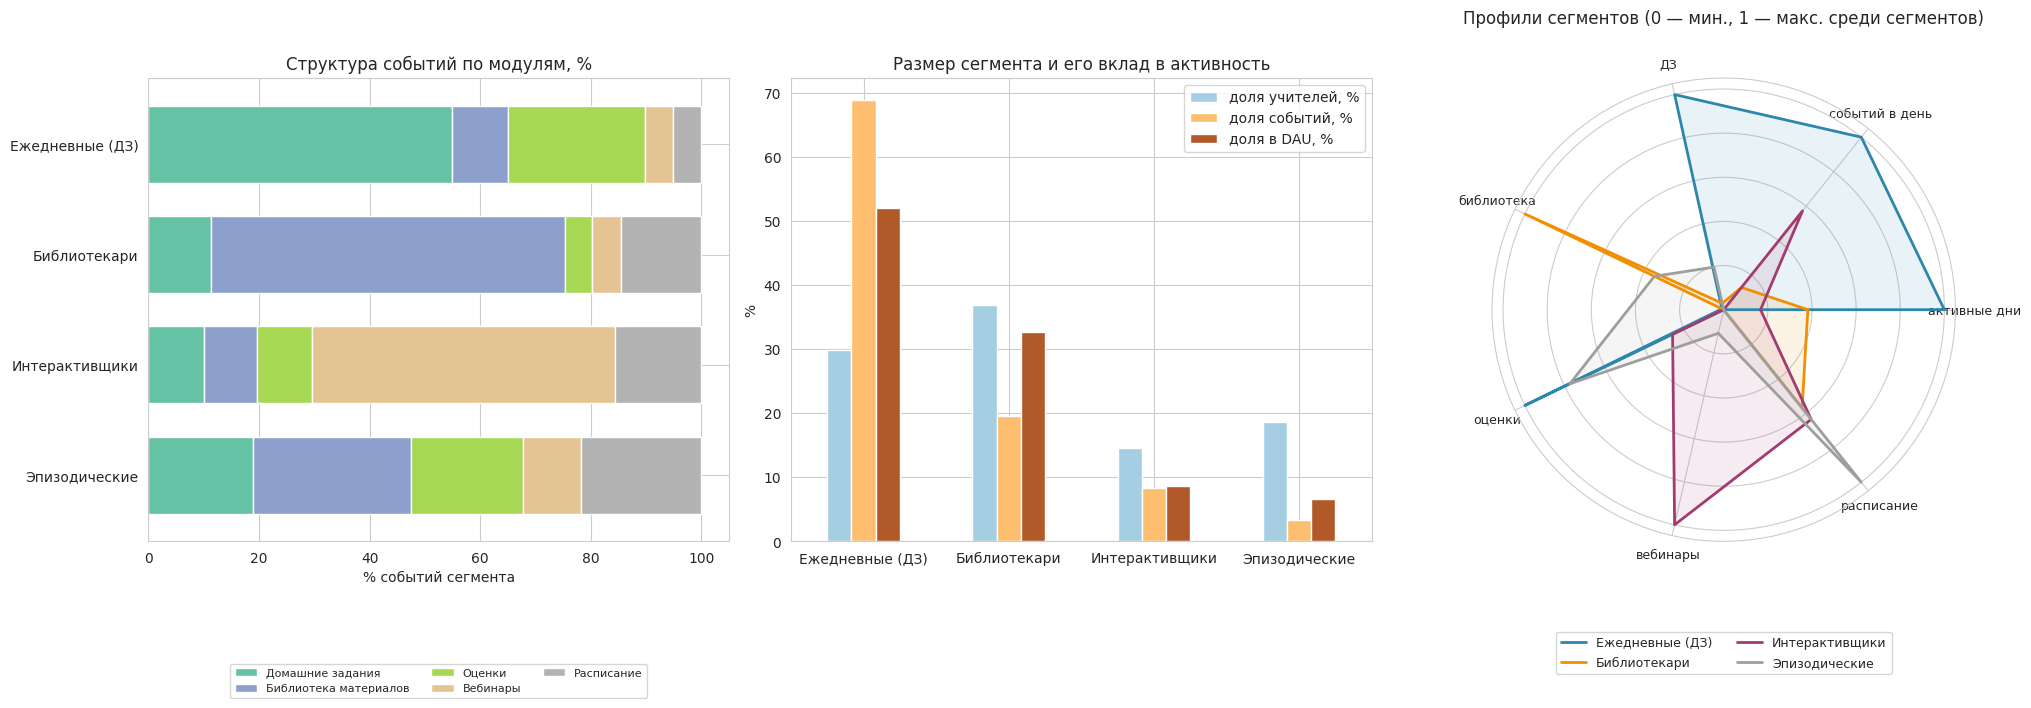

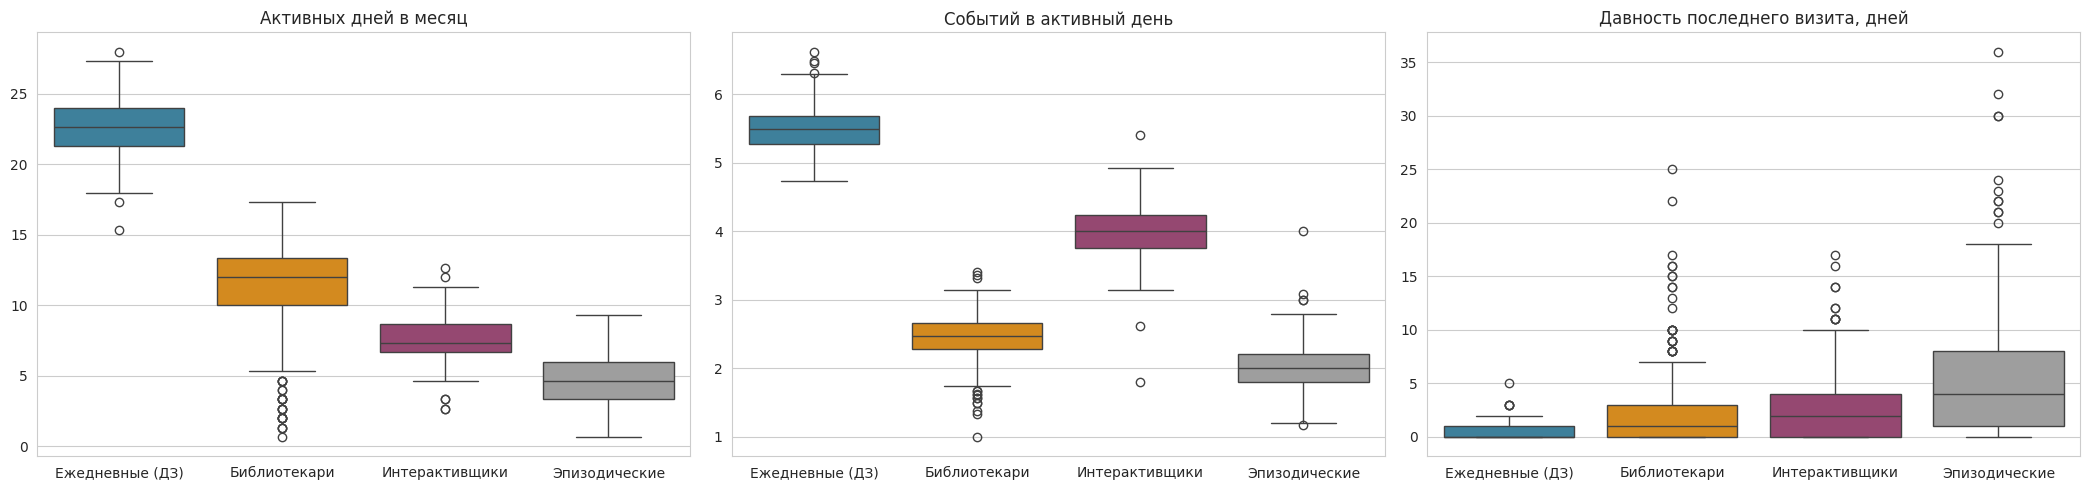

In [12]:
# Профилирование сегментов.
#
# Описываем сегменты на языке продукта: размер, вклад в активность
# платформы, регулярность, структура использования модулей, давность
# последнего визита. В профиль включаем и метрики, которые не участвовали
# в кластеризации (объём событий, давность, охват модулей): если сегменты
# различаются и по ним, это подтверждает, что группы содержательные.

seg_logs = clean.merge(feat[['segment']], left_on='user_id', right_index=True)
SEG_COLORS = dict(zip(SEGMENTS, ['#2E86AB', '#F18F01', '#A23B72', '#9E9E9E']))

# --- 1. Вклад сегментов в активность платформы ---
g = feat.groupby('segment')
dau_seg = seg_logs.groupby(['date', 'segment'])['user_id'].nunique().unstack().mean()
contrib = pd.DataFrame({
    'доля учителей, %': g.size() / len(feat) * 100,
    'доля событий, %': g['events'].sum() / feat['events'].sum() * 100,
    'доля в DAU, %': dau_seg / dau_seg.sum() * 100,
}).reindex(SEGMENTS)

# --- 2. Продуктовый профиль ---
profile = pd.DataFrame({
    'учителей': g.size(),
    'активных дней в месяц, медиана': g['active_days_month'].median(),
    'событий в активный день, медиана': g['events_per_day'].median(),
    'событий за 45 дней, медиана': g['events'].median(),
    'средний DAU сегмента': dau_seg,
    'DAU / размер сегмента, %': dau_seg / g.size() * 100,
    'давность последнего визита, медиана дн.': g['recency_days'].median(),
    'не заходили 7+ дней на конец периода, %': g['recency_days'].apply(lambda s: (s >= 7).mean() * 100),
    'пользуются всеми 5 модулями, %': g['n_modules'].apply(lambda s: (s == 5).mean() * 100),
    'шум по DBSCAN, %': g['dbscan_noise'].mean() * 100,
}).reindex(SEGMENTS)
for col in SHARE_COLS:
    profile[f'{col}, %'] = g[col].mean() * 100
for col in [c for c in feat.columns if c.startswith('days_')]:
    profile[f'{col} (доля дней с модулем), %'] = g[col].mean() * 100

display(contrib.round(1))
display(profile.T.round(1))

# --- 3. Связаны ли сегменты с регионом ---
# Если сегменты — это региональные различия (например, разная политика
# школ), рекомендации нужно строить по регионам, а не по поведению.
ct = pd.crosstab(feat['region'], feat['segment'])[SEGMENTS]
chi2, p_value, dof, _ = chi2_contingency(ct)
print(f'Сегмент × регион: χ² = {chi2:.1f}, степеней свободы {dof}, p-value = {p_value:.3f}')
display((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

# --- 4. Визуализация ---
fig = plt.figure(figsize=(21, 7.5))

# Структура использования модулей.
ax1 = fig.add_subplot(1, 3, 1)
mod_mix = profile[[f'{c}, %' for c in SHARE_COLS]]
mod_mix.columns = MODULES
mod_mix.plot.barh(stacked=True, ax=ax1, colormap='Set2', width=0.7)
ax1.set_title('Структура событий по модулям, %')
ax1.set_xlabel('% событий сегмента')
ax1.set_ylabel('')
ax1.invert_yaxis()
ax1.legend(loc='lower center', bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=8)

# Доля учителей против доли активности.
ax2 = fig.add_subplot(1, 3, 2)
contrib.plot.bar(ax=ax2, rot=0, colormap='Paired')
ax2.set_title('Размер сегмента и его вклад в активность')
ax2.set_ylabel('%')
ax2.set_xlabel('')

# Радар: сегменты относительно друг друга (0 — минимум среди сегментов,
# 1 — максимум). Показывает «форму» поведения каждого сегмента.
radar_cols = ['active_days_month', 'events_per_day'] + SHARE_COLS
radar_labels = ['активные дни', 'событий в день', 'ДЗ', 'библиотека',
                'оценки', 'вебинары', 'расписание']
rd = g[radar_cols].mean().reindex(SEGMENTS)
rd = (rd - rd.min()) / (rd.max() - rd.min())
angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
ax3 = fig.add_subplot(1, 3, 3, polar=True)
for s in SEGMENTS:
    vals = rd.loc[s].tolist()
    ax3.plot(angles + angles[:1], vals + vals[:1], color=SEG_COLORS[s], lw=2, label=s)
    ax3.fill(angles + angles[:1], vals + vals[:1], color=SEG_COLORS[s], alpha=0.1)
ax3.set_xticks(angles)
ax3.set_xticklabels(radar_labels, fontsize=9)
ax3.set_yticklabels([])
ax3.set_title('Профили сегментов (0 — мин., 1 — макс. среди сегментов)', y=1.1)
ax3.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Распределения ключевых метрик внутри сегментов.
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, col, title in zip(axes,
                          ['active_days_month', 'events_per_day', 'recency_days'],
                          ['Активных дней в месяц', 'Событий в активный день',
                           'Давность последнего визита, дней']):
    sns.boxplot(data=feat, x='segment', y=col, order=SEGMENTS, palette=SEG_COLORS, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

### Выводы по профилированию: портреты сегментов

**Сегменты содержательные.** Они различаются и по метрикам, которые
не участвовали в кластеризации: давности последнего визита, общему
объёму событий, числу используемых модулей и регулярности работы
с каждым модулем. Значит, группы описывают реальное поведение,
а не следуют из выбранного набора признаков.

**Сегменты не связаны с регионом.** χ² = 20.2 при 21 степени свободы,
p-value = 0.509. Доли сегментов по регионам колеблются в пределах
случайного разброса: например, доля «Ежедневных» составляет от 24%
в Уфе до 36% в Москве. Поведение учителя определяется не регионом,
поэтому рекомендации общие для всех регионов.

**Вклад сегментов в активность сильно неравномерный.**

| Сегмент | Доля учителей | Доля событий | Доля DAU |
|---|---|---|---|
| Ежедневные (ДЗ) | 29.9% | **68.8%** | **52.0%** |
| Библиотекари | 36.9% | 19.6% | 32.7% |
| Интерактивщики | 14.5% | 8.3% | 8.6% |
| Эпизодические | 18.6% | 3.3% | 6.7% |

Каждый второй учитель, зашедший на платформу в любой день, — из сегмента
«Ежедневные». Ежедневная активность платформы критически зависит
от этой группы.

**Сводный профиль:**

| Метрика | Ежедневные (ДЗ) | Библиотекари | Интерактивщики | Эпизодические |
|---|---|---|---|---|
| Учителей | 449 | 554 | 218 | 279 |
| Активных дней в месяц, медиана | 22.7 | 12.0 | 7.3 | 4.7 |
| Событий за визит, медиана | 5.5 | 2.5 | 4.0 | 2.0 |
| Событий за 45 дней, медиана | 184 | 44 | 46 | 14 |
| Активны в среднем за день | 75% | 38% | 25% | 15% |
| Основной модуль (доля событий) | ДЗ 55% + оценки 25% | библиотека 64% | вебинары 55% | нет |
| Основной модуль в доле визитов | ДЗ 97%, оценки 77% | библиотека 86% | вебинары 92% | библиотека 46% |
| Пользуются всеми 5 модулями | 100% | 75% | 95% | 60% |
| Давность последнего визита, медиана | 0 дн. | 1 дн. | 2 дн. | 4 дн. |
| Не заходили 7+ дней на конец периода | 0% | 6.0% | 11.0% | **31.2%** |

---

#### 1. «Ежедневные практики ДЗ» — 449 учителей (29.9%)

*Платформа для них — рабочий инструмент цикла «задал — проверил — оценил».*

- **Частота.** 22.7 активных дня в месяц, то есть 3 дня из 4. В любой
  день на платформе в среднем 75% учителей сегмента.
- **Интенсивность.** 5.5 события за визит, самая высокая среди
  сегментов; 184 события за 45 дней.
- **Сценарий.** 55% событий — домашние задания, 25% — оценки. С ДЗ
  учитель работает в 97% активных дней, с журналом оценок — в 77%.
  Библиотеку открывает в 44% дней, как вспомогательный инструмент.
- **Лояльность.** Ни у одного учителя пауза на конец периода не достигает
  7 дней. Всеми пятью модулями пользуются 100% учителей сегмента.
- **Значение для продукта.** 69% всех событий и 52% DAU. Это ядро
  платформы.

#### 2. «Библиотекари» — 554 учителя (36.9%)

*Платформа для них — цифровая методическая библиотека для подготовки
очных уроков.*

- **Частота.** 12 активных дней в месяц, 2–3 раза в неделю. В любой
  день активны 38% сегмента.
- **Интенсивность.** 2.5 события за визит: найти материал, посмотреть
  или скачать.
- **Сценарий.** 64% событий приходится на библиотеку, она открыта в 86%
  визитов. Ещё 15% событий — расписание. ДЗ и оценки почти
  не используются (11% и 5% событий), журнал открывают лишь в 11% дней.
  Вероятно, домашние задания и журнал эти учителя ведут вне платформы.
- **Охват.** Четверть сегмента пользуется не всеми модулями.
- **Значение для продукта.** Самый крупный сегмент: 37% учителей
  и 33% DAU, но только 20% событий. Главный резерв роста глубины
  использования.

#### 3. «Интерактивщики» — 218 учителей (14.5%)

*Платформа для них — студия онлайн-уроков: вебинары и трансляции.*

- **Частота.** 7.3 активных дня в месяц, около 2 раз в неделю.
  Визиты привязаны к дням вебинаров.
- **Интенсивность.** 4 события за визит. В день эфира учитель запускает
  и проводит вебинар и попутно работает с другими модулями.
- **Сценарий.** 55% событий — вебинары, они есть в 92% визитов.
  Расписание открывается в 48% визитов (сверка расписания эфиров).
  Остальные модули задействованы равномерно, примерно по 10% событий.
  Всеми пятью модулями пользуются 95% учителей сегмента — это самые
  разносторонние пользователи после «Ежедневных».
- **Риск.** 11% учителей не заходили 7+ дней. Это может быть пауза
  между циклами вебинаров, но при редких визитах такая пауза — сигнал
  для внимания.

#### 4. «Эпизодические» — 279 учителей (18.6%)

*Заходят редко и без устойчивого сценария. Это зона активации и риска
оттока.*

- **Частота.** 4.7 активных дня в месяц, около раза в неделю. В любой
  день активны 15% сегмента.
- **Интенсивность.** 2 события за визит, 14 событий за 45 дней.
- **Сценарий.** Доминирующего модуля нет: библиотека — 29% событий,
  расписание — 22% (самая высокая доля среди сегментов), оценки — 20%,
  ДЗ — 19%. Типичный визит короткий: посмотреть расписание или оценки,
  без регулярной работы.
- **Охват.** Всеми пятью модулями пользуются только 60% сегмента.
- **Риск.** Медианная давность последнего визита — 4 дня, а 31%
  не заходили 7+ дней. Это втрое больше, чем в любом другом сегменте.
- **Природа сегмента.** DBSCAN отнёс 43% этих учителей к шуму: это
  не плотная группа с общим сценарием, а состояние низкой вовлечённости.
  Сюда же попали 7 из 11 учителей с менее чем 3 активными днями.

## 7. RFM-анализ: лояльность и активность сегментов

Распределение баллов R, F, M (число учителей):


,R,F,M
1,120,257,537
2,207,753,390
3,1173,490,573


Давность последнего визита, дней (медиана) по баллу R: {1: 10.0, 2: 5.0, 3: 0.0}

Группы лояльности:


,учителей,"доля, %"
loyalty,,
Лояльное ядро,452,30.1
Регулярные,714,47.6
Редкие,214,14.3
Под угрозой оттока,120,8.0


Средние баллы R, F, M и суммарный балл (3–9) по сегментам:


,R,F,M,score
segment,,,,
Ежедневные (ДЗ),2.93,3.00,3.00,8.93
Библиотекари,2.64,2.02,1.50,6.15
Интерактивщики,2.65,1.85,2.56,7.06
Эпизодические,2.52,1.30,1.08,4.90


Состав сегментов по группам лояльности, % учителей сегмента:


loyalty,Лояльное ядро,Регулярные,Редкие,Под угрозой оттока
segment,,,,
Ежедневные (ДЗ),93.8,5.1,0.0,1.1
Библиотекари,5.6,80.1,4.5,9.7
Интерактивщики,0.0,78.0,12.4,9.6
Эпизодические,0.0,27.6,58.1,14.3


Самые частые RFM-коды в каждом сегменте:
  Ежедневные (ДЗ)   333 — 94%, 233 — 5%, 133 — 1%
  Библиотекари      322 — 33%, 321 — 31%, 222 — 7%
  Интерактивщики    323 — 37%, 322 — 27%, 223 — 8%
  Эпизодические     311 — 40%, 321 — 21%, 211 — 12%


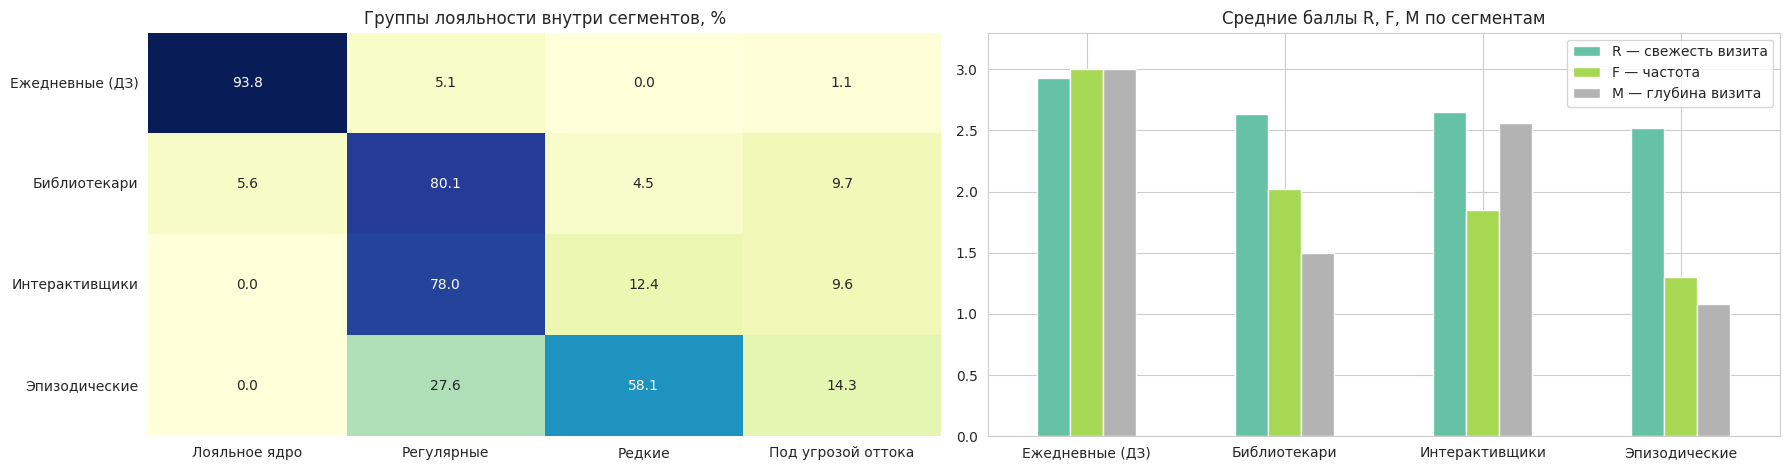

In [13]:
# RFM-анализ: лояльность и активность сегментов.
#
# Классический RFM адаптирован к платформе без платежей:
#   R (recency)   — давность последнего визита, но не в днях, а относительно
#                   собственного ритма учителя: пауза в 5 дней тревожна для
#                   того, кто заходит ежедневно, и нормальна для того, кто
#                   заходит раз в неделю. R = давность / средняя пауза
#                   между активными днями;
#   F (frequency) — активных дней в месяц;
#   M (monetary)  — денег в логе нет, поэтому ценность визита измеряем
#                   его глубиной: событий в активный день.
# Баллы 1–3 задаём продуктовыми порогами, а не квантилями: у давности
# больше трети учителей с нулём, и квантили разрезали бы одинаковые
# значения случайно, а пороги в днях и визитах понятны продуктовой команде.

rfm = feat[['segment', 'recency_days', 'gap_mean_days', 'active_days_month',
            'events_per_day']].copy()

# Учителям с одним активным днём ритм неизвестен — считаем его ежедневным,
# то есть оцениваем давность строго (консервативное допущение).
rfm['r_ratio'] = rfm['recency_days'] / rfm['gap_mean_days'].fillna(1)

# R: пауза в пределах обычного ритма — 3; до двух обычных пауз — 2;
#    больше двух обычных пауз — 1 (учитель «пропустил» визиты).
rfm['R'] = pd.cut(rfm['r_ratio'], [-np.inf, 1, 2, np.inf], labels=[3, 2, 1]).astype(int)
# F: реже 6 дней в месяц (около раза в неделю и реже) — 1; 6–14 — 2;
#    15 и больше (через день и чаще) — 3.
rfm['F'] = pd.cut(rfm['active_days_month'], [0, 6, 15, np.inf],
                  labels=[1, 2, 3], right=False).astype(int)
# M: меньше 2.5 событий за визит — 1; 2.5–4 — 2; 4 и больше — 3.
rfm['M'] = pd.cut(rfm['events_per_day'], [0, 2.5, 4, np.inf],
                  labels=[1, 2, 3], right=False).astype(int)
rfm['RFM'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)
rfm['score'] = rfm[['R', 'F', 'M']].sum(axis=1)

# Группы лояльности для коммуникаций.
def loyalty_group(row):
    if row['R'] == 1:
        return 'Под угрозой оттока'
    if row['R'] == 3 and row['F'] == 3:
        return 'Лояльное ядро'
    if row['F'] >= 2:
        return 'Регулярные'
    return 'Редкие'

LOYALTY = ['Лояльное ядро', 'Регулярные', 'Редкие', 'Под угрозой оттока']
rfm['loyalty'] = rfm.apply(loyalty_group, axis=1)
for src, dst in [('R', 'R'), ('F', 'F'), ('M', 'M'), ('RFM', 'RFM'),
                 ('score', 'rfm_score'), ('loyalty', 'loyalty')]:
    feat[dst] = rfm[src]

print('Распределение баллов R, F, M (число учителей):')
display(pd.DataFrame({c: rfm[c].value_counts().sort_index() for c in ['R', 'F', 'M']}))

# Проверка смысла R: сравним с абсолютной давностью.
print('Давность последнего визита, дней (медиана) по баллу R:',
      rfm.groupby('R')['recency_days'].median().to_dict())

print('\nГруппы лояльности:')
lg = rfm['loyalty'].value_counts().reindex(LOYALTY)
display(pd.DataFrame({'учителей': lg, 'доля, %': (lg / len(rfm) * 100).round(1)}))

# --- Сегменты против RFM ---
seg_rfm = rfm.groupby('segment')[['R', 'F', 'M', 'score']].mean().reindex(SEGMENTS)
print('Средние баллы R, F, M и суммарный балл (3–9) по сегментам:')
display(seg_rfm.round(2))

loyal_ct = (pd.crosstab(rfm['segment'], rfm['loyalty'], normalize='index') * 100)
loyal_ct = loyal_ct.reindex(index=SEGMENTS, columns=LOYALTY, fill_value=0)
print('Состав сегментов по группам лояльности, % учителей сегмента:')
display(loyal_ct.round(1))

print('Самые частые RFM-коды в каждом сегменте:')
for s in SEGMENTS:
    top = rfm.loc[rfm['segment'] == s, 'RFM'].value_counts(normalize=True).head(3) * 100
    print(f'  {s:<17} ' + ', '.join(f'{code} — {v:.0f}%' for code, v in top.items()))

fig, axes = plt.subplots(1, 2, figsize=(18, 4.8))
sns.heatmap(loyal_ct, annot=True, fmt='.1f', cmap='YlGnBu', ax=axes[0], cbar=False)
axes[0].set_title('Группы лояльности внутри сегментов, %')
axes[0].set_xlabel('')
axes[0].set_ylabel('')

seg_rfm[['R', 'F', 'M']].plot.bar(ax=axes[1], rot=0, colormap='Set2')
axes[1].set_title('Средние баллы R, F, M по сегментам')
axes[1].set_ylim(0, 3.3)
axes[1].set_xlabel('')
axes[1].legend(['R — свежесть визита', 'F — частота', 'M — глубина визита'])
plt.tight_layout()
plt.show()

### Выводы по RFM-анализу

**Персональная давность работает как задумано.** Медианная давность
последнего визита: 0 дней у учителей с R = 3, 5 дней при R = 2 и 10 дней
при R = 1. Балл R = 1 означает, что учитель пропустил больше двух своих
обычных интервалов между визитами.

**Группы лояльности:**

| Группа | Правило | Учителей | Доля |
|---|---|---|---|
| Лояльное ядро | R = 3 и F = 3 | 452 | 30.1% |
| Регулярные | R ≥ 2, F ≥ 2 (кроме ядра) | 714 | 47.6% |
| Редкие | R ≥ 2, F = 1 | 214 | 14.3% |
| Под угрозой оттока | R = 1 | 120 | 8.0% |

**Сегменты и лояльность:**

| Сегмент | Сумма баллов (3–9) | Лояльное ядро | Регулярные | Редкие | Под угрозой оттока | Типичный RFM-код |
|---|---|---|---|---|---|---|
| Ежедневные (ДЗ) | **8.93** | 93.8% | 5.1% | 0% | 1.1% (5 учителей) | 333 у 94% |
| Библиотекари | 6.15 | 5.6% | 80.1% | 4.5% | 9.7% (54) | 322, 321 |
| Интерактивщики | 7.06 | 0% | 78.0% | 12.4% | 9.6% (21) | 323, 322 |
| Эпизодические | 4.90 | 0% | 27.6% | 58.1% | **14.3%** (40) | 311 |

- **RFM независимо подтверждает сегментацию.** Лояльное ядро почти
  целиком совпадает с «Ежедневными»: у 94% сегмента код 333 — максимум
  по всем трём измерениям.
- **«Интерактивщики» ценнее «Библиотекарей» по сумме баллов** (7.06
  против 6.15) за счёт глубины визита (M = 2.56 против 1.50), хотя заходят
  чуть реже (F = 1.85 против 2.02). Визит интерактивщика короткий
  по времени, но насыщенный действиями.
- **Отток угрожает в первую очередь «Библиотекарям».** По доле лидируют
  «Эпизодические» (14.3%), но в абсолютных числах больше всего учителей
  под угрозой среди «Библиотекарей»: 54 из 120, то есть 45% всех
  учителей в группе риска. Это крупный сегмент со средней частотой,
  в котором выпадение из ритма легко пропустить.
- **Персональная давность точнее абсолютной.** Среди «Эпизодических» 31%
  не заходили 7+ дней. Но дольше двух своих обычных интервалов
  отсутствуют только 14%. Для остальных пауза — норма их ритма.
  Если запускать реактивацию по абсолютному порогу, сообщения получат
  вдвое больше учителей, и половина из них получит лишнее.

**Ограничение.** Давность измерена на одну дату — конец выгрузки. Для
мониторинга оттока RFM-баллы нужно пересчитывать регулярно (например,
ежедневно) и реагировать на переход учителя в R = 1.

## 8. Классификатор сегмента для новых учителей

Учителей с полным окном 21 дней: 1493 из 1500

Качество на кросс-валидации (обучающая часть), macro F1:


"окно, дней",3,7,14,21
модель,,,,
K-Means без обучения (ближайший центр),0.755,0.837,0.891,0.942
Дерево решений (глубина 4),0.757,0.853,0.903,0.952
Константная (самый частый сегмент),0.135,0.135,0.135,0.135
Логистическая регрессия,0.769,0.877,0.924,0.951
Случайный лес,0.799,0.874,0.916,0.950


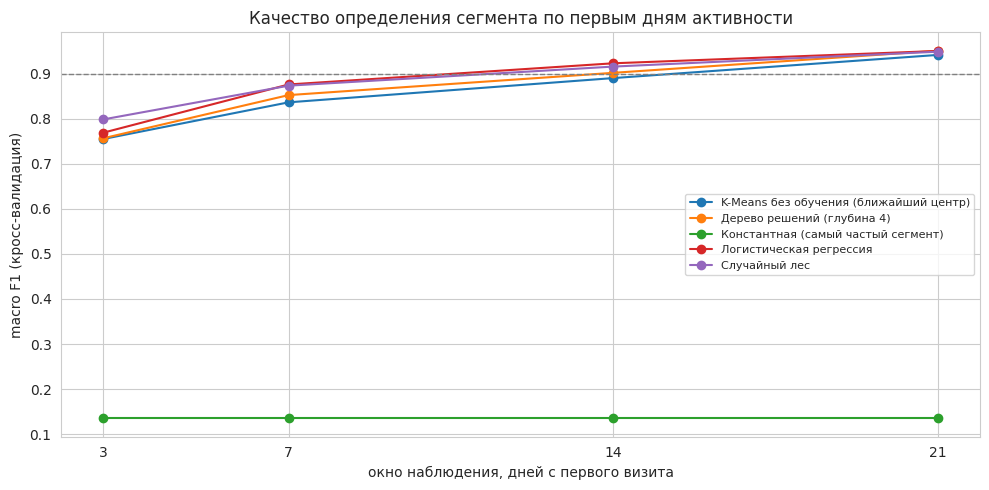

Выбрано окно 14 дней, модель: Логистическая регрессия (macro F1 на кросс-валидации 0.924)

Тест (374 учителей): accuracy 0.957, macro F1 0.957
                 precision    recall  f1-score   support

Ежедневные (ДЗ)      1.000     1.000     1.000       112
   Библиотекари      0.956     0.928     0.942       139
 Интерактивщики      1.000     1.000     1.000        55
  Эпизодические      0.861     0.912     0.886        68

       accuracy                          0.957       374
      macro avg      0.954     0.960     0.957       374
   weighted avg      0.958     0.957     0.958       374



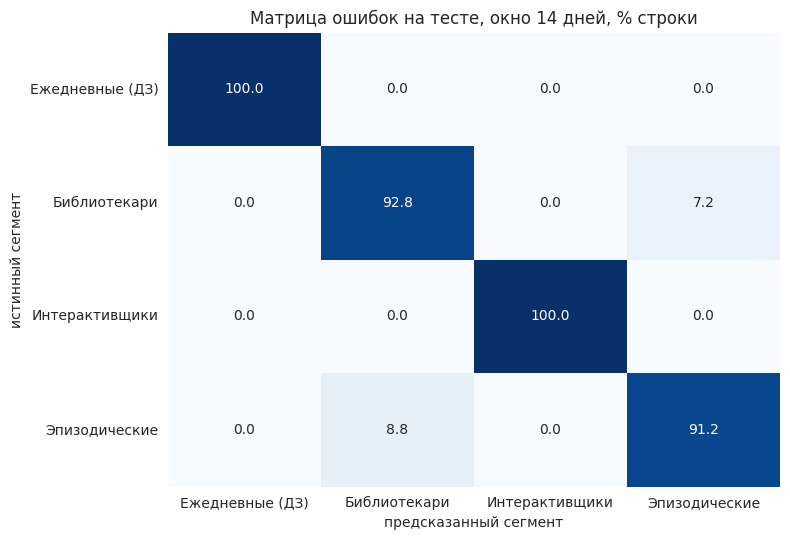

Дерево глубины 3 на тесте: accuracy 0.925, macro F1 0.916
|--- share_hw <= 0.40
|   |--- share_lib <= 0.35
|   |   |--- events_per_day <= 3.07
|   |   |   |--- class: Эпизодические
|   |   |--- events_per_day >  3.07
|   |   |   |--- class: Интерактивщики
|   |--- share_lib >  0.35
|   |   |--- active_days_month <= 5.36
|   |   |   |--- class: Эпизодические
|   |   |--- active_days_month >  5.36
|   |   |   |--- class: Библиотекари
|--- share_hw >  0.40
|   |--- active_days_month <= 11.79
|   |   |--- share_lib <= 0.12
|   |   |   |--- class: Эпизодические
|   |   |--- share_lib >  0.12
|   |   |   |--- class: Эпизодические
|   |--- active_days_month >  11.79
|   |   |--- class: Ежедневные (ДЗ)



In [14]:
# Классификатор сегмента для новых учителей.
#
# Продуктовая задача: персонализировать кабинет нужно как можно раньше,
# а не через 45 дней наблюдений. Поэтому модель учится определять итоговый
# сегмент учителя по его первым W дням на платформе (считая от первого
# активного дня — так, как это выглядело бы для нового пользователя).
# Признаки окна — те же 7 продуктовых метрик, посчитанные только по событиям
# первых W дней; целевая переменная — сегмент по полным 45 дням.

WINDOWS = [3, 7, 14, 21]
first_day = clean.groupby('user_id')['date'].min()

def window_features(w):
    """Продуктовые метрики учителя за первые w дней с первого активного дня."""
    lw = clean.merge(first_day.rename('d0'), left_on='user_id', right_index=True)
    lw = lw[lw['date'] < lw['d0'] + pd.Timedelta(days=w)]
    g_w = lw.groupby('user_id')
    f = pd.DataFrame({
        'active_days_month': g_w['date'].nunique() / w * 30,
        'events_per_day': g_w.size() / g_w['date'].nunique(),
    })
    mc = pd.crosstab(lw['user_id'], lw['module']).reindex(columns=MODULES, fill_value=0)
    sh = mc.div(mc.sum(axis=1), axis=0)
    sh.columns = SHARE_COLS
    return f.join(sh)[FEATURES]

# Для честного сравнения окон берём учителей, у которых в выгрузке
# помещается самое длинное окно (первый визит не позже чем за 21 день до конца).
eligible = first_day[first_day <= END_DATE - pd.Timedelta(days=max(WINDOWS) - 1)].index
y_all = feat.loc[eligible, 'segment']
print(f'Учителей с полным окном {max(WINDOWS)} дней: {len(eligible)} из {len(feat)}')

# Отложенная выборка — 25%, стратифицированно по сегменту. Модели и окно
# выбираем по кросс-валидации на обучающей части, тест — только в конце.
ids_train, ids_test = train_test_split(eligible, test_size=0.25, stratify=y_all,
                                       random_state=RANDOM_STATE)
y_train, y_test = y_all.loc[ids_train], y_all.loc[ids_test]

clf_models = {
    'Константная (самый частый сегмент)': DummyClassifier(strategy='most_frequent'),
    'Логистическая регрессия': make_pipeline(StandardScaler(),
                                             LogisticRegression(max_iter=2000)),
    'Дерево решений (глубина 4)': DecisionTreeClassifier(max_depth=4,
                                                         random_state=RANDOM_STATE),
    'Случайный лес': RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            random_state=RANDOM_STATE, n_jobs=-1),
}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rows, win_X = [], {}
for w in WINDOWS:
    Xw = window_features(w)
    win_X[w] = Xw
    X_tr = Xw.loc[ids_train]
    # Базовый вариант без обучения: применить уже обученный K-Means
    # к метрикам первых дней (ближайший центр сегмента).
    km_pred = pd.Series(km_final.predict(scaler.transform(X_tr)),
                        index=X_tr.index).map(name_map)
    rows.append({'окно, дней': w, 'модель': 'K-Means без обучения (ближайший центр)',
                 'accuracy': accuracy_score(y_train, km_pred),
                 'macro F1': f1_score(y_train, km_pred, average='macro')})
    for name, model in clf_models.items():
        pred = cross_val_predict(model, X_tr, y_train, cv=skf)
        rows.append({'окно, дней': w, 'модель': name,
                     'accuracy': accuracy_score(y_train, pred),
                     'macro F1': f1_score(y_train, pred, average='macro')})

clf_scan = pd.DataFrame(rows)
print('\nКачество на кросс-валидации (обучающая часть), macro F1:')
display(clf_scan.pivot(index='модель', columns='окно, дней', values='macro F1').round(3))

fig, ax = plt.subplots(figsize=(10, 5))
for name, d in clf_scan.groupby('модель'):
    ax.plot(d['окно, дней'], d['macro F1'], marker='o', label=name)
ax.axhline(0.9, color='grey', ls='--', lw=1)
ax.set_xticks(WINDOWS)
ax.set_title('Качество определения сегмента по первым дням активности')
ax.set_xlabel('окно наблюдения, дней с первого визита')
ax.set_ylabel('macro F1 (кросс-валидация)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Выбор окна и модели ---
# Правило: самое короткое окно, на котором лучшая модель даёт macro F1 >= 0.9
# (продукту важнее скорость персонализации, чем последние проценты точности).
best_by_w = (clf_scan[~clf_scan['модель'].str.startswith('Константная')]
             .sort_values('macro F1', ascending=False).groupby('окно, дней').head(1)
             .set_index('окно, дней').sort_index())
ok_w = best_by_w[best_by_w['macro F1'] >= 0.9]
W_BEST = int(ok_w.index.min()) if len(ok_w) else int(best_by_w['macro F1'].idxmax())
best_name = best_by_w.loc[W_BEST, 'модель']
print(f'Выбрано окно {W_BEST} дней, модель: {best_name} '
      f'(macro F1 на кросс-валидации {best_by_w.loc[W_BEST, "macro F1"]:.3f})')

# --- Проверка на отложенной выборке ---
X_tr, X_te = win_X[W_BEST].loc[ids_train], win_X[W_BEST].loc[ids_test]
if best_name.startswith('K-Means'):
    test_pred = pd.Series(km_final.predict(scaler.transform(X_te)),
                          index=X_te.index).map(name_map)
else:
    final_clf = clf_models[best_name].fit(X_tr, y_train)
    test_pred = final_clf.predict(X_te)
print(f'\nТест ({len(ids_test)} учителей): accuracy {accuracy_score(y_test, test_pred):.3f}, '
      f'macro F1 {f1_score(y_test, test_pred, average="macro"):.3f}')
print(classification_report(y_test, test_pred, labels=SEGMENTS, digits=3))

cm = pd.DataFrame(confusion_matrix(y_test, test_pred, labels=SEGMENTS, normalize='true') * 100,
                  index=SEGMENTS, columns=SEGMENTS)
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(cm, annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax)
ax.set_title(f'Матрица ошибок на тесте, окно {W_BEST} дней, % строки')
ax.set_xlabel('предсказанный сегмент')
ax.set_ylabel('истинный сегмент')
plt.tight_layout()
plt.show()

# --- Простые правила для продукта ---
# Неглубокое дерево (3 уровня) можно реализовать прямо в продукте как
# набор правил «если — то», без ML-инфраструктуры. Проверяем, сколько
# точности теряем ради такой простоты.
rules_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_tr, y_train)
rules_pred = rules_tree.predict(X_te)
print(f'Дерево глубины 3 на тесте: accuracy {accuracy_score(y_test, rules_pred):.3f}, '
      f'macro F1 {f1_score(y_test, rules_pred, average="macro"):.3f}')
print(export_text(rules_tree, feature_names=FEATURES, decimals=2))

### Выводы по классификатору

**Качество на кросс-валидации, macro F1:**

| Модель | 3 дня | 7 дней | 14 дней | 21 день |
|---|---|---|---|---|
| Константная (самый частый сегмент) | 0.135 | 0.135 | 0.135 | 0.135 |
| K-Means без обучения (ближайший центр) | 0.755 | 0.837 | 0.891 | 0.942 |
| Дерево решений (глубина 4) | 0.757 | 0.853 | 0.903 | **0.952** |
| Логистическая регрессия | 0.769 | **0.877** | **0.924** | 0.951 |
| Случайный лес | **0.799** | 0.874 | 0.916 | 0.950 |

- **Двух недель достаточно.** Окно в 14 дней — самое короткое, на котором
  качество превышает порог 0.9 (логистическая регрессия, 0.924).
  За 21 день качество растёт до 0.95, но персонализация откладывается
  ещё на неделю. После 7 дней (0.877) сегмент можно присвоить
  предварительно и подтвердить на 14-й день. Трёх дней мало: не больше 0.80.
- **Обучение на коротком окне даёт прирост.** Готовый K-Means, применённый
  к метрикам первых двух недель, даёт 0.891. Обученные модели (0.92)
  учитывают, что метрики короткого окна шумнее, чем за 45 дней.
- **Модели сопоставимы.** На 14 днях разница между логистической
  регрессией, лесом и деревом — 0.02. Выбрана логистическая регрессия:
  она лучшая на кросс-валидации и самая простая во внедрении.

**Проверка на отложенной выборке (374 учителя, окно 14 дней):**
accuracy 0.957, macro F1 0.957.

| Сегмент | Precision | Recall |
|---|---|---|
| Ежедневные (ДЗ) | 1.000 | 1.000 |
| Библиотекари | 0.956 | 0.928 |
| Интерактивщики | 1.000 | 1.000 |
| Эпизодические | 0.861 | 0.912 |

Качество на тесте не ниже, чем на кросс-валидации, то есть модель
не переобучена. «Ежедневных» и «Интерактивщиков» модель определяет
без ошибок. Путаются только «Библиотекари» и «Эпизодические»: 7.2%
библиотекарей приняты за эпизодических, 8.8% эпизодических — за
библиотекарей. Эти сегменты различаются прежде всего частотой визитов,
и библиотекарь, зашедший за две недели всего пару раз, выглядит как
эпизодический. Ошибка дешёвая: оба сегмента получают «лёгкие» сценарии,
а ежемесячный пересчёт сегментов её исправит.

**Простые правила для внедрения без ML.** Дерево глубины 3 на тесте:
accuracy 0.925, macro F1 0.916, то есть потеря всего около 3 п. п. Если
перевести пороги из «дней в месяц» в дни окна (× 14 / 30), правила такие:

1. ДЗ — больше 40% событий и не меньше 6 активных дней из 14 →
   «Ежедневные (ДЗ)»;
2. иначе, если библиотека — больше 35% событий и не меньше 3 активных дней
   из 14 → «Библиотекари»;
3. иначе, если библиотека — не больше 35% событий и больше 3 событий
   за визит → «Интерактивщики»;
4. остальные → «Эпизодические».

Правило 3 определяет интерактивщиков по интенсивности визита, а не
по доле вебинаров. Среди тех, кто мало работает с ДЗ и библиотекой,
интенсивные визиты дают именно ведущие вебинаров. В продукте правило
стоит дополнить явным условием на долю вебинаров и проверить его
на данных.

**Ограничение.** «Новые» учителя здесь смоделированы по первым 14 дням
существующих учителей, большинство из которых активны с 1 марта.
Настоящие новички в период онбординга могут вести себя иначе, поэтому
до внедрения модель нужно проверить на реальных новых регистрациях.

## 9. Бизнес-рекомендации

### 9.1. Потенциал роста продуктовых метрик

In [15]:
# Потенциал роста продуктовых метрик по сегментам.
#
# MAU уже на потолке (99.9% учителей), поэтому рост возможен только через
# частоту — активные дни. Связь с DAU прямая: вероятность учителя быть
# активным в конкретный день равна (активных дней в месяц / 30), а DAU —
# сумма этих вероятностей по всем учителям. Значит, +Δ активных дней
# в месяц у n учителей дают + n·Δ / 30 к среднему DAU.
# Это сценарные расчёты («что будет, если»), а не прогноз эффекта:
# реальный прирост нужно измерять A/B-тестами.

MAU = len(feat)
seg_base = (feat.groupby('segment')['active_days_month']
                .agg(учителей='size', дней_в_месяц='mean').reindex(SEGMENTS))
seg_base['вклад в DAU'] = seg_base['учителей'] * seg_base['дней_в_месяц'] / 30
dau_calc = seg_base['вклад в DAU'].sum()
print(f'DAU по формуле: {dau_calc:.0f}; фактический средний DAU: {dau.mean():.0f} — '
      f'формула согласуется с данными')
display(seg_base.round(1))

def scenario(uplift):
    """uplift — прирост активных дней в месяц по сегментам."""
    delta = sum(seg_base.loc[s, 'учителей'] * d / 30 for s, d in uplift.items())
    new_dau = dau_calc + delta
    days_all = (seg_base['учителей'] * seg_base['дней_в_месяц']).sum() / MAU
    return {
        'прирост DAU': delta,
        'DAU': new_dau,
        'изменение DAU, %': delta / dau_calc * 100,
        'активных дней в месяц, среднее': days_all + delta * 30 / MAU,
        'stickiness DAU/MAU, %': new_dau / MAU * 100,
    }

GROWTH = ['Библиотекари', 'Интерактивщики', 'Эпизодические']
scenarios = {'текущее состояние': {}}
for d in [1, 2, 3]:
    scenarios[f'+{d} дн. у трёх растущих сегментов'] = {s: d for s in GROWTH}
for s in GROWTH:
    scenarios[f'+2 дн. только у сегмента «{s}»'] = {s: 2}
scenarios['риск: −2 дн. у «Ежедневных (ДЗ)»'] = {'Ежедневные (ДЗ)': -2}

display(pd.DataFrame({name: scenario(u) for name, u in scenarios.items()}).T.round(1))

DAU по формуле: 646; фактический средний DAU: 646 — формула согласуется с данными


,учителей,дней_в_месяц,вклад в DAU
segment,,,
Ежедневные (ДЗ),449,22.5,336.0
Библиотекари,554,11.4,211.2
Интерактивщики,218,7.6,55.3
Эпизодические,279,4.6,43.1


,прирост DAU,DAU,"изменение DAU, %","активных дней в месяц, среднее","stickiness DAU/MAU, %"
текущее состояние,0.0,645.7,0.0,12.9,43.0
+1 дн. у трёх растущих сегментов,35.0,680.7,5.4,13.6,45.4
+2 дн. у трёх растущих сегментов,70.1,715.7,10.9,14.3,47.7
+3 дн. у трёх растущих сегментов,105.1,750.8,16.3,15.0,50.1
+2 дн. только у сегмента «Библиотекари»,36.9,682.6,5.7,13.7,45.5
+2 дн. только у сегмента «Интерактивщики»,14.5,660.2,2.3,13.2,44.0
+2 дн. только у сегмента «Эпизодические»,18.6,664.3,2.9,13.3,44.3
риск: −2 дн. у «Ежедневных (ДЗ)»,-29.9,615.7,-4.6,12.3,41.0


### Выводы по потенциалу роста

Средний DAU равен сумме по учителям величины «активных дней в месяц / 30»,
поэтому прирост активных дней в сегменте напрямую пересчитывается
в прирост DAU.

| Сценарий | Изменение DAU |
|---|---|
| +1 активный день в месяц у трёх растущих сегментов | +35 (+5.4%) |
| **+2 дня у трёх растущих сегментов** | **+70 (+10.9%)**; stickiness с 43.0% до 47.7%; в среднем по платформе +1.4 активного дня в месяц |
| +3 дня у трёх растущих сегментов | +105 (+16.3%) |
| +2 дня только у «Библиотекарей» | +37 (+5.7%) |
| +2 дня только у «Эпизодических» | +19 (+2.9%) |
| +2 дня только у «Интерактивщиков» | +15 (+2.3%) |
| **Риск: −2 дня у «Ежедневных (ДЗ)»** | **−30 (−4.6%)** |

Из расчёта следуют два вывода:

1. **Главный рычаг роста — «Библиотекари».** Это самый крупный сегмент,
   и +2 дня у них дают больше, чем те же +2 дня у «Интерактивщиков»
   и «Эпизодических» вместе.
2. **Потеря двух дней у «Ежедневных» отменяет почти весь рост двух меньших
   сегментов.** Защита ядра — такой же приоритет, как рост.

### 9.2. Рекомендации по сегментам

| Приоритет | Сегмент | Цель | Потенциал (+2 дн.) |
|---|---|---|---|
| 1 | Ежедневные (ДЗ) | удержание и скорость работы | защита от −4.6% DAU |
| 2 | Библиотекари | от «посмотрел материал» к «выдал задание» | +5.7% DAU |
| 3 | Эпизодические | активация: найти «свой» сценарий | +2.9% DAU и переход в другие сегменты |
| 4 | Интерактивщики | активность между эфирами | +2.3% DAU |

---

#### 1. «Ежедневные практики ДЗ» — защитить ядро

*30% учителей, 69% событий, 52% DAU. Активны уже 23 дня из 30, расти
частоте почти некуда. Задача — чтобы платформа экономила их время.*

- **Личный кабинет.** Стартовый экран — «рабочий стол ДЗ»: очередь
  непроверенных работ, кнопки «выдать ДЗ» и «выставить оценки». Оценку
  стоит ставить прямо из проверки работы: ДЗ и журнал у этих учителей
  идут в связке (ДЗ в 97% активных дней, оценки — в 77%).
- **Продукт.** Шаблоны и повтор заданий, массовая проверка.
  Прикрепление материала из библиотеки прямо в форме ДЗ: библиотеку
  они открывают в 44% дней.
- **Коммуникации.** Минимум маркетинговых рассылок, только новости
  инструментов ДЗ и журнала. Если учитель переходит в R ≤ 2 (выпадает
  из своего ритма), нужен персональный контакт поддержки, а не
  автоматическая рассылка: каждый потерянный учитель — около 23 активных
  дней в месяц.
- **Метрики.** Доля сегмента с R = 3 (сейчас 94%), время от сдачи работы
  до проверки.

#### 2. «Библиотекари» — превратить подготовку к уроку в работу с классом

*37% учителей, но только 20% событий. Библиотека открыта в 86% визитов,
ДЗ и оценки почти не используются.*

- **Личный кабинет.** Стартовый экран — библиотека: поиск, подборки
  по предмету и классу, «продолжить подготовку». Добавить блок
  «материалы к урокам этой недели», связанный с расписанием: расписание
  — 15% их событий.
- **Мост к ДЗ — главный сценарий роста.** Кнопка «выдать как домашнее
  задание» на карточке материала и подсказка после скачивания.
  Выданное ДЗ создаёт повод вернуться — проверить работы. Так
  библиотекарь переходит к ритму «Ежедневных».
- **Коммуникации.** Еженедельный дайджест новых материалов по предмету
  перед началом учебной недели. Реактивация 54 библиотекарей с R = 1:
  это крупнейшая в абсолютных числах группа под угрозой оттока, 45%
  всех таких учителей.
- **Метрики.** Доля библиотекарей, выдавших хотя бы одно ДЗ из материала;
  активные дни в месяц (цель — 12 → 14).

#### 3. «Эпизодические» — помочь найти свой сценарий

*19% учителей, 3% событий. Заходят около раза в неделю ненадолго,
доминирующего модуля нет, 31% не заходили 7+ дней.*

- **Личный кабинет.** Упрощённый стартовый экран с тремя входами:
  «выдать ДЗ», «найти материал к уроку», «провести вебинар», то есть
  по сценариям трёх других сегментов. Виджет расписания оставить
  на виду: расписание — самая частая причина их визита (22% событий).
- **Коммуникации.** Онбординговая серия из 3–4 сообщений, каждое показывает
  один сценарий. Реактивацию запускать по персональной давности (R = 1),
  а не по абсолютным 7 дням паузы. Иначе сообщения получат вдвое больше
  учителей (31% вместо 14%), и для половины из них пауза — нормальный
  ритм.
- **Классификатор.** Новых учителей, которые через 14 дней остаются
  «Эпизодическими», направлять в трек активации.
- **Метрики.** Доля учителей, перешедших в другие сегменты за 30 дней;
  активные дни в месяц (цель — 4.7 → 6.7).

#### 4. «Интерактивщики» — продлить жизнь вебинара

*15% учителей. Вебинар есть в 92% визитов, расписание — в 48%. Заходят
около 2 раз в неделю, но насыщенно: 4 действия за визит.*

- **Личный кабинет.** Стартовый экран — «студия»: ближайшие эфиры,
  кнопка запуска, расписание эфиров (расписание открывается
  почти в каждом втором визите).
- **Продукт.** После эфира — запись и предложение выдать ДЗ или материалы
  по теме вебинара. Это создаёт поводы для визитов между эфирами:
  проверить работы, ответить ученикам. Шаблоны серий вебинаров.
- **Коммуникации.** Напоминание перед эфиром и сводка после. Реактивация
  21 учителя с R = 1.
- **Метрики.** Доля вебинаров, после которых выдано ДЗ; активные дни
  в месяц (цель — 7.3 → 9.3).

---

#### Общие рекомендации

1. **Регулярный пересчёт сегментов.** Ежемесячно пересчитывать метрики
   по скользящему окну 45 дней и размечать учителей обученной моделью
   (`scaler` + `km_final.predict`). Отслеживать переходы между
   сегментами — это главная метрика успеха персонализации.
2. **Новые учителя.** Предварительный сегмент через 7 дней (macro F1
   0.88), подтверждённый — через 14 (0.96). Модель или четыре правила
   дерева можно внедрить без ML-инфраструктуры.
3. **Ежедневный RFM-мониторинг.** Триггер реактивации — переход учителя
   в R = 1 (пауза больше двух обычных интервалов).
4. **Каждую рекомендацию проверять A/B-тестом** с метрикой «активные дни
   в месяц». Расчёты в 9.1 — сценарии, а не прогноз эффекта.
5. **Региональная адаптация не нужна.** Состав сегментов от региона
   не зависит (p = 0.51).
6. **Исправить логирование:**
   - `session_id` не отражает визит (у учителя 4 «сессии» за 45 дней,
     и половина из них общие для двух учителей) — нужен настоящий
     идентификатор сессии;
   - у 6% событий не записывается модуль;
   - служебные аккаунты не помечены и дают 44% лога — нужен флаг
     служебного аккаунта;
   - у учителей время записано с точностью до минуты, что порождает
     неразличимые дубликаты.

## 10. Общий вывод

### Что было сделано

**Данные.** Лог платформы за 45 дней (1 марта — 14 апреля 2026 года):
214 959 событий, 1 515 аккаунтов, 9 типов событий в 5 модулях.

**Очистка.**

- **Исключены 15 служебных BOT-аккаунтов** — 94 291 событие, 43.9% лога.
  По поведению это скрипты, а не люди: равномерная активность круглые
  сутки, событие примерно каждые 7 минут, одна общая сессия, время
  с точностью до секунды.
- **Парсеров среди учителей не найдено.** Робастная z-оценка не выделила
  ни одного аномально активного учителя.
- **Восстановлены 7 102 пропуска модуля** — по однозначному соответствию
  «тип события → модуль».
- **Удалена 71 дублирующая запись.**
- **Особенности полей.** `session_id` не описывает визит (сессии длятся
  неделями и бывают общими для двух учителей), а `school_id` — номер
  школы внутри региона, а не глобальный идентификатор.

Итог: 120 597 событий 1 500 учителей, ни один учитель не потерян.

**Продуктовые метрики платформы.** MAU — 99.9% учителей, DAU — 646 (43%),
stickiness — 43%, в среднем 13.3 активных дня в месяц (медиана 12),
недельное удержание — 91–93% без снижения.

**Признаки.** Семь продуктовых метрик:

- регулярность — активные дни в месяц;
- интенсивность — событий за визит;
- структура использования — доли пяти модулей.

Признаки, дублирующие эти (ρ ≥ 0.86) или неотличимые от случайности
(ритм визитов, доля выходных), исключены после проверки. Единица визита —
активный день: восстановить сессии по паузам не удалось, отдельной
группы коротких пауз нет.

**Кластеризация.**

- **K-Means.** Перебор k от 2 до 10. Метод локтя, силуэт (0.597)
  и индекс Калински — Харабаша сошлись на k = 4. Разбиение устойчиво
  (ARI 0.996 на 20 подвыборках). k = 5 отклонено: пятый кластер — шумовое
  деление малоактивных учителей.
- **DBSCAN.** Сетка из 80 конфигураций, eps подобран по графику
  k-расстояний: 3 кластера и 9.5% шума. Без заданного числа кластеров
  DBSCAN нашёл те же три основных сегмента (совпадение 97–100%).
- **Итоговая модель — K-Means.** Она размечает всех учителей, отдельно
  выделяет малоактивных, устойчивее и умеет размечать новых учителей.

**Дополнительно.**

- RFM-анализ с давностью визита относительно личного ритма учителя.
- Классификатор сегмента нового учителя по первым 14 дням: accuracy 0.957
  на отложенной выборке. Есть и упрощённый вариант из 4 правил
  с точностью 0.925.

### Сегменты учителей

| Сегмент | Учителей | Активных дней в месяц | Событий за визит | Сценарий | Доля DAU | Под угрозой оттока |
|---|---|---|---|---|---|---|
| **Ежедневные (ДЗ)** | 449 (30%) | 22.7 | 5.5 | цикл «задал — проверил — оценил» | 52% | 1% |
| **Библиотекари** | 554 (37%) | 12.0 | 2.5 | материалы для подготовки очных уроков | 33% | 10% |
| **Интерактивщики** | 218 (15%) | 7.3 | 4.0 | вебинары и трансляции | 9% | 10% |
| **Эпизодические** | 279 (19%) | 4.7 | 2.0 | нет устойчивого сценария | 7% | 14% |

Три сегмента точно совпадают с группами учителей из описания продукта.
Четвёртый — не отдельный тип использования, а состояние низкой
вовлечённости. Сегменты различаются и по метрикам, не участвовавшим
в модели (давность визита, объём, охват модулей), и не зависят
от региона (p = 0.51).

### Ключевые выводы для продукта

1. **Активность платформы держится на ядре.** 30% учителей («Ежедневные»)
   дают 69% событий и 52% DAU. Если они потеряют всего 2 активных дня
   в месяц, DAU снизится на 4.6%.
2. **MAU на потолке, расти можно только за счёт частоты.** +2 активных дня
   в месяц у трёх растущих сегментов дают +70 к DAU (+10.9%)
   и stickiness 47.7% вместо 43%.
3. **Главный рычаг роста — «Библиотекари».** Это крупнейший сегмент: +2 дня
   у них дают +5.7% DAU, больше, чем у двух других растущих сегментов
   вместе. Ключевой сценарий — «материал из библиотеки → домашнее задание».
4. **Отток стоит отслеживать по личному ритму, а не по абсолютной паузе.**
   Под угрозой 120 учителей (8%), из них 45% — «Библиотекари». Абсолютный
   порог в 7 дней вдвое завысил бы группу риска среди «Эпизодических».
5. **Сегмент нового учителя определяется за 2 недели** с точностью 96%.
   Персонализацию можно включать уже на этапе онбординга.

### Рекомендации (подробно — в разделе 9.2)

1. **Ежедневные** — защитить ядро: рабочий стол ДЗ, оценка прямо
   из проверки, шаблоны заданий, персональная поддержка при выпадении
   из ритма.
2. **Библиотекари** — мост от библиотеки к ДЗ: «выдать материал как
   задание», материалы к урокам недели, реактивация 54 учителей
   под угрозой оттока.
3. **Эпизодические** — активация: стартовый экран с тремя сценариями,
   онбординговая серия, трек активации для новых учителей, которые
   через 14 дней остаются эпизодическими.
4. **Интерактивщики** — жизнь после эфира: запись и ДЗ по теме вебинара
   как поводы для визитов между эфирами.
5. **Для всех сегментов** — ежемесячный пересчёт сегментов, ежедневный
   RFM-мониторинг, A/B-тест каждой рекомендации по метрике «активные дни
   в месяц», исправление логирования (`session_id`, пропуски модуля,
   флаг служебных аккаунтов).

### Ограничения и развитие

- **Период.** 45 дней не покрывают сезонность учебного года (каникулы,
  конец четверти). Активность учителей в выгрузке равномерна по часам
  и дням недели, что для школы нетипично. Сегментацию стоит перепроверить
  на более длинном периоде.
- **Нет данных об учениках.** Неизвестны результаты ДЗ и посещаемость
  вебинаров, поэтому ценность сценариев для учеников не оценена.
- **Сегменты — снимок поведения.** Модель нужно пересчитывать ежемесячно,
  а классификатор — проверить на реальных новых регистрациях до внедрения.
- **Сценарии в 9.1 — не прогноз.** Эффект каждой рекомендации
  подтверждается A/B-тестом.
- **Развитие.** Признаки последовательностей действий (например, «выдал
  ДЗ → проверил через N дней»), данные учеников, дашборд мониторинга
  переходов между сегментами.